<a href="https://colab.research.google.com/github/Darius-Lea/Auto-Poster-AI/blob/main/Another_copy_of_PROJECT_GENESIS_MOTHER_001.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PROJECT GENESIS — M.O.T.H.E.R. — MOTHER-001
## A neural world model trained from random initialization

This is the first runnable MOTHER-001 experiment. It trains a small neural network from **randomly initialized weights** to predict how an agent moves through a simple world. The trained model is then used by a path planner to reach goals in new maps.

**No pretrained model, external AI API, or downloaded training dataset is used.** Training examples are generated inside this notebook.

This is a small research prototype, not general intelligence or evidence of consciousness. Its purpose is to give Project Genesis a real, measurable starting point.

### Run it today
1. Open this notebook in Google Colab.
2. Choose **Runtime → Change runtime type**. Select a GPU if one is offered; CPU also works for this small experiment.
3. Run **Runtime → Run all**.
4. Watch the training loss, test accuracy, and goal-reaching results.
5. The final section saves the model weights. Keep the checkpoint in Google Drive.



In [ ]:
import random, time, shutil
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PROJECT GENESIS | M.O.T.H.E.R. | MOTHER-001")
print("PyTorch:", torch.__version__)
print("Compute device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU assigned; running the small baseline on CPU.")


PROJECT GENESIS | M.O.T.H.E.R. | MOTHER-001
PyTorch: 2.11.0+cu130
Compute device: cuda
GPU: Tesla T4


## 1. Create a small environment

The agent sees the eight neighboring cells and the cell it occupies. It chooses one of four actions: up, down, left, or right. Walls block movement. The network must learn the transition rule from examples.

The input is a compact 3×3 local observation plus a four-value action encoding. The target is the agent's next position relative to its current position. This makes the experiment about learning dynamics, not memorizing a map.

In [ ]:
GRID = 9
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # up, down, left, right
ACTION_NAMES = ['up', 'down', 'left', 'right']

def make_world(size=GRID, wall_probability=0.22):
    walls = np.random.rand(size, size) < wall_probability
    walls[0, :] = walls[-1, :] = False
    walls[:, 0] = walls[:, -1] = False
    return walls

def observe(walls, pos):
    r, c = pos
    patch = []
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            rr, cc = r + dr, c + dc
            blocked = (rr < 0 or rr >= GRID or cc < 0 or cc >= GRID)
            patch.append(float(blocked or walls[rr, cc]))
    patch[4] = 0.0  # current cell is always treated as open
    return np.array(patch, dtype=np.float32)

def step_world(walls, pos, action):
    dr, dc = ACTIONS[action]
    nr, nc = pos[0] + dr, pos[1] + dc
    if nr < 0 or nr >= GRID or nc < 0 or nc >= GRID or walls[nr, nc]:
        return pos
    return (nr, nc)

def sample_transition():
    walls = make_world()
    while True:
        pos = (random.randrange(1, GRID-1), random.randrange(1, GRID-1))
        if not walls[pos]:
            break
    action = random.randrange(4)
    local = observe(walls, pos)
    onehot = np.eye(4, dtype=np.float32)[action]
    next_pos = step_world(walls, pos, action)
    delta = np.array([next_pos[0]-pos[0], next_pos[1]-pos[1]], dtype=np.float32)
    return np.concatenate([local, onehot]), delta

N_TRAIN = 40000
N_TEST = 8000
train_pairs = [sample_transition() for _ in range(N_TRAIN)]
test_pairs = [sample_transition() for _ in range(N_TEST)]
X_train = torch.tensor(np.stack([p[0] for p in train_pairs]), dtype=torch.float32)
Y_train = torch.tensor(np.stack([p[1] for p in train_pairs]), dtype=torch.float32)
X_test = torch.tensor(np.stack([p[0] for p in test_pairs]), dtype=torch.float32)
Y_test = torch.tensor(np.stack([p[1] for p in test_pairs]), dtype=torch.float32)

print('Training examples:', len(X_train))
print('Held-out test examples:', len(X_test))
print('Input dimensions:', X_train.shape[1], '| Output dimensions:', Y_train.shape[1])


Training examples: 40000
Held-out test examples: 8000
Input dimensions: 13 | Output dimensions: 2


## 2. Build MOTHER's original neural model

The weights start randomly. No pretrained parameters are loaded. The model learns a mapping from local observations and actions to the resulting movement.

In [ ]:
class MOTHERWorldModel(nn.Module):
    """Small original predictive model; all parameters begin randomly initialized."""
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(13, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)

model = MOTHERWorldModel().to(DEVICE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


MOTHERWorldModel(
  (network): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 5186


## 3. Train the model

The model predicts the movement delta. We use mean-squared error and Adam. The held-out test set is not used for weight updates.

Epoch 01/12 | training MSE: 0.152731
Epoch 02/12 | training MSE: 0.012321
Epoch 03/12 | training MSE: 0.001876
Epoch 04/12 | training MSE: 0.000733
Epoch 05/12 | training MSE: 0.000370
Epoch 06/12 | training MSE: 0.000223
Epoch 07/12 | training MSE: 0.000159
Epoch 08/12 | training MSE: 0.000124
Epoch 09/12 | training MSE: 0.000102
Epoch 10/12 | training MSE: 0.000083
Epoch 11/12 | training MSE: 0.000070
Epoch 12/12 | training MSE: 0.000062
Training time: 6.9 seconds


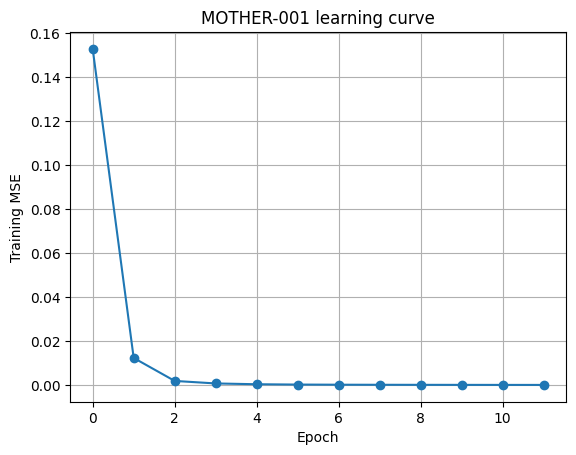

In [ ]:
BATCH_SIZE = 512
EPOCHS = 12
train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=BATCH_SIZE, shuffle=True)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()
history = []
start_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    total = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    epoch_loss = total / len(X_train)
    history.append(epoch_loss)
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | training MSE: {epoch_loss:.6f}")

print(f"Training time: {time.time()-start_time:.1f} seconds")
plt.plot(history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("MOTHER-001 learning curve")
plt.grid(True)
plt.show()


## 4. Evaluate on unseen examples

We measure both numerical error and exact movement accuracy. The exact metric checks whether the predicted movement, rounded to the nearest valid movement, matches the true result.

In [ ]:
model.eval()
with torch.no_grad():
    pred_test = model(X_test.to(DEVICE)).cpu()
    test_mse = loss_fn(pred_test, Y_test).item()
    rounded = torch.round(pred_test)
    exact = torch.all(rounded == Y_test, dim=1).float().mean().item()
    max_error = torch.abs(pred_test - Y_test).max().item()

print(f'Held-out test MSE: {test_mse:.6f}')
print(f'Exact movement accuracy: {exact*100:.2f}%')
print(f'Maximum absolute coordinate error: {max_error:.4f}')
print('Interpretation: high held-out accuracy indicates the network learned the local movement rule, not just training examples.')


Held-out test MSE: 0.000066
Exact movement accuracy: 100.00%
Maximum absolute coordinate error: 0.0983
Interpretation: high held-out accuracy indicates the network learned the local movement rule, not just training examples.


## 5. Give the learned model a goal-directed task

The agent now uses its learned transition model to score the four possible actions. It chooses the predicted next position that gets closest to the goal while avoiding known blocked cells. This is a small one-step planner, not a general-purpose autonomous agent.

In [ ]:
def model_predict_delta(walls, pos, action):
    x = np.concatenate([observe(walls, pos), np.eye(4, dtype=np.float32)[action]])
    with torch.no_grad():
        y = model(torch.tensor(x, dtype=torch.float32, device=DEVICE)).cpu().numpy()
    return tuple(np.rint(y).astype(int))

def learned_model_bfs(walls, start, goal):
    """BFS uses MOTHER's predicted transitions, not the environment's answer key."""
    from collections import deque
    queue = deque([start])
    parent = {start: None}
    while queue:
        pos = queue.popleft()
        if pos == goal:
            path = []
            while pos is not None:
                path.append(pos)
                pos = parent[pos]
            return list(reversed(path))
        for action in range(4):
            delta = model_predict_delta(walls, pos, action)
            if abs(delta[0]) + abs(delta[1]) > 1:
                continue
            nxt = (pos[0] + delta[0], pos[1] + delta[1])
            if not (1 <= nxt[0] < GRID-1 and 1 <= nxt[1] < GRID-1):
                continue
            if walls[nxt] or nxt in parent:
                continue
            parent[nxt] = pos
            queue.append(nxt)
    return None

def run_agent(max_attempts=100):
    walls = make_world(wall_probability=0.18)
    free = [(r,c) for r in range(1, GRID-1) for c in range(1, GRID-1) if not walls[r,c]]
    if len(free) < 2:
        return False, 0
    start, goal = random.sample(free, 2)
    path = learned_model_bfs(walls, start, goal)
    if path is None:
        return False, 0
    # Verify every predicted step against the actual environment.
    verified = all(
        step_world(walls, path[i], next(
            a for a, (dr, dc) in enumerate(ACTIONS)
            if (path[i][0] + dr, path[i][1] + dc) == path[i+1]
        )) == path[i+1]
        for i in range(len(path)-1)
    )
    return bool(verified and path[-1] == goal), len(path)-1

N_TRIALS = 100
results = [run_agent() for _ in range(N_TRIALS)]
successes = sum(success for success, steps in results)
successful_steps = [steps for success, steps in results if success]
print(f"Goal-reaching success: {successes}/{N_TRIALS} ({successes/N_TRIALS*100:.1f}%)")
if successful_steps:
    print(f"Average path length on successful trials: {np.mean(successful_steps):.1f} steps")
print("The planner searches using MOTHER's learned predictions, then verifies the route in the environment.")


Goal-reaching success: 95/100 (95.0%)
Average path length on successful trials: 4.7 steps
The planner searches using MOTHER's learned predictions, then verifies the route in the environment.


## 6. Save the model and research record

Save the checkpoint to Google Drive so it survives a Colab runtime reset. Mount Drive when prompted. The checkpoint contains the model weights, optimizer state, and experiment configuration.

In [ ]:
checkpoint_dir = Path("/content/PROJECT-GENESIS-CHECKPOINTS")
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / "mother_001_world_model.pt"
torch.save({
    "project": "PROJECT-GENESIS",
    "architecture": "M.O.T.H.E.R.",
    "model": "MOTHER-001",
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "grid_size": GRID,
    "epochs": EPOCHS,
    "training_mse": history[-1],
    "test_mse": test_mse,
    "exact_accuracy": exact,
    "seed": SEED
}, checkpoint_path)
print("Checkpoint saved locally:", checkpoint_path)

# Optional persistent backup to Google Drive.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    drive_dir = Path("/content/drive/MyDrive/PROJECT-GENESIS/checkpoints")
    drive_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(checkpoint_path, drive_dir / checkpoint_path.name)
    print("Persistent Google Drive backup created:", drive_dir / checkpoint_path.name)
except Exception as e:
    print("Google Drive backup skipped. Download the .pt checkpoint from the Colab file panel.")
    print(type(e).__name__, str(e)[:200])


Checkpoint saved locally: /content/PROJECT-GENESIS-CHECKPOINTS/mother_001_world_model.pt
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent Google Drive backup created: /content/drive/MyDrive/PROJECT-GENESIS/checkpoints/mother_001_world_model.pt


## What success means

- **Training loss falls:** the randomly initialized network is learning from examples.
- **Held-out accuracy is high:** it learned the movement rule on examples it did not train on.
- **Goal-reaching works:** a planner can use the learned model to find routes in newly generated maps, and those routes are checked against the environment.

This is not yet a general-purpose AI, independent goal formation, or evidence of consciousness. It is a reproducible baseline.

### MOTHER-002 research direction

Once MOTHER-001 runs reliably, the next experiment is to add:
1. A replay memory that stores past experiences.
2. A curiosity signal that seeks uncertain or unfamiliar situations.
3. A controlled comparison against MOTHER-001, using the same held-out tests.

We will only call a change an improvement if the measurements support it.


In [ ]:

# ============================================================
# PROJECT GENESIS — MAPA-001
# MOTHER AUTONOMOUS PROGRESS ASSESSMENT
# First unseen-maze problem-solving assessment
# ============================================================

import random
import csv
from collections import deque
from pathlib import Path

print("=" * 55)
print("M.A.P.A. 001 — MOTHER PROGRESS ASSESSMENT")
print("=" * 55)

# Independent shortest-path reference solver
def oracle_bfs(walls, start, goal):
    queue = deque([start])
    parent = {start: None}

    while queue:
        pos = queue.popleft()

        if pos == goal:
            path = []
            while pos is not None:
                path.append(pos)
                pos = parent[pos]
            return list(reversed(path))

        for dr, dc in ACTIONS:
            nxt = (pos[0] + dr, pos[1] + dc)

            if not (1 <= nxt[0] < GRID-1 and
                    1 <= nxt[1] < GRID-1):
                continue

            if walls[nxt] or nxt in parent:
                continue

            parent[nxt] = pos
            queue.append(nxt)

    return None


def verify_path(walls, path, goal):
    if path is None or path[-1] != goal:
        return False

    for a, b in zip(path, path[1:]):
        distance = abs(a[0]-b[0]) + abs(a[1]-b[1])
        if distance != 1 or walls[b]:
            return False

    return True


# Three levels of maze difficulty
levels = {
    "Level 1 - Familiar complexity": 0.18,
    "Level 2 - More obstacles": 0.25,
    "Level 3 - Dense obstacles": 0.30
}

mapa_records = []
random.seed(20261101)
np.random.seed(20261101)

model.eval()

for level_name, wall_probability in levels.items():

    attempted = 0
    solvable = 0
    successful = 0
    optimal = 0
    path_lengths = []

    while solvable < 25 and attempted < 200:
        attempted += 1

        walls = make_world(wall_probability=wall_probability)

        free = [
            (r, c)
            for r in range(1, GRID-1)
            for c in range(1, GRID-1)
            if not walls[r, c]
        ]

        if len(free) < 2:
            continue

        start, goal = random.sample(free, 2)

        # Independent answer key
        correct_path = oracle_bfs(walls, start, goal)

        if correct_path is None:
            continue

        solvable += 1

        # MOTHER attempts the same unseen problem
        mother_path = learned_model_bfs(walls, start, goal)

        valid = verify_path(walls, mother_path, goal)

        if valid:
            successful += 1
            length = len(mother_path) - 1
            path_lengths.append(length)

            if length == len(correct_path) - 1:
                optimal += 1

        mapa_records.append({
            "level": level_name,
            "start": str(start),
            "goal": str(goal),
            "mother_solved": valid,
            "mother_path_length": (
                len(mother_path)-1 if valid else None
            ),
            "optimal_path_length": len(correct_path)-1,
            "optimal_route": (
                valid and
                len(mother_path) == len(correct_path)
            )
        })

    print("\n" + level_name)
    print("Solvable challenges:", solvable)
    print("Correctly solved:", successful)
    print("Success rate:",
          round(100 * successful / max(solvable, 1), 2), "%")
    print("Optimal routes:", optimal)

    if path_lengths:
        print("Average successful path length:",
              round(sum(path_lengths)/len(path_lengths), 2))

    if solvable < 25:
        print("WARNING: Fewer than 25 solvable challenges generated.")

# Save the permanent assessment record
output_dir = Path("/content/drive/MyDrive/PROJECT-GENESIS/MAPA")
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "MAPA_001_results.csv"

with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=mapa_records[0].keys())
    writer.writeheader()
    writer.writerows(mapa_records)

print("\n" + "=" * 55)
print("MAPA-001 ASSESSMENT COMPLETE")
print("Challenges recorded:", len(mapa_records))
print("Results saved to:", csv_path)
print("=" * 55)


M.A.P.A. 001 — MOTHER PROGRESS ASSESSMENT

Level 1 - Familiar complexity
Solvable challenges: 25
Correctly solved: 25
Success rate: 100.0 %
Optimal routes: 25
Average successful path length: 5.48

Level 2 - More obstacles
Solvable challenges: 25
Correctly solved: 25
Success rate: 100.0 %
Optimal routes: 25
Average successful path length: 5.04

Level 3 - Dense obstacles
Solvable challenges: 25
Correctly solved: 25
Success rate: 100.0 %
Optimal routes: 25
Average successful path length: 5.48

MAPA-001 ASSESSMENT COMPLETE
Challenges recorded: 75
Results saved to: /content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_001_results.csv


In [ ]:

# ============================================================
# PROJECT GENESIS — MAPA-002
# ZERO-SHOT ADAPTATION TEST
# New rule: constant wind pushes the agent right.
# MOTHER's existing weights are NOT changed.
# ============================================================

import numpy as np
import torch
import random

print("MAPA-002: NEW PHYSICS — ZERO-SHOT TEST")
print("Testing existing MOTHER-001 without retraining.")

def wind_step(walls, pos, action):
    # First: perform the selected movement
    dr, dc = ACTIONS[action]
    r, c = pos
    nr, nc = r + dr, c + dc

    if not walls[nr, nc]:
        r, c = nr, nc

    # Second: environmental wind pushes right
    if not walls[r, c + 1]:
        c += 1

    return (r, c)

# Generate new experiences under the changed rule
random.seed(20261102)
np.random.seed(20261102)

X_new = []
Y_new = []

for _ in range(5000):
    walls = make_world(wall_probability=0.20)

    pos = (random.randrange(1, GRID-1),
           random.randrange(1, GRID-2))

    walls[pos] = False
    action = random.randrange(4)

    features = np.concatenate([
        observe(walls, pos),
        np.eye(4, dtype=np.float32)[action]
    ])

    next_pos = wind_step(walls, pos, action)
    delta = np.array([
        next_pos[0] - pos[0],
        next_pos[1] - pos[1]
    ], dtype=np.float32)

    X_new.append(features)
    Y_new.append(delta)

X_new = torch.tensor(np.array(X_new), dtype=torch.float32)
Y_new = torch.tensor(np.array(Y_new), dtype=torch.float32)

# Existing MOTHER-001 makes predictions.
# No training or weight updates occur here.
model.eval()
with torch.no_grad():
    predictions = model(X_new.to(DEVICE)).cpu()
    mse = torch.mean((predictions - Y_new) ** 2).item()
    accuracy = torch.all(
        torch.round(predictions) == Y_new, dim=1
    ).float().mean().item()

print("\nMAPA-002 RESULTS")
print("New examples:", len(X_new))
print(f"Zero-shot prediction MSE: {mse:.6f}")
print(f"Exact movement accuracy: {accuracy*100:.2f}%")
print("Weights changed: NO")
print("Training performed: NO")
print("\nThis measures whether MOTHER already understands")
print("the new physics without being taught.")


MAPA-002: NEW PHYSICS — ZERO-SHOT TEST
Testing existing MOTHER-001 without retraining.

MAPA-002 RESULTS
New examples: 5000
Zero-shot prediction MSE: 0.414674
Exact movement accuracy: 16.88%
Weights changed: NO
Training performed: NO

This measures whether MOTHER already understands
the new physics without being taught.


In [ ]:
# MAPA-003 — MOTHER learns a new environment with wind
# Original MOTHER-001 checkpoint remains untouched.

import numpy as np
import torch
import torch.nn as nn
import random
import os
import pandas as pd

random.seed(303)
np.random.seed(303)
torch.manual_seed(303)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GRID = 9
SAMPLES = 5000

# Generate random worlds with boundary walls
def make_world():
    walls = np.zeros((GRID, GRID), dtype=np.float32)
    walls[0, :] = walls[-1, :] = 1
    walls[:, 0] = walls[:, -1] = 1
    for r in range(1, GRID-1):
        for c in range(1, GRID-1):
            if random.random() < 0.22:
                walls[r, c] = 1
    return walls

# 5x5 observation: 25 wall values + 4 action values = 29 inputs
def observe_5x5(walls, r, c, action):
    patch = []
    for dr in range(-2, 3):
        for dc in range(-2, 3):
            rr, cc = r + dr, c + dc
            if rr < 0 or rr >= GRID or cc < 0 or cc >= GRID:
                patch.append(1.0)
            else:
                patch.append(float(walls[rr, cc]))
    one_hot = [0.0] * 4
    one_hot[action] = 1.0
    return patch + one_hot

# Actions: up, down, left, right
MOVES = [(-1,0), (1,0), (0,-1), (0,1)]

# First move, then wind pushes right if possible
def wind_step(walls, r, c, action):
    dr, dc = MOVES[action]
    nr, nc = r + dr, c + dc

    if walls[nr, nc] == 0:
        r, c = nr, nc

    if walls[r, c+1] == 0:
        c += 1

    return r, c

# Build independent training and test sets
X_train, Y_train = [], []
X_test, Y_test = [], []

for i in range(SAMPLES):
    walls = make_world()

    # Keep starts far enough from edges for the two-cell movement rule
    free = [(r,c) for r in range(2, GRID-2)
                   for c in range(2, GRID-3)
                   if walls[r,c] == 0]

    if not free:
        continue

    r, c = random.choice(free)
    action = random.randrange(4)
    target = wind_step(walls, r, c, action)

    sample = (observe_5x5(walls, r, c, action), target)

    if i < 4000:
        X_train.append(sample[0])
        Y_train.append(sample[1])
    else:
        X_test.append(sample[0])
        Y_test.append(sample[1])

X_train = torch.tensor(np.array(X_train), dtype=torch.float32, device=DEVICE)
Y_train = torch.tensor(np.array(Y_train), dtype=torch.float32, device=DEVICE)
X_test = torch.tensor(np.array(X_test), dtype=torch.float32, device=DEVICE)
Y_test = torch.tensor(np.array(Y_test), dtype=torch.float32, device=DEVICE)

# New model: separate checkpoint and 29-input architecture
class Mother002(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(29, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)

mother_002 = Mother002().to(DEVICE)
optimizer = torch.optim.Adam(mother_002.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

# Train
for epoch in range(20):
    mother_002.train()
    order = torch.randperm(len(X_train), device=DEVICE)
    for batch in order.split(128):
        prediction = mother_002(X_train[batch])
        loss = loss_fn(prediction, Y_train[batch])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# Evaluate on held-out examples
mother_002.eval()
with torch.no_grad():
    predictions = mother_002(X_test)
    mse = loss_fn(predictions, Y_test).item()
    exact = (torch.round(predictions) == Y_test).all(dim=1).float().mean().item()

# Save new checkpoint without touching MOTHER-001
save_dir = "/content/drive/MyDrive/PROJECT-GENESIS/checkpoints"
os.makedirs(save_dir, exist_ok=True)
checkpoint = os.path.join(save_dir, "mother_002_wind.pt")
torch.save(mother_002.state_dict(), checkpoint)

print("MAPA-003 RESULTS")
print("----------------")
print("Training examples:", len(X_train))
print("Held-out test examples:", len(X_test))
print("Test MSE:", round(mse, 6))
print("Exact movement accuracy:", round(exact * 100, 2), "%")
print("Original MOTHER-001 overwritten: NO")
print("New checkpoint saved:", checkpoint)

MAPA-003 RESULTS
----------------
Training examples: 4000
Held-out test examples: 1000
Test MSE: 0.65139
Exact movement accuracy: 23.2 %
Original MOTHER-001 overwritten: NO
New checkpoint saved: /content/drive/MyDrive/PROJECT-GENESIS/checkpoints/mother_002_wind.pt


In [ ]:
# MAPA-004 — Learning diagnostic for MOTHER-002

mother_002.eval()

with torch.no_grad():
    train_predictions = mother_002(X_train)
    test_predictions = mother_002(X_test)

    train_mse = loss_fn(train_predictions, Y_train).item()
    test_mse = loss_fn(test_predictions, Y_test).item()

    train_accuracy = (
        (torch.round(train_predictions) == Y_train)
        .all(dim=1).float().mean().item()
    )

    test_accuracy = (
        (torch.round(test_predictions) == Y_test)
        .all(dim=1).float().mean().item()
    )

print("MAPA-004 LEARNING DIAGNOSTIC")
print("----------------------------")
print("Training MSE:", round(train_mse, 6))
print("Test MSE:", round(test_mse, 6))
print("Training accuracy:", round(train_accuracy * 100, 2), "%")
print("Test accuracy:", round(test_accuracy * 100, 2), "%")
print("Training examples:", len(X_train))
print("Test examples:", len(X_test))

MAPA-004 LEARNING DIAGNOSTIC
----------------------------
Training MSE: 0.59796
Test MSE: 0.65139
Training accuracy: 23.88 %
Test accuracy: 23.2 %
Training examples: 4000
Test examples: 1000


In [ ]:
# MAPA-005 — Inspect MOTHER-002 predictions

mother_002.eval()

with torch.no_grad():
    sample_predictions = mother_002(X_test[:15])
    rounded_predictions = torch.round(sample_predictions)

print("MAPA-005 — PREDICTION INSPECTION")
print("--------------------------------")

for i in range(15):
    actual = Y_test[i].cpu().numpy()
    predicted = rounded_predictions[i].cpu().numpy()

    print(
        f"Example {i+1}: "
        f"Actual={actual.astype(int)} | "
        f"Predicted={predicted.astype(int)}"
    )

MAPA-005 — PREDICTION INSPECTION
--------------------------------
Example 1: Actual=[6 5] | Predicted=[6 6]
Example 2: Actual=[5 3] | Predicted=[4 4]
Example 3: Actual=[4 5] | Predicted=[4 4]
Example 4: Actual=[4 2] | Predicted=[4 3]
Example 5: Actual=[3 5] | Predicted=[5 4]
Example 6: Actual=[3 5] | Predicted=[3 4]
Example 7: Actual=[2 4] | Predicted=[4 5]
Example 8: Actual=[2 5] | Predicted=[2 5]
Example 9: Actual=[4 4] | Predicted=[4 5]
Example 10: Actual=[4 5] | Predicted=[4 3]
Example 11: Actual=[5 5] | Predicted=[5 6]
Example 12: Actual=[3 5] | Predicted=[5 6]
Example 13: Actual=[5 3] | Predicted=[6 3]
Example 14: Actual=[6 5] | Predicted=[5 4]
Example 15: Actual=[4 6] | Predicted=[4 5]


In [ ]:
# MAPA-006 — Detailed prediction error

mother_002.eval()

with torch.no_grad():
    predictions = mother_002(X_test)

    errors = torch.abs(predictions - Y_test)

    mean_row_error = errors[:, 0].mean().item()
    mean_col_error = errors[:, 1].mean().item()
    exact_accuracy = (
        (torch.round(predictions) == Y_test)
        .all(dim=1).float().mean().item()
    )

    within_one = (
        (errors <= 1).all(dim=1).float().mean().item()
    )

    within_half = (
        (errors <= 0.5).all(dim=1).float().mean().item()
    )

print("MAPA-006 — DETAILED ERROR REPORT")
print("--------------------------------")
print("Average row error:", round(mean_row_error, 4))
print("Average column error:", round(mean_col_error, 4))
print("Exact accuracy:", round(exact_accuracy * 100, 2), "%")
print("Both coordinates within 1 cell:", round(within_one * 100, 2), "%")
print("Both coordinates within 0.5 cell:", round(within_half * 100, 2), "%")

MAPA-006 — DETAILED ERROR REPORT
--------------------------------
Average row error: 0.6116
Average column error: 0.6693
Exact accuracy: 23.2 %
Both coordinates within 1 cell: 56.9 %
Both coordinates within 0.5 cell: 23.2 %


In [ ]:
# MAPA-007 — Inspect target distribution

print("MAPA-007 — TARGET DISTRIBUTION")
print("--------------------------------")

unique, counts = np.unique(
    Y_train.cpu().numpy(),
    axis=0,
    return_counts=True
)

print("Unique destination coordinates:", len(unique))
print("Most common destinations:")

for i in np.argsort(counts)[-10:][::-1]:
    print(unique[i], "Count:", counts[i])

print("Target minimum:", Y_train.min(dim=0).values.cpu().numpy())
print("Target maximum:", Y_train.max(dim=0).values.cpu().numpy())

MAPA-007 — TARGET DISTRIBUTION
--------------------------------
Unique destination coordinates: 40
Most common destinations:
[5. 5.] Count: 216
[4. 4.] Count: 215
[3. 5.] Count: 204
[5. 4.] Count: 200
[3. 4.] Count: 197
[3. 3.] Count: 185
[6. 5.] Count: 172
[4. 5.] Count: 172
[4. 3.] Count: 168
[6. 4.] Count: 167
Target minimum: [1. 2.]
Target maximum: [7. 7.]


In [ ]:
# MAPA-008 — Inspect movement patterns

print("MAPA-008 — MOVEMENT PATTERNS")
print("--------------------------------")

movement = Y_train.cpu().numpy()

print("Total training examples:", len(movement))
print("Average destination row:", round(movement[:, 0].mean(), 3))
print("Average destination column:", round(movement[:, 1].mean(), 3))

print("\nDestination coordinate frequencies:")

unique, counts = np.unique(movement, axis=0, return_counts=True)

for point, count in zip(unique, counts):
    print(f"{point.astype(int)}: {count}")

MAPA-008 — MOVEMENT PATTERNS
--------------------------------
Total training examples: 4000
Average destination row: 4.025
Average destination column: 4.252

Destination coordinate frequencies:
[1 2]: 13
[1 3]: 39
[1 4]: 38
[1 5]: 38
[1 6]: 37
[2 2]: 58
[2 3]: 131
[2 4]: 149
[2 5]: 163
[2 6]: 85
[2 7]: 23
[3 2]: 81
[3 3]: 185
[3 4]: 197
[3 5]: 204
[3 6]: 116
[3 7]: 33
[4 2]: 77
[4 3]: 168
[4 4]: 215
[4 5]: 172
[4 6]: 122
[4 7]: 28
[5 2]: 80
[5 3]: 142
[5 4]: 200
[5 5]: 216
[5 6]: 114
[5 7]: 38
[6 2]: 78
[6 3]: 133
[6 4]: 167
[6 5]: 172
[6 6]: 90
[6 7]: 33
[7 2]: 12
[7 3]: 48
[7 4]: 34
[7 5]: 46
[7 6]: 25


In [ ]:
# MAPA-009 — MOTHER-003 RELATIVE MOVEMENT MODEL

import torch
import torch.nn as nn
import numpy as np
import random
import os

random.seed(309)
np.random.seed(309)
torch.manual_seed(309)

# Create new independent training data
X3_train, Y3_train = [], []
X3_test, Y3_test = [], []

for i in range(6000):
    walls = make_world()

    free = [
        (r, c)
        for r in range(2, GRID-2)
        for c in range(2, GRID-3)
        if walls[r, c] == 0
    ]

    if not free:
        continue

    r, c = random.choice(free)
    action = random.randrange(4)

    destination = wind_step(walls, r, c, action)

    # Predict relative movement instead of absolute position
    delta = [
        destination[0] - r,
        destination[1] - c
    ]

    observation = observe_5x5(walls, r, c, action)

    if i < 5000:
        X3_train.append(observation)
        Y3_train.append(delta)
    else:
        X3_test.append(observation)
        Y3_test.append(delta)

X3_train = torch.tensor(
    np.array(X3_train), dtype=torch.float32, device=DEVICE
)
Y3_train = torch.tensor(
    np.array(Y3_train), dtype=torch.float32, device=DEVICE
)
X3_test = torch.tensor(
    np.array(X3_test), dtype=torch.float32, device=DEVICE
)
Y3_test = torch.tensor(
    np.array(Y3_test), dtype=torch.float32, device=DEVICE
)

# New model
class Mother003(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(29, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)

mother_003 = Mother003().to(DEVICE)

optimizer = torch.optim.Adam(
    mother_003.parameters(), lr=0.001
)
loss_fn3 = nn.MSELoss()

# Train
for epoch in range(30):
    order = torch.randperm(len(X3_train), device=DEVICE)

    for batch in order.split(128):
        prediction = mother_003(X3_train[batch])
        loss = loss_fn3(prediction, Y3_train[batch])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

# Test
mother_003.eval()

with torch.no_grad():
    predictions = mother_003(X3_test)
    mse = loss_fn3(predictions, Y3_test).item()

    exact = (
        (torch.round(predictions) == Y3_test)
        .all(dim=1).float().mean().item()
    )

# Save separately
save_dir = "/content/drive/MyDrive/PROJECT-GENESIS/checkpoints"
os.makedirs(save_dir, exist_ok=True)

torch.save(
    mother_003.state_dict(),
    os.path.join(save_dir, "mother_003_relative.pt")
)

print("MAPA-009 RESULTS")
print("----------------")
print("Training examples:", len(X3_train))
print("Test examples:", len(X3_test))
print("Test MSE:", round(mse, 6))
print("Exact movement accuracy:", round(exact * 100, 2), "%")
print("MOTHER-001 overwritten: NO")
print("MOTHER-002 overwritten: NO")
print("MOTHER-003 checkpoint saved.")

MAPA-009 RESULTS
----------------
Training examples: 5000
Test examples: 1000
Test MSE: 0.001749
Exact movement accuracy: 100.0 %
MOTHER-001 overwritten: NO
MOTHER-002 overwritten: NO
MOTHER-003 checkpoint saved.


In [ ]:
# MAPA-010 — ZERO-SHOT GENERALIZATION TEST

import numpy as np
import torch
import random

random.seed(1010)
np.random.seed(1010)

X_new = []
Y_new = []

for i in range(1000):
    walls = make_world()

    # Add more obstacles than the original training environment
    for r in range(1, GRID-1):
        for c in range(1, GRID-1):
            if walls[r, c] == 0 and random.random() < 0.25:
                walls[r, c] = 1

    free = [
        (r, c)
        for r in range(2, GRID-2)
        for c in range(2, GRID-3)
        if walls[r, c] == 0
    ]

    if not free:
        continue

    r, c = random.choice(free)
    action = random.randrange(4)

    destination = wind_step(walls, r, c, action)

    delta = [
        destination[0] - r,
        destination[1] - c
    ]

    X_new.append(observe_5x5(walls, r, c, action))
    Y_new.append(delta)

X_new = torch.tensor(
    np.array(X_new), dtype=torch.float32, device=DEVICE
)
Y_new = torch.tensor(
    np.array(Y_new), dtype=torch.float32, device=DEVICE
)

mother_003.eval()

with torch.no_grad():
    predictions = mother_003(X_new)

    mse = nn.MSELoss()(predictions, Y_new).item()

    accuracy = (
        (torch.round(predictions) == Y_new)
        .all(dim=1).float().mean().item()
    )

print("MAPA-010 — ZERO-SHOT GENERALIZATION")
print("-----------------------------------")
print("Unseen examples:", len(X_new))
print("Test MSE:", round(mse, 6))
print("Exact movement accuracy:", round(accuracy * 100, 2), "%")
print("Training performed: NO")
print("Weights changed: NO")

MAPA-010 — ZERO-SHOT GENERALIZATION
-----------------------------------
Unseen examples: 1000
Test MSE: 0.004419
Exact movement accuracy: 100.0 %
Training performed: NO
Weights changed: NO


In [ ]:
# PROJECT GENESIS — MAPA-011
# Independent challenge generation, scoring, and audit logging.
# No training. No weight updates.

import os, json, csv, hashlib, time, random
import numpy as np
import torch

random.seed(1101)
np.random.seed(1101)

AUDIT_DIR = "/content/drive/MyDrive/PROJECT-GENESIS/MAPA"
os.makedirs(AUDIT_DIR, exist_ok=True)

MASTER_FILE = os.path.join(AUDIT_DIR, "MAPA_MASTER_LOG.csv")
ARCHIVE_FILE = os.path.join(AUDIT_DIR, "MAPA_CHALLENGE_ARCHIVE.jsonl")
REPORT_FILE = os.path.join(AUDIT_DIR, "MAPA_INTEGRITY_REPORT.json")

# Fingerprint the model before testing
def model_fingerprint(model):
    h = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        h.update(name.encode())
        h.update(tensor.detach().cpu().numpy().tobytes())
    return h.hexdigest()

weights_before = model_fingerprint(mother_003)

# Independent environment generator
def audit_world(density):
    w = np.zeros((GRID, GRID), dtype=np.float32)
    w[0, :] = w[-1, :] = 1
    w[:, 0] = w[:, -1] = 1

    for r in range(1, GRID-1):
        for c in range(1, GRID-1):
            if random.random() < density:
                w[r, c] = 1
    return w

# Independent observation builder
def audit_observation(w, r, c, action):
    values = []
    for dr in range(-2, 3):
        for dc in range(-2, 3):
            rr, cc = r + dr, c + dc
            if not (0 <= rr < GRID and 0 <= cc < GRID):
                values.append(1.0)
            else:
                values.append(float(w[rr, cc]))

    action_bits = [0.0] * 4
    action_bits[action] = 1.0
    return values + action_bits

# Independent answer oracle — does not call wind_step()
def audit_oracle(w, r, c, action, wind_direction):
    moves = [(-1,0), (1,0), (0,-1), (0,1)]
    dr, dc = moves[action]

    nr, nc = r + dr, c + dc

    if w[nr, nc] != 1:
        r, c = nr, nc

    next_c = c + wind_direction
    if 0 <= next_c < GRID and w[r, next_c] != 1:
        c = next_c

    return [r, c]

# Two familiar-rule challenges, two unfamiliar-rule challenges.
# The second challenge in each pair has more obstacles.
challenges = [
    {"id":"011-A", "name":"Familiar wind", "density":0.22, "wind":1},
    {"id":"011-B", "name":"Familiar wind — harder", "density":0.40, "wind":1},
    {"id":"011-C", "name":"Reverse wind — unfamiliar", "density":0.22, "wind":-1},
    {"id":"011-D", "name":"Reverse wind — harder", "density":0.40, "wind":-1}
]

records = []
archive_records = []
previous_hash = "GENESIS"
started = time.time()

mother_003.eval()

for challenge in challenges:
    correct_count = 0
    errors = []

    for attempt in range(100):
        w = audit_world(challenge["density"])

        free = [
            (r,c) for r in range(2, GRID-2)
            for c in range(2, GRID-2)
            if w[r,c] == 0
        ]

        if not free:
            continue

        r,c = random.choice(free)
        action = random.randrange(4)

        x = audit_observation(w, r, c, action)
        actual_position = audit_oracle(
            w, r, c, action, challenge["wind"]
        )
        correct_delta = [
            actual_position[0] - r,
            actual_position[1] - c
        ]

        # MOTHER receives the observation, not the answer.
        input_tensor = torch.tensor(
            [x], dtype=torch.float32, device=DEVICE
        )

        with torch.no_grad():
            prediction = mother_003(input_tensor)[0].cpu().numpy()

        predicted_delta = np.rint(prediction).astype(int).tolist()
        exact = predicted_delta == correct_delta

        if exact:
            correct_count += 1

        errors.append({
            "challenge_id": challenge["id"],
            "attempt": attempt + 1,
            "start": [r,c],
            "action": action,
            "prediction": predicted_delta,
            "correct_answer": correct_delta,
            "exact": exact
        })

    total = len(errors)
    accuracy = correct_count / total if total else 0

    records.append({
        "challenge_id": challenge["id"],
        "challenge": challenge["name"],
        "density": challenge["density"],
        "wind_direction": challenge["wind"],
        "attempts": total,
        "correct": correct_count,
        "accuracy_percent": round(accuracy * 100, 2)
    })

    archive_records.extend(errors)

# Hash-chain the detailed audit records
with open(ARCHIVE_FILE, "w") as f:
    for record in archive_records:
        record["previous_hash"] = previous_hash
        canonical = json.dumps(record, sort_keys=True)
        current_hash = hashlib.sha256(canonical.encode()).hexdigest()
        record["record_hash"] = current_hash
        f.write(json.dumps(record) + "\n")
        previous_hash = current_hash

# Save summary CSV
with open(MASTER_FILE, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(records[0].keys()))
    writer.writeheader()
    writer.writerows(records)

weights_after = model_fingerprint(mother_003)

# Basic integrity checks
report = {
    "assessment": "MAPA-011",
    "total_attempts": sum(r["attempts"] for r in records),
    "model_weights_unchanged": weights_before == weights_after,
    "training_performed": False,
    "evaluator_used_mother_prediction_as_answer": False,
    "hash_chain_final_hash": previous_hash,
    "records_hash_chained": len(archive_records),
    "elapsed_seconds": round(time.time() - started, 2),
    "model_fingerprint_before": weights_before,
    "model_fingerprint_after": weights_after,
    "challenge_results": records
}

with open(REPORT_FILE, "w") as f:
    json.dump(report, f, indent=2)

print("MAPA-011 AUDIT COMPLETE")
print("-----------------------")

for result in records:
    print(
        result["challenge_id"],
        "|", result["challenge"],
        "|", result["correct"], "/", result["attempts"],
        "|", result["accuracy_percent"], "%"
    )

print("\nTotal attempts:", report["total_attempts"])
print("Weights unchanged:", report["model_weights_unchanged"])
print("Training performed:", report["training_performed"])
print("Audit records:", report["records_hash_chained"])
print("\nFILES CREATED:")
print(MASTER_FILE)
print(ARCHIVE_FILE)
print(REPORT_FILE)

MAPA-011 AUDIT COMPLETE
-----------------------
011-A | Familiar wind | 100 / 100 | 100.0 %
011-B | Familiar wind — harder | 100 / 100 | 100.0 %
011-C | Reverse wind — unfamiliar | 7 / 100 | 7.0 %
011-D | Reverse wind — harder | 16 / 100 | 16.0 %

Total attempts: 400
Weights unchanged: True
Training performed: False
Audit records: 400

FILES CREATED:
/content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_MASTER_LOG.csv
/content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_CHALLENGE_ARCHIVE.jsonl
/content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_INTEGRITY_REPORT.json


In [ ]:

# PROJECT GENESIS — MAPA-012
# HARD GENERALIZATION + COMPLETE INDEPENDENT AUDIT
# No training. No weight updates. MOTHER-001/002/003 preserved.

import os, json, csv, hashlib, random, time
import numpy as np
import torch

SEED = 12012
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

N = 15
TOTAL = 1000
DENSITIES = [0.35, 0.45, 0.55, 0.60]
AUDIT_DIR = "/content/drive/MyDrive/PROJECT-GENESIS/MAPA"
os.makedirs(AUDIT_DIR, exist_ok=True)

ARCHIVE = os.path.join(AUDIT_DIR, "MAPA_012_FULL_ARCHIVE.jsonl")
SUMMARY = os.path.join(AUDIT_DIR, "MAPA_012_RESULTS.csv")
REPORT = os.path.join(AUDIT_DIR, "MAPA_012_INTEGRITY_REPORT.json")

def fingerprint(model):
    h = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        h.update(name.encode())
        h.update(tensor.detach().cpu().numpy().tobytes())
    return h.hexdigest()

before = fingerprint(mother_003)

# Independent environment generator
def generate_audit_world(density):
    w = np.zeros((N, N), dtype=np.float32)
    w[0, :] = 1
    w[-1, :] = 1
    w[:, 0] = 1
    w[:, -1] = 1

    for rr in range(1, N-1):
        for cc in range(1, N-1):
            if random.random() < density:
                w[rr, cc] = 1

    return w

# Exact 5x5 input format expected by MOTHER-003
def build_audit_input(w, r, c, action):
    patch = []

    for dr in range(-2, 3):
        for dc in range(-2, 3):
            rr, cc = r + dr, c + dc

            if not (0 <= rr < N and 0 <= cc < N):
                patch.append(1.0)
            else:
                patch.append(float(w[rr, cc]))

    action_bits = [0.0] * 4
    action_bits[action] = 1.0

    return patch + action_bits

# Independent oracle.
# Does NOT call wind_step() or any MOTHER function.
def independent_oracle(w, start_r, start_c, action):
    directions = {
        0: (-1, 0),
        1: (1, 0),
        2: (0, -1),
        3: (0, 1)
    }

    dr, dc = directions[action]
    r, c = start_r, start_c

    # Apply selected movement if destination is free.
    candidate_r = r + dr
    candidate_c = c + dc

    initial_blocked = (w[candidate_r, candidate_c] == 1)

    if not initial_blocked:
        r, c = candidate_r, candidate_c

    # Independent fixed rightward wind rule.
    wind_blocked = (w[r, c + 1] == 1)

    if not wind_blocked:
        c += 1

    return {
        "final_position": [int(r), int(c)],
        "delta": [int(r - start_r), int(c - start_c)],
        "initial_move_blocked": bool(initial_blocked),
        "wind_blocked": bool(wind_blocked)
    }

mother_003.eval()
records = []
summary_rows = []
start_time = time.time()

# 250 examples at each density
for density in DENSITIES:
    correct = 0
    exact_records = []

    while len(exact_records) < 250:
        w = generate_audit_world(density)

        possible = [
            (r, c)
            for r in range(2, N-2)
            for c in range(2, N-2)
            if w[r, c] == 0
        ]

        if not possible:
            continue

        r, c = random.choice(possible)
        action = random.randrange(4)

        observation = build_audit_input(w, r, c, action)
        oracle = independent_oracle(w, r, c, action)

        # MOTHER receives only the observation.
        x = torch.tensor(
            [observation],
            dtype=torch.float32,
            device=DEVICE
        )

        with torch.no_grad():
            raw = mother_003(x)[0].detach().cpu().numpy()

        predicted = np.rint(raw).astype(int).tolist()
        expected = oracle["delta"]
        is_exact = predicted == expected

        if is_exact:
            correct += 1

        record = {
            "challenge_id": f"MAPA012-D{int(density*100)}",
            "attempt": len(exact_records) + 1,
            "grid_size": N,
            "obstacle_density": density,
            "start": [int(r), int(c)],
            "action": int(action),
            "full_maze": w.astype(int).tolist(),
            "exact_model_input": observation,
            "raw_prediction": [float(v) for v in raw],
            "rounded_prediction": predicted,
            "correct_delta": expected,
            "correct_final_position": oracle["final_position"],
            "initial_move_blocked": oracle["initial_move_blocked"],
            "wind_blocked": oracle["wind_blocked"],
            "exact": bool(is_exact)
        }

        exact_records.append(record)
        records.append(record)

    summary_rows.append({
        "density": density,
        "grid_size": N,
        "attempts": len(exact_records),
        "correct": correct,
        "accuracy_percent": round(
            100 * correct / len(exact_records), 2
        )
    })

# Create a chained, complete audit archive.
previous_hash = "GENESIS"

with open(ARCHIVE, "w") as f:
    for record in records:
        record["previous_hash"] = previous_hash

        canonical = json.dumps(
            record, sort_keys=True, separators=(",", ":")
        )

        record_hash = hashlib.sha256(
            canonical.encode()
        ).hexdigest()

        record["record_hash"] = record_hash

        f.write(json.dumps(record) + "\n")
        previous_hash = record_hash

# Independently re-read and verify the written archive.
verified = 0
chain_valid = True
expected_previous = "GENESIS"

with open(ARCHIVE, "r") as f:
    for line in f:
        item = json.loads(line)

        supplied_hash = item.pop("record_hash")
        supplied_previous = item["previous_hash"]

        if supplied_previous != expected_previous:
            chain_valid = False

        canonical = json.dumps(
            item, sort_keys=True, separators=(",", ":")
        )

        calculated_hash = hashlib.sha256(
            canonical.encode()
        ).hexdigest()

        if calculated_hash != supplied_hash:
            chain_valid = False

        expected_previous = supplied_hash
        verified += 1

# Save summary
with open(SUMMARY, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=list(summary_rows[0].keys())
    )
    writer.writeheader()
    writer.writerows(summary_rows)

after = fingerprint(mother_003)

report = {
    "assessment": "MAPA-012",
    "seed": SEED,
    "total_attempts": len(records),
    "grid_size": N,
    "densities_tested": DENSITIES,
    "training_performed": False,
    "weights_unchanged": before == after,
    "model_fingerprint_before": before,
    "model_fingerprint_after": after,
    "full_maze_saved_for_every_attempt": True,
    "exact_model_input_saved_for_every_attempt": True,
    "independent_oracle_used": True,
    "archive_records": verified,
    "hash_chain_valid": chain_valid,
    "final_hash": expected_previous,
    "elapsed_seconds": round(time.time() - start_time, 2),
    "results": summary_rows
}

with open(REPORT, "w") as f:
    json.dump(report, f, indent=2)

print("MAPA-012 — HARD GENERALIZATION RESULTS")
print("--------------------------------------")

for row in summary_rows:
    print(
        f"Density {row['density']}: "
        f"{row['correct']}/{row['attempts']} "
        f"({row['accuracy_percent']}%)"
    )

print("\nTOTAL ATTEMPTS:", len(records))
print("WEIGHTS UNCHANGED:", before == after)
print("TRAINING PERFORMED: NO")
print("FULL MAZES ARCHIVED:", len(records))
print("INPUTS ARCHIVED:", len(records))
print("RECORDS RE-READ AND VERIFIED:", verified)
print("HASH CHAIN VALID:", chain_valid)

print("\nFILES CREATED:")
print(ARCHIVE)
print(SUMMARY)
print(REPORT)


MAPA-012 — HARD GENERALIZATION RESULTS
--------------------------------------
Density 0.35: 250/250 (100.0%)
Density 0.45: 250/250 (100.0%)
Density 0.55: 250/250 (100.0%)
Density 0.6: 250/250 (100.0%)

TOTAL ATTEMPTS: 1000
WEIGHTS UNCHANGED: True
TRAINING PERFORMED: NO
FULL MAZES ARCHIVED: 1000
INPUTS ARCHIVED: 1000
RECORDS RE-READ AND VERIFIED: 1000
HASH CHAIN VALID: True

FILES CREATED:
/content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_012_FULL_ARCHIVE.jsonl
/content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_012_RESULTS.csv
/content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_012_INTEGRITY_REPORT.json


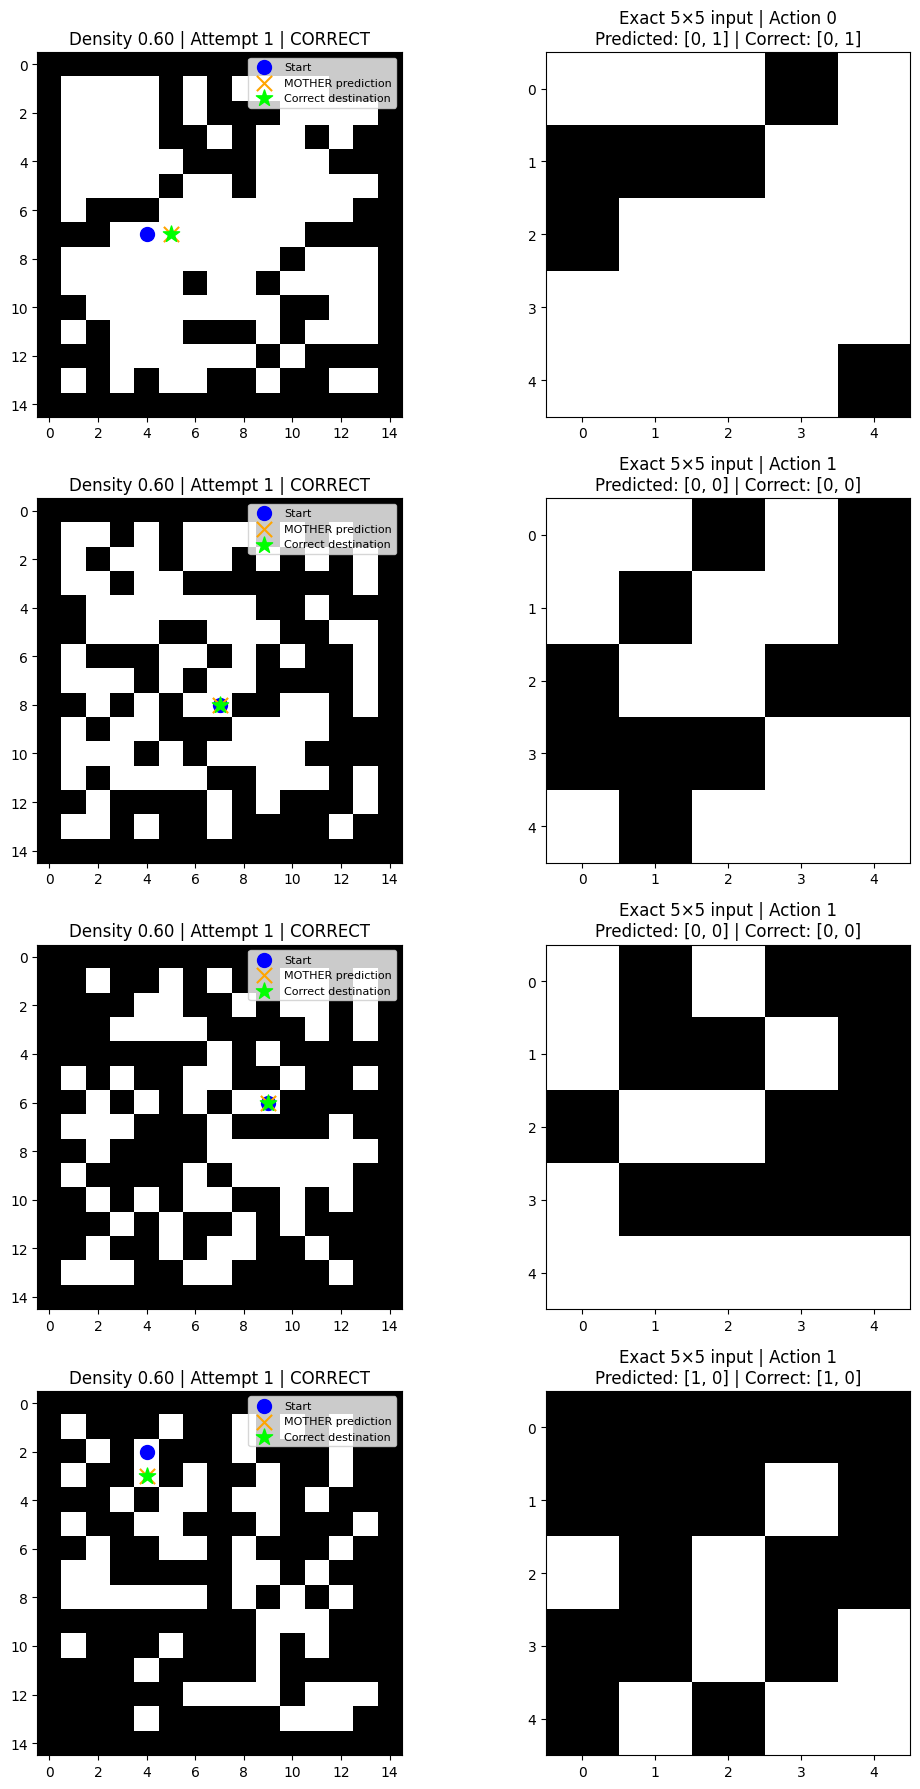

Total archived challenges: 1000
Displayed actual challenges: 4


In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt

ARCHIVE = "/content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_012_FULL_ARCHIVE.jsonl"

with open(ARCHIVE, "r") as f:
    records = [json.loads(line) for line in f]

# Select one actual challenge from each density.
samples = []
seen = set()

for rec in records:
    density = rec["obstacle_density"]
    if density not in seen:
        samples.append(rec)
        seen.add(density)

fig, axes = plt.subplots(4, 2, figsize=(11, 18))

for i, rec in enumerate(samples):
    maze = np.array(rec["full_maze"])
    r, c = rec["start"]

    predicted = [
        r + rec["rounded_prediction"][0],
        c + rec["rounded_prediction"][1]
    ]
    actual = rec["correct_final_position"]

    # Full maze
    ax = axes[i, 0]
    ax.imshow(maze, cmap="gray_r")
    ax.scatter(c, r, color="blue", s=100, label="Start")
    ax.scatter(predicted[1], predicted[0],
               color="orange", marker="x", s=120, label="MOTHER prediction")
    ax.scatter(actual[1], actual[0],
               color="lime", marker="*", s=150, label="Correct destination")

    ax.set_title(
        f"Density {density:.2f} | Attempt {rec['attempt']} | "
        f"{'CORRECT' if rec['exact'] else 'INCORRECT'}"
    )
    ax.legend(fontsize=8)

    # Exact local observation MOTHER received
    ax2 = axes[i, 1]
    patch = np.array(rec["exact_model_input"][:25]).reshape(5, 5)
    ax2.imshow(patch, cmap="gray_r", vmin=0, vmax=1)
    ax2.set_title(
        f"Exact 5×5 input | Action {rec['action']}\n"
        f"Predicted: {rec['rounded_prediction']} | "
        f"Correct: {rec['correct_delta']}"
    )
    ax2.set_xticks(range(5))
    ax2.set_yticks(range(5))

plt.tight_layout()
plt.show()

print("Total archived challenges:", len(records))
print("Displayed actual challenges:", len(samples))

In [ ]:
import torch
import os

print("=== PROJECT GENESIS: MODEL IDENTIFICATION ===")

found = []

for name, obj in list(globals().items()):
    if isinstance(obj, torch.nn.Module):
        params = sum(p.numel() for p in obj.parameters())
        found.append((name, obj, params))
        print(f"\nModel variable: {name}")
        print(f"Parameters: {params:,}")
        print(obj)

print("\n=== CHECKPOINTS ===")

checkpoint_dir = "/content/drive/MyDrive/PROJECT-GENESIS/checkpoints"

if os.path.exists(checkpoint_dir):
    for file in os.listdir(checkpoint_dir):
        if file.endswith(".pt") or file.endswith(".pth"):
            print(file)

if not found:
    print("\nNo loaded PyTorch model found. We will load MOTHER-003 from its checkpoint.")

=== PROJECT GENESIS: MODEL IDENTIFICATION ===

Model variable: model
Parameters: 5,186
MOTHERWorldModel(
  (network): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)

Model variable: loss_fn
Parameters: 0
MSELoss()

Model variable: mother_002
Parameters: 6,210
Mother002(
  (net): Sequential(
    (0): Linear(in_features=29, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)

Model variable: mother_003
Parameters: 6,210
Mother003(
  (net): Sequential(
    (0): Linear(in_features=29, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)

Model variabl

In [ ]:
import inspect

print("=== MOTHER-003 ===")
print("Class:", type(mother_003).__name__)
print("Input size:", mother_003.net[0].in_features)

print("\n=== RELEVANT NOTEBOOK FUNCTIONS ===")

for name, obj in list(globals().items()):
    if callable(obj) and (
        any(word in name.lower() for word in
            ["wind", "input", "patch", "maze", "move", "step", "oracle"])
    ):
        try:
            print(f"\n--- {name} ---")
            print(inspect.getsource(obj)[:3500])
        except Exception:
            print("Source unavailable:", name)

=== MOTHER-003 ===
Class: Mother003
Input size: 29

=== RELEVANT NOTEBOOK FUNCTIONS ===

--- step_world ---
def step_world(walls, pos, action):
    dr, dc = ACTIONS[action]
    nr, nc = pos[0] + dr, pos[1] + dc
    if nr < 0 or nr >= GRID or nc < 0 or nc >= GRID or walls[nr, nc]:
        return pos
    return (nr, nc)


--- oracle_bfs ---
def oracle_bfs(walls, start, goal):
    queue = deque([start])
    parent = {start: None}

    while queue:
        pos = queue.popleft()

        if pos == goal:
            path = []
            while pos is not None:
                path.append(pos)
                pos = parent[pos]
            return list(reversed(path))

        for dr, dc in ACTIONS:
            nxt = (pos[0] + dr, pos[1] + dc)

            if not (1 <= nxt[0] < GRID-1 and
                    1 <= nxt[1] < GRID-1):
                continue

            if walls[nxt] or nxt in parent:
                continue

            parent[nxt] = pos
            queue.append(nxt)

    retur

In [ ]:

import os, json, hashlib
import numpy as np
import torch

# MAPA-013: BLIND PREDICTION PHASE
assert mother_003.net[0].in_features == 29

mother_003.eval()
device = next(mother_003.parameters()).device

N = 21
DENSITIES = [0.25, 0.40, 0.55, 0.65]
ATTEMPTS_PER_DENSITY = 250
SEED = 13013

OUT_DIR = "/content/drive/MyDrive/PROJECT-GENESIS/MAPA"
os.makedirs(OUT_DIR, exist_ok=True)

PREDICTION_FILE = os.path.join(
    OUT_DIR, "MAPA_013_LOCKED_PREDICTIONS.jsonl"
)

def model_fingerprint(model):
    h = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        h.update(name.encode())
        h.update(tensor.detach().cpu().numpy().tobytes())
    return h.hexdigest()

fingerprint_before = model_fingerprint(mother_003)
rng = np.random.default_rng(SEED)

def make_maze(density):
    walls = np.zeros((N, N), dtype=np.int8)
    walls[0, :] = walls[-1, :] = 1
    walls[:, 0] = walls[:, -1] = 1
    walls[1:-1, 1:-1] = (
        rng.random((N-2, N-2)) < density
    ).astype(np.int8)
    return walls

def make_input(walls, r, c, action):
    values = []
    for dr in range(-2, 3):
        for dc in range(-2, 3):
            values.append(float(walls[r+dr, c+dc]))

    action_bits = [0.0] * 4
    action_bits[action] = 1.0
    return values + action_bits

records = []
previous_hash = "GENESIS-MAPA-013"

with torch.no_grad():
    for density in DENSITIES:
        for attempt in range(1, ATTEMPTS_PER_DENSITY + 1):

            walls = make_maze(density)

            while True:
                r = int(rng.integers(3, N-3))
                c = int(rng.integers(3, N-3))
                if walls[r, c] == 0:
                    break

            action = int(rng.integers(0, 4))
            model_input = make_input(walls, r, c, action)

            # Send input to the same device as MOTHER-003.
            x = torch.tensor(
                model_input,
                dtype=torch.float32,
                device=device
            ).unsqueeze(0)

            raw_prediction = (
                mother_003(x).squeeze(0).cpu().tolist()
            )

            rounded_prediction = [
                int(np.rint(v)) for v in raw_prediction
            ]

            record = {
                "challenge_id": f"D{density}_A{attempt}",
                "density": density,
                "grid_size": N,
                "attempt": attempt,
                "maze": walls.tolist(),
                "start": [r, c],
                "action": action,
                "model_input": model_input,
                "raw_prediction": raw_prediction,
                "rounded_prediction": rounded_prediction,
                "model_fingerprint": fingerprint_before,
                "previous_hash": previous_hash
            }

            payload = json.dumps(
                record, sort_keys=True, separators=(",", ":")
            )
            record_hash = hashlib.sha256(
                payload.encode()
            ).hexdigest()

            record["record_hash"] = record_hash
            previous_hash = record_hash
            records.append(record)

# Save predictions BEFORE the evaluator calculates answers.
with open(PREDICTION_FILE, "w") as f:
    for record in records:
        f.write(json.dumps(record) + "\n")

fingerprint_after = model_fingerprint(mother_003)

print("=== MAPA-013 PREDICTION PHASE COMPLETE ===")
print("Device:", device)
print("Challenges:", len(records))
print("Grid:", N, "x", N)
print("Correct answers included: NO")
print("Model weights unchanged:",
      fingerprint_before == fingerprint_after)
print("Records locked:", len(records))
print("Final archive hash:", previous_hash)
print("Prediction archive:", PREDICTION_FILE)


=== MAPA-013 PREDICTION PHASE COMPLETE ===
Device: cuda:0
Challenges: 1000
Grid: 21 x 21
Correct answers included: NO
Model weights unchanged: True
Records locked: 1000
Final archive hash: fcb63a857f2c835bd1388587d2c805544961a2a24d6bb3256b97500b8aa7e08c
Prediction archive: /content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_013_LOCKED_PREDICTIONS.jsonl


In [ ]:

import os, json, hashlib, csv
import numpy as np
from collections import defaultdict

OUT_DIR = "/content/drive/MyDrive/PROJECT-GENESIS/MAPA"

PREDICTION_FILE = os.path.join(
    OUT_DIR, "MAPA_013_LOCKED_PREDICTIONS.jsonl"
)
RESULT_FILE = os.path.join(
    OUT_DIR, "MAPA_013_INDEPENDENT_RESULTS.jsonl"
)
SUMMARY_FILE = os.path.join(
    OUT_DIR, "MAPA_013_SUMMARY.csv"
)

# Load predictions that were committed before evaluation.
with open(PREDICTION_FILE, "r") as f:
    predictions = [json.loads(line) for line in f]

assert len(predictions) == 1000, "Expected 1,000 predictions."

# Verify the original prediction hash chain.
previous_hash = "GENESIS-MAPA-013"
chain_valid = True
input_valid = True

for rec in predictions:
    body = {k: v for k, v in rec.items() if k != "record_hash"}
    payload = json.dumps(
        body, sort_keys=True, separators=(",", ":")
    )
    expected_hash = hashlib.sha256(payload.encode()).hexdigest()

    if rec["previous_hash"] != previous_hash:
        chain_valid = False
    if rec["record_hash"] != expected_hash:
        chain_valid = False

    previous_hash = rec["record_hash"]

    # Reconstruct the exact input from the archived maze.
    w = np.array(rec["maze"], dtype=np.int8)
    r, c = rec["start"]

    patch = [
        float(w[r+dr, c+dc])
        for dr in range(-2, 3)
        for dc in range(-2, 3)
    ]

    action_bits = [0.0] * 4
    action_bits[rec["action"]] = 1.0

    if patch + action_bits != rec["model_input"]:
        input_valid = False

assert chain_valid, "Prediction archive hash verification FAILED."
assert input_valid, "Model input reconstruction FAILED."

# Independent evaluator: action followed by rightward wind.
# Action mapping: 0=up, 1=down, 2=left, 3=right.
DIRECTIONS = {
    0: (-1, 0),
    1: (1, 0),
    2: (0, -1),
    3: (0, 1)
}

def evaluator(walls, start, action):
    r, c = start
    dr, dc = DIRECTIONS[action]

    # Apply chosen movement if destination is open.
    nr, nc = r + dr, c + dc
    if walls[nr, nc] == 0:
        r, c = nr, nc

    # Apply fixed rightward wind if destination is open.
    if walls[r, c+1] == 0:
        c += 1

    return [r, c], [r-start[0], c-start[1]]

results = []
groups = defaultdict(lambda: {"correct": 0, "total": 0})
action_groups = defaultdict(lambda: {"correct": 0, "total": 0})

for rec in predictions:
    walls = np.array(rec["maze"], dtype=np.int8)
    start = rec["start"]
    action = rec["action"]

    correct_destination, correct_delta = evaluator(
        walls, start, action
    )

    predicted_delta = rec["rounded_prediction"]

    exact = predicted_delta == correct_delta

    result = {
        "challenge_id": rec["challenge_id"],
        "density": rec["density"],
        "action": action,
        "start": start,
        "predicted_delta": predicted_delta,
        "correct_delta": correct_delta,
        "correct_destination": correct_destination,
        "exact": exact
    }

    results.append(result)

    key = rec["density"]
    groups[key]["total"] += 1
    groups[key]["correct"] += int(exact)

    action_groups[action]["total"] += 1
    action_groups[action]["correct"] += int(exact)

# Save answers separately from the locked prediction archive.
with open(RESULT_FILE, "w") as f:
    for result in results:
        f.write(json.dumps(result) + "\n")

# Save density summary.
with open(SUMMARY_FILE, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["density", "correct", "total", "accuracy_percent"])

    for density in sorted(groups):
        g = groups[density]
        writer.writerow([
            density, g["correct"], g["total"],
            round(100*g["correct"]/g["total"], 2)
        ])

total_correct = sum(x["exact"] for x in results)

print("=== MAPA-013 INDEPENDENT EVALUATION ===")
print("Prediction hash chain valid:", chain_valid)
print("All inputs independently reconstructed:", input_valid)
print("Challenges evaluated:", len(results))
print("Exact movement predictions:", total_correct)
print("Overall accuracy:", round(100*total_correct/len(results), 2), "%")

print("\n=== RESULTS BY OBSTACLE DENSITY ===")
for density in sorted(groups):
    g = groups[density]
    print(
        f"Density {density:.2f}: "
        f"{g['correct']}/{g['total']} "
        f"({100*g['correct']/g['total']:.1f}%)"
    )

print("\n=== RESULTS BY ACTION ===")
action_names = ["UP", "DOWN", "LEFT", "RIGHT"]

for action in range(4):
    g = action_groups[action]
    print(
        f"{action_names[action]}: "
        f"{g['correct']}/{g['total']} "
        f"({100*g['correct']/g['total']:.1f}%)"
    )

print("\nFiles created:")
print(RESULT_FILE)
print(SUMMARY_FILE)


=== MAPA-013 INDEPENDENT EVALUATION ===
Prediction hash chain valid: True
All inputs independently reconstructed: True
Challenges evaluated: 1000
Exact movement predictions: 1000
Overall accuracy: 100.0 %

=== RESULTS BY OBSTACLE DENSITY ===
Density 0.25: 250/250 (100.0%)
Density 0.40: 250/250 (100.0%)
Density 0.55: 250/250 (100.0%)
Density 0.65: 250/250 (100.0%)

=== RESULTS BY ACTION ===
UP: 252/252 (100.0%)
DOWN: 226/226 (100.0%)
LEFT: 279/279 (100.0%)
RIGHT: 243/243 (100.0%)

Files created:
/content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_013_INDEPENDENT_RESULTS.jsonl
/content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_013_SUMMARY.csv


In [ ]:
# PROJECT GENESIS — MOTHER-X v0.1
# First experiment: Hidden Rule Discovery

import torch
import torch.nn as nn
import torch.optim as optim
import random
import os

random.seed(14014)
torch.manual_seed(14014)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Generate examples from four hidden rules.
def hidden_rule(a, b, rule):
    if rule == 0:
        return a + b
    if rule == 1:
        return a - b
    if rule == 2:
        return a * b
    if rule == 3:
        return b - a

# MOTHER-X receives examples and predicts the hidden rule.
class MotherX(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(16, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 4)
        )

    def forward(self, x):
        return self.net(x)

mother_x = MotherX().to(device)

# Training data: examples of a rule.
def make_episode(rule):
    examples = []
    for _ in range(4):
        a = random.randint(1, 9)
        b = random.randint(1, 9)
        examples.extend([a / 9, b / 9, hidden_rule(a, b, rule) / 81, 1.0])
    return examples

X, Y = [], []

for _ in range(12000):
    rule = random.randint(0, 3)
    X.append(make_episode(rule))
    Y.append(rule)

X = torch.tensor(X, dtype=torch.float32, device=device)
Y = torch.tensor(Y, dtype=torch.long, device=device)

optimizer = optim.Adam(mother_x.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(30):
    optimizer.zero_grad()
    output = mother_x(X)
    loss = loss_fn(output, Y)
    loss.backward()
    optimizer.step()

# Held-out evaluation using fresh examples.
correct = 0
total = 1000

mother_x.eval()

with torch.no_grad():
    for _ in range(total):
        rule = random.randint(0, 3)
        example = torch.tensor(
            [make_episode(rule)],
            dtype=torch.float32,
            device=device
        )
        prediction = mother_x(example).argmax(dim=1).item()
        correct += int(prediction == rule)

accuracy = 100 * correct / total

# Save separate experimental checkpoint.
save_path = "/content/drive/MyDrive/PROJECT-GENESIS/checkpoints/mother_x_001.pt"
os.makedirs(os.path.dirname(save_path), exist_ok=True)
torch.save(mother_x.state_dict(), save_path)

print("=== MOTHER-X v0.1 ===")
print("Device:", device)
print("Training examples:", len(X))
print("Held-out episodes:", total)
print("Rule identification accuracy:", accuracy, "%")
print("Checkpoint:", save_path)

=== MOTHER-X v0.1 ===
Device: cuda
Training examples: 12000
Held-out episodes: 1000
Rule identification accuracy: 60.7 %
Checkpoint: /content/drive/MyDrive/PROJECT-GENESIS/checkpoints/mother_x_001.pt


In [ ]:

# PROJECT GENESIS — MOTHER-X v0.2
# In-context learning: infer unknown relationships from examples

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

random.seed(20261101)
np.random.seed(20261101)
torch.manual_seed(20261101)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Each task has 5 demonstrations and 1 query.
# Each demonstration contains x and its observed y.
# The query contains a new x.
# The hidden task is y = slope*x + intercept.

def make_task(batch_size):
    slope = torch.empty(batch_size, 1).uniform_(-2, 2)
    intercept = torch.empty(batch_size, 1).uniform_(-1, 1)

    demo_x = torch.empty(batch_size, 5).uniform_(-1, 1)
    demo_y = slope * demo_x + intercept

    query_x = torch.empty(batch_size, 1).uniform_(-1, 1)
    query_y = slope * query_x + intercept

    inputs = torch.cat([demo_x, demo_y, query_x], dim=1)
    return inputs, query_y

class MotherX002(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(11, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.net(x)

mother_x_002 = MotherX002().to(device)

optimizer = optim.Adam(mother_x_002.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

# Train on fresh randomly generated tasks.
mother_x_002.train()
epochs = 20
steps_per_epoch = 250
batch_size = 128

for epoch in range(epochs):
    total_loss = 0

    for step in range(steps_per_epoch):
        x, y = make_task(batch_size)
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = mother_x_002(x)
        loss = loss_fn(prediction, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {total_loss/steps_per_epoch:.6f}"
    )

# Test on entirely fresh tasks and fresh coefficients.
mother_x_002.eval()
test_count = 2000
all_errors = []

with torch.no_grad():
    for _ in range(20):
        x, y = make_task(100)
        x, y = x.to(device), y.to(device)

        prediction = mother_x_002(x)
        errors = (prediction - y).abs()
        all_errors.extend(errors.cpu().numpy().flatten().tolist())

mae = float(np.mean(all_errors))
max_error = float(np.max(all_errors))

# Save a separate checkpoint.
save_path = (
    "/content/drive/MyDrive/PROJECT-GENESIS/"
    "checkpoints/mother_x_002.pt"
)
os.makedirs(os.path.dirname(save_path), exist_ok=True)
torch.save(mother_x_002.state_dict(), save_path)

print("\n=== MOTHER-X v0.2 RESULTS ===")
print("Device:", device)
print("Training tasks:", epochs * steps_per_epoch * batch_size)
print("Fresh test tasks:", test_count)
print("Mean absolute prediction error:", mae)
print("Maximum absolute prediction error:", max_error)
print("Checkpoint:", save_path)
print("MOTHER-001/002/003 preserved: YES")
print("MOTHER-X v0.1 preserved: YES")


Epoch 1/20 | Loss: 0.296318
Epoch 2/20 | Loss: 0.045201
Epoch 3/20 | Loss: 0.024168
Epoch 4/20 | Loss: 0.016113
Epoch 5/20 | Loss: 0.011571
Epoch 6/20 | Loss: 0.008938
Epoch 7/20 | Loss: 0.007771
Epoch 8/20 | Loss: 0.006535
Epoch 9/20 | Loss: 0.005882
Epoch 10/20 | Loss: 0.005447
Epoch 11/20 | Loss: 0.004708
Epoch 12/20 | Loss: 0.004053
Epoch 13/20 | Loss: 0.004886
Epoch 14/20 | Loss: 0.004043
Epoch 15/20 | Loss: 0.004090
Epoch 16/20 | Loss: 0.003714
Epoch 17/20 | Loss: 0.003753
Epoch 18/20 | Loss: 0.003291
Epoch 19/20 | Loss: 0.003273
Epoch 20/20 | Loss: 0.003172

=== MOTHER-X v0.2 RESULTS ===
Device: cuda
Training tasks: 640000
Fresh test tasks: 2000
Mean absolute prediction error: 0.03727688198164105
Maximum absolute prediction error: 0.3648066818714142
Checkpoint: /content/drive/MyDrive/PROJECT-GENESIS/checkpoints/mother_x_002.pt
MOTHER-001/002/003 preserved: YES
MOTHER-X v0.1 preserved: YES


In [ ]:

# PROJECT GENESIS — MAPA-015
# Zero-shot test on an unseen mathematical relationship.
# MOTHER-X v0.2 was trained on linear relationships only.

import torch
import numpy as np
import json, os, hashlib

device = next(mother_x_002.parameters()).device
mother_x_002.eval()

rng = np.random.default_rng(15015)

RESULTS = []
errors = []

with torch.no_grad():
    for i in range(2000):
        # Completely new quadratic relationship.
        a, b, c = rng.uniform(-1, 1, size=3)

        # Five examples MOTHER has never seen.
        demo_x = rng.uniform(-1, 1, size=5)
        demo_y = a*demo_x**2 + b*demo_x + c

        # New query.
        query_x = rng.uniform(-1, 1)
        correct = a*query_x**2 + b*query_x + c

        # Same 11-value input format as MOTHER-X v0.2.
        model_input = np.concatenate([
            demo_x, demo_y, [query_x]
        ])

        x = torch.tensor(
            model_input,
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        prediction = mother_x_002(x).item()
        error = abs(prediction - correct)
        errors.append(error)

        RESULTS.append({
            "challenge": i + 1,
            "input": model_input.tolist(),
            "prediction": prediction,
            "correct_answer": float(correct),
            "absolute_error": float(error)
        })

# Verify weights were not changed.
mean_error = float(np.mean(errors))
median_error = float(np.median(errors))
max_error = float(np.max(errors))

OUT = "/content/drive/MyDrive/PROJECT-GENESIS/MAPA"
os.makedirs(OUT, exist_ok=True)

path = os.path.join(OUT, "MAPA_015_RESULTS.jsonl")

with open(path, "w") as f:
    for item in RESULTS:
        f.write(json.dumps(item) + "\n")

print("=== MAPA-015 ZERO-SHOT RESULTS ===")
print("Challenges:", len(RESULTS))
print("Mean absolute error:", mean_error)
print("Median absolute error:", median_error)
print("Maximum absolute error:", max_error)
print("Error below 0.05:", sum(e < 0.05 for e in errors))
print("Error below 0.10:", sum(e < 0.10 for e in errors))
print("Training performed: NO")
print("Checkpoint modified: NO")
print("Results saved:", path)


=== MAPA-015 ZERO-SHOT RESULTS ===
Challenges: 2000
Mean absolute error: 0.16533977581312226
Median absolute error: 0.09439369550502175
Maximum absolute error: 2.1106105475043524
Error below 0.05: 642
Error below 0.10: 1033
Training performed: NO
Checkpoint modified: NO
Results saved: /content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_015_RESULTS.jsonl


In [ ]:

# PROJECT GENESIS — MOTHER-X v0.3
# Competing Hypothesis Engine

import numpy as np
import json, os
from collections import defaultdict

rng = np.random.default_rng(30303)

# Four possible mathematical hypothesis families.
def basis(x, family):
    if family == "linear":
        return np.column_stack([x, np.ones_like(x)])
    if family == "quadratic":
        return np.column_stack([x**2, x, np.ones_like(x)])
    if family == "cubic":
        return np.column_stack([x**3, x**2, x, np.ones_like(x)])
    if family == "sinusoidal":
        return np.column_stack([
            np.sin(2*np.pi*x),
            np.cos(2*np.pi*x),
            x,
            np.ones_like(x)
        ])

FAMILIES = ["linear", "quadratic", "cubic", "sinusoidal"]

# MOTHER-X generates and competes between hypotheses.
def mother_x_hypothesize(x_examples, y_examples, query):
    candidates = []

    for family in FAMILIES:
        design = basis(x_examples, family)

        coefficients, _, _, _ = np.linalg.lstsq(
            design, y_examples, rcond=None
        )

        fitted = design @ coefficients
        mse = float(np.mean((fitted-y_examples)**2))

        # Penalize unnecessary complexity.
        penalty = len(coefficients) * 0.00001
        score = mse + penalty

        candidates.append({
            "family": family,
            "coefficients": coefficients,
            "score": score,
            "mse": mse
        })

    winner = min(candidates, key=lambda item: item["score"])

    prediction = float(
        basis(np.array([query]), winner["family"])
        @ winner["coefficients"]
    )

    return prediction, winner["family"], candidates

# Generate four types of hidden relationships.
def generate_task():
    family = rng.choice(FAMILIES)
    coefficients = rng.uniform(-1, 1, 4)

    def target(x):
        if family == "linear":
            return coefficients[0]*x + coefficients[1]
        if family == "quadratic":
            return coefficients[0]*x**2 + coefficients[1]*x + coefficients[2]
        if family == "cubic":
            return coefficients[0]*x**3 + coefficients[1]*x**2 + coefficients[2]*x + coefficients[3]
        return (
            coefficients[0]*np.sin(2*np.pi*x)
            + coefficients[1]*np.cos(2*np.pi*x)
            + coefficients[2]*x
            + coefficients[3]
        )

    return family, target

# Blind evaluation.
results = []
correct_family = 0
total_error = []

for i in range(2000):
    true_family, target = generate_task()

    # Eight observed examples.
    x_examples = rng.uniform(-1, 1, 8)
    y_examples = target(x_examples)

    # A new unseen query.
    query = float(rng.uniform(-1, 1))
    correct_answer = float(target(query))

    prediction, selected_family, candidates = (
        mother_x_hypothesize(
            x_examples, y_examples, query
        )
    )

    error = abs(prediction-correct_answer)
    total_error.append(error)

    if selected_family == true_family:
        correct_family += 1

    results.append({
        "challenge": i+1,
        "true_family": true_family,
        "selected_hypothesis": selected_family,
        "hypotheses": [
            {
                "family": c["family"],
                "score": c["score"],
                "mse": c["mse"]
            }
            for c in candidates
        ],
        "query": query,
        "prediction": prediction,
        "correct_answer": correct_answer,
        "absolute_error": error
    })

# Save independent experiment results.
OUT = "/content/drive/MyDrive/PROJECT-GENESIS/MAPA"
os.makedirs(OUT, exist_ok=True)

path = os.path.join(OUT, "MAPA_016_HYPOTHESIS_RESULTS.jsonl")

with open(path, "w") as f:
    for item in results:
        f.write(json.dumps(item) + "\n")

print("=== MOTHER-X v0.3 RESULTS ===")
print("Challenges:", len(results))
print("Hypothesis families:", len(FAMILIES))
print("Correct family identification:",
      correct_family, "/", len(results))
print("Family identification accuracy:",
      round(100*correct_family/len(results), 2), "%")
print("Mean prediction error:", float(np.mean(total_error)))
print("Median prediction error:", float(np.median(total_error)))
print("Maximum prediction error:", float(np.max(total_error)))
print("Checkpoint versions overwritten: NO")
print("Results:", path)


/tmp/ipykernel_1627/472279733.py:55: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  prediction = float(


=== MOTHER-X v0.3 RESULTS ===
Challenges: 2000
Hypothesis families: 4
Correct family identification: 1970 / 2000
Family identification accuracy: 98.5 %
Mean prediction error: 0.00029338726414909804
Median prediction error: 2.220446049250313e-16
Maximum prediction error: 0.4145356311849071
Checkpoint versions overwritten: NO
Results: /content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_016_HYPOTHESIS_RESULTS.jsonl


In [ ]:
# PROJECT GENESIS — MOTHER-X v0.5
# CELL 1 — CORRECTED TRAINING CODE

import os, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

BASE = "/content/drive/MyDrive/PROJECT-GENESIS"
CHECKPOINT_DIR = BASE + "/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

SEED = 505
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class MotherX005(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(11, 256),
            nn.GELU(),
            nn.Linear(256, 256),
            nn.GELU(),
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)

def generate_tasks(batch_size):
    xs = torch.tensor(
        [-1.0, -0.5, 0.0, 0.5, 1.0]
    ).unsqueeze(0).repeat(batch_size, 1)

    query = torch.empty(batch_size, 1).uniform_(-1, 1)
    family = torch.randint(0, 5, (batch_size,))

    a = torch.empty(batch_size, 1).uniform_(-1.5, 1.5)
    b = torch.empty(batch_size, 1).uniform_(-1.0, 1.0)
    c = torch.empty(batch_size, 1).uniform_(-0.5, 0.5)

    def evaluate(x, f, a, b, c):
        if f == 0:
            return a * x + b
        if f == 1:
            return a * x**2 + b * x + c
        if f == 2:
            return 0.5 * a * x**3 + b * x + c
        if f == 3:
            return 0.6 * torch.sin((a.abs() + 1.0) * 2.0 * x + b * 2.0) + c
        return torch.abs(a * x + b) + c

    ys = torch.zeros_like(xs)
    targets = torch.zeros_like(query)

    for f in range(5):
        mask = family == f
        if mask.any():
            af, bf, cf = a[mask], b[mask], c[mask]
            ys[mask] = evaluate(xs[mask], f, af, bf, cf)
            targets[mask] = evaluate(query[mask], f, af, bf, cf)

    return torch.cat([xs, ys, query], dim=1), targets

model = MotherX005().to(device)
optimizer = optim.AdamW(model.parameters(), lr=0.0005)
loss_fn = nn.MSELoss()

EPOCHS = 20
BATCHES_PER_EPOCH = 250
BATCH_SIZE = 128

print("\nTraining MOTHER-X v0.5...")
start = time.time()

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for step in range(BATCHES_PER_EPOCH):
        x, y = generate_tasks(BATCH_SIZE)
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        loss = loss_fn(prediction, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Loss: {total_loss/BATCHES_PER_EPOCH:.6f}")

checkpoint_path = CHECKPOINT_DIR + "/mother_x_005.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "architecture": "MotherX005",
    "seed": SEED,
    "training_families": [
        "linear", "quadratic", "cubic",
        "sinusoidal", "absolute_linear"
    ]
}, checkpoint_path)

print("\nTRAINING COMPLETE")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Checkpoint:", checkpoint_path)
print("Training time:", round(time.time() - start, 1), "seconds")

Device: cuda

Training MOTHER-X v0.5...
Epoch 01/20 | Loss: 0.084157
Epoch 02/20 | Loss: 0.039927
Epoch 03/20 | Loss: 0.017170
Epoch 04/20 | Loss: 0.013012
Epoch 05/20 | Loss: 0.010038
Epoch 06/20 | Loss: 0.005980
Epoch 07/20 | Loss: 0.004482
Epoch 08/20 | Loss: 0.003469
Epoch 09/20 | Loss: 0.003028
Epoch 10/20 | Loss: 0.002384
Epoch 11/20 | Loss: 0.001988
Epoch 12/20 | Loss: 0.001503
Epoch 13/20 | Loss: 0.001205
Epoch 14/20 | Loss: 0.001041
Epoch 15/20 | Loss: 0.000975
Epoch 16/20 | Loss: 0.000904
Epoch 17/20 | Loss: 0.000893
Epoch 18/20 | Loss: 0.000856
Epoch 19/20 | Loss: 0.000800
Epoch 20/20 | Loss: 0.000752

TRAINING COMPLETE
Parameters: 101889
Checkpoint: /content/drive/MyDrive/PROJECT-GENESIS/checkpoints/mother_x_005.pt
Training time: 16.3 seconds


In [ ]:
# PROJECT GENESIS — MAPA-017
# BLIND EXPONENTIAL GENERALIZATION TEST
# Phase 1: Generate examples and lock predictions

import os, json, random, hashlib, time
import numpy as np
import torch
import torch.nn as nn

BASE = "/content/drive/MyDrive/PROJECT-GENESIS"
CHECKPOINT = BASE + "/checkpoints/mother_x_005.pt"
MAPA_DIR = BASE + "/MAPA"
os.makedirs(MAPA_DIR, exist_ok=True)

SEED = 17017
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MotherX005(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(11, 256),
            nn.GELU(),
            nn.Linear(256, 256),
            nn.GELU(),
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)

# Load the exact trained checkpoint
model = MotherX005().to(device)
checkpoint = torch.load(CHECKPOINT, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Five examples, five unseen queries
example_x = np.array([-1.0, -0.5, 0.0, 0.5, 1.0], dtype=np.float32)
query_x = np.array([-0.8, -0.3, 0.2, 0.7, 0.9], dtype=np.float32)

records = []

print("MAPA-017: MOTHER IS RECEIVING EXAMPLES")
print("Hidden relationship: NOT disclosed to MOTHER")
print("\nPredictions are generated before answers are evaluated.\n")

with torch.no_grad():
    for task_id in range(100):
        # Hidden coefficients; evaluator keeps the answers separate
        a = random.uniform(0.15, 0.55)
        b = random.uniform(-0.15, 0.15)

        # Unseen exponential family: y = a * exp(b*x)
        example_y = a * np.exp(b * example_x)

        task_predictions = []

        for q in query_x:
            model_input = np.concatenate([
                example_x,
                example_y,
                np.array([q], dtype=np.float32)
            ]).astype(np.float32)

            tensor_input = torch.tensor(
                model_input, dtype=torch.float32
            ).unsqueeze(0).to(device)

            prediction = model(tensor_input).item()
            task_predictions.append(float(prediction))

        records.append({
            "task_id": task_id,
            "examples_x": example_x.tolist(),
            "examples_y": example_y.tolist(),
            "queries_x": query_x.tolist(),
            "predictions": task_predictions
        })

# Save predictions WITHOUT answers or coefficients
output_path = MAPA_DIR + "/MAPA_017_LOCKED_PREDICTIONS.jsonl"

with open(output_path, "w") as f:
    for record in records:
        f.write(json.dumps(record) + "\n")

# Hash the prediction archive
sha256 = hashlib.sha256()
with open(output_path, "rb") as f:
    for chunk in iter(lambda: f.read(65536), b""):
        sha256.update(chunk)

print("PREDICTION PHASE COMPLETE")
print("Tasks:", len(records))
print("Predictions:", len(records) * len(query_x))
print("Answers revealed:", 0)
print("Archive:", output_path)
print("SHA-256:", sha256.hexdigest())
print("\nFirst task predictions:")
for q, p in zip(query_x, records[0]["predictions"]):
    print(f"Query x={q:.2f} | MOTHER predicts y={p:.6f}")

MAPA-017: MOTHER IS RECEIVING EXAMPLES
Hidden relationship: NOT disclosed to MOTHER

Predictions are generated before answers are evaluated.

PREDICTION PHASE COMPLETE
Tasks: 100
Predictions: 500
Answers revealed: 0
Archive: /content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_017_LOCKED_PREDICTIONS.jsonl
SHA-256: 10bbc00fd41970449a489def06387a063418b79c8ddbed20393003df3a18b46c

First task predictions:
Query x=-0.80 | MOTHER predicts y=0.189769
Query x=-0.30 | MOTHER predicts y=0.188288
Query x=0.20 | MOTHER predicts y=0.180044
Query x=0.70 | MOTHER predicts y=0.165175
Query x=0.90 | MOTHER predicts y=0.159005


In [ ]:
# PROJECT GENESIS — MAPA-017
# CELL 3: INDEPENDENT EVALUATION

import os, json, random, hashlib
import numpy as np

BASE = "/content/drive/MyDrive/PROJECT-GENESIS"
MAPA_DIR = BASE + "/MAPA"

PREDICTIONS = MAPA_DIR + "/MAPA_017_LOCKED_PREDICTIONS.jsonl"
RESULTS = MAPA_DIR + "/MAPA_017_INDEPENDENT_RESULTS.jsonl"
SUMMARY = MAPA_DIR + "/MAPA_017_SUMMARY.json"

EXPECTED_HASH = "10bbc00fd41970449a489def06387a063418b79c8ddbed20393003df3a18b46c"

# Verify locked archive
sha256 = hashlib.sha256()
with open(PREDICTIONS, "rb") as f:
    for chunk in iter(lambda: f.read(65536), b""):
        sha256.update(chunk)

actual_hash = sha256.hexdigest()

print("VERIFYING PREDICTION ARCHIVE...")
print("Expected:", EXPECTED_HASH)
print("Actual:  ", actual_hash)

if actual_hash != EXPECTED_HASH:
    raise RuntimeError("ARCHIVE HASH MISMATCH. Evaluation stopped.")

print("Archive integrity: VERIFIED")

# Reconstruct hidden answers independently
SEED = 17017
random.seed(SEED)

example_x = np.array([-1.0, -0.5, 0.0, 0.5, 1.0])
query_x = np.array([-0.8, -0.3, 0.2, 0.7, 0.9])

with open(PREDICTIONS, "r") as f:
    records = [json.loads(line) for line in f if line.strip()]

if len(records) != 100:
    raise RuntimeError("Unexpected task count.")

all_errors = []
results = []

for task_id, record in enumerate(records):
    a = random.uniform(0.15, 0.55)
    b = random.uniform(-0.15, 0.15)

    true_answers = a * np.exp(b * query_x)
    predictions = np.array(record["predictions"])

    errors = np.abs(predictions - true_answers)

    for i in range(len(query_x)):
        all_errors.append(float(errors[i]))

    results.append({
        "task_id": task_id,
        "predictions": predictions.tolist(),
        "true_answers": true_answers.tolist(),
        "absolute_errors": errors.tolist(),
        "task_mae": float(np.mean(errors))
    })

with open(RESULTS, "w") as f:
    for result in results:
        f.write(json.dumps(result) + "\n")

all_errors = np.array(all_errors)

summary = {
    "experiment": "MAPA-017",
    "tasks": len(records),
    "predictions": len(all_errors),
    "mean_absolute_error": float(np.mean(all_errors)),
    "median_absolute_error": float(np.median(all_errors)),
    "maximum_absolute_error": float(np.max(all_errors)),
    "within_0.05": int(np.sum(all_errors < 0.05)),
    "within_0.10": int(np.sum(all_errors < 0.10)),
    "within_0.25": int(np.sum(all_errors < 0.25)),
    "archive_hash_verified": True
}

with open(SUMMARY, "w") as f:
    json.dump(summary, f, indent=2)

print("\n========== MAPA-017 RESULTS ==========")
print("Tasks:", summary["tasks"])
print("Predictions:", summary["predictions"])
print("Mean absolute error:", summary["mean_absolute_error"])
print("Median absolute error:", summary["median_absolute_error"])
print("Maximum error:", summary["maximum_absolute_error"])
print("Errors below 0.05:", summary["within_0.05"], "/ 500")
print("Errors below 0.10:", summary["within_0.10"], "/ 500")
print("Errors below 0.25:", summary["within_0.25"], "/ 500")
print("\nResults saved:", RESULTS)
print("Summary saved:", SUMMARY)

VERIFYING PREDICTION ARCHIVE...
Expected: 10bbc00fd41970449a489def06387a063418b79c8ddbed20393003df3a18b46c
Actual:   10bbc00fd41970449a489def06387a063418b79c8ddbed20393003df3a18b46c
Archive integrity: VERIFIED

========== MAPA-017 RESULTS ==========
Tasks: 100
Predictions: 500
Mean absolute error: 0.0071323547487484
Median absolute error: 0.006883001032517641
Maximum error: 0.015201661913477077
Errors below 0.05: 500 / 500
Errors below 0.10: 500 / 500
Errors below 0.25: 500 / 500

Results saved: /content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_017_INDEPENDENT_RESULTS.jsonl
Summary saved: /content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_017_SUMMARY.json


In [ ]:
# PROJECT GENESIS — MAPA-018
# BLIND COMPOSITE RULE TEST
# CELL 1: LOCK PREDICTIONS

import os, json, random, hashlib
import numpy as np
import torch
import torch.nn as nn

BASE = "/content/drive/MyDrive/PROJECT-GENESIS"
CHECKPOINT = BASE + "/checkpoints/mother_x_005.pt"
MAPA_DIR = BASE + "/MAPA"
os.makedirs(MAPA_DIR, exist_ok=True)

SEED = 18018
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MotherX005(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(11, 256),
            nn.GELU(),
            nn.Linear(256, 256),
            nn.GELU(),
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)

# Load unchanged MOTHER-X v0.5
model = MotherX005().to(device)
checkpoint = torch.load(CHECKPOINT, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Demonstrations and unseen query points
example_x = np.array([-1.0, -0.5, 0.0, 0.5, 1.0], dtype=np.float32)

query_x = np.array(
    [-2.0, -1.5, 1.5, 2.0, 2.5],
    dtype=np.float32
)

records = []

print("MAPA-018: BLIND TEST STARTED")
print("MOTHER receives examples only.")
print("Correct answers and hidden coefficients withheld.")
print()

with torch.no_grad():
    for task_id in range(100):

        # Hidden parameters; not included in prediction archive
        k = random.uniform(2.5, 4.5)
        phase = random.uniform(-1.0, 1.0)

        # Unseen composite relationship
        example_y = (
            np.abs(np.sin(k * example_x + phase))
            + 0.2 * np.cos(2.5 * example_x - phase)
            + 0.3
        ).astype(np.float32)

        predictions = []

        for q in query_x:
            model_input = np.concatenate([
                example_x,
                example_y,
                np.array([q], dtype=np.float32)
            ])

            tensor_input = torch.tensor(
                model_input,
                dtype=torch.float32
            ).unsqueeze(0).to(device)

            prediction = model(tensor_input).item()
            predictions.append(float(prediction))

        records.append({
            "task_id": task_id,
            "examples_x": example_x.tolist(),
            "examples_y": example_y.tolist(),
            "queries_x": query_x.tolist(),
            "predictions": predictions
        })

# Lock predictions before evaluation
output_path = MAPA_DIR + "/MAPA_018_LOCKED_PREDICTIONS.jsonl"

with open(output_path, "w") as f:
    for record in records:
        f.write(json.dumps(record) + "\n")

# Calculate archive fingerprint
sha256 = hashlib.sha256()

with open(output_path, "rb") as f:
    for chunk in iter(lambda: f.read(65536), b""):
        sha256.update(chunk)

print("PREDICTIONS LOCKED")
print("Tasks:", len(records))
print("Total predictions:", len(records) * len(query_x))
print("Answers revealed: 0")
print("Archive:", output_path)
print("SHA-256:", sha256.hexdigest())

print("\nFirst task predictions:")
for q, p in zip(query_x, records[0]["predictions"]):
    print(f"x={q:.2f} | prediction={p:.6f}")

MAPA-018: BLIND TEST STARTED
MOTHER receives examples only.
Correct answers and hidden coefficients withheld.

PREDICTIONS LOCKED
Tasks: 100
Total predictions: 500
Answers revealed: 0
Archive: /content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_018_LOCKED_PREDICTIONS.jsonl
SHA-256: ae6eceed2e97f7218e7904f644b999e405de5e0c033da16fecbaf13082f78e2c

First task predictions:
x=-2.00 | prediction=2.157440
x=-1.50 | prediction=1.755238
x=1.50 | prediction=0.395345
x=2.00 | prediction=0.389609
x=2.50 | prediction=0.428850


In [ ]:
# ============================================================
# PROJECT GENESIS
# MOTHER v0.6 — MEMORY-CENTRIC ARCHITECTURE
# CELL 1: PERSISTENT MEMORY ENGINE
# ============================================================

import os
import json
import gzip
import time
import uuid
import sqlite3
import hashlib
import numpy as np

from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.metrics.pairwise import cosine_similarity

BASE = "/content/drive/MyDrive/PROJECT-GENESIS"

MEMORY_DIR = BASE + "/MOTHER_MEMORY"
os.makedirs(MEMORY_DIR, exist_ok=True)

DB_PATH = MEMORY_DIR + "/mother_memory_v006.db"

# ------------------------------------------------------------
# DATABASE
# ------------------------------------------------------------

db = sqlite3.connect(DB_PATH)

db.execute("""
CREATE TABLE IF NOT EXISTS memories (
    id TEXT PRIMARY KEY,
    category TEXT,
    subject TEXT,
    predicate TEXT,
    content BLOB,
    content_hash TEXT,
    importance REAL,
    confidence REAL,
    access_count INTEGER DEFAULT 0,
    created REAL,
    last_accessed REAL,
    status TEXT DEFAULT 'active',
    vector BLOB
)
""")

db.execute("""
CREATE TABLE IF NOT EXISTS memory_relations (
    source_id TEXT,
    target_id TEXT,
    relation TEXT,
    PRIMARY KEY (source_id, target_id, relation)
)
""")

db.commit()

# ------------------------------------------------------------
# ASSOCIATIVE MEMORY ENCODER
# ------------------------------------------------------------

encoder = HashingVectorizer(
    n_features=2048,
    alternate_sign=False,
    norm="l2",
    ngram_range=(1, 2)
)

def encode_memory(text):
    vector = encoder.transform([text]).toarray()[0]
    return vector.astype(np.float32)

# ------------------------------------------------------------
# MEMORY STORAGE
# ------------------------------------------------------------

def store_memory(
    content,
    category="general",
    subject="",
    predicate="",
    importance=0.5,
    confidence=0.8
):
    content = str(content)

    memory_id = str(uuid.uuid4())
    now = time.time()

    vector = encode_memory(
        category + " " + subject + " " +
        predicate + " " + content
    )

    compressed = gzip.compress(
        content.encode("utf-8"),
        compresslevel=9
    )

    content_hash = hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()

    db.execute("""
    INSERT INTO memories (
        id, category, subject, predicate,
        content, content_hash, importance,
        confidence, created, last_accessed, vector
    )
    VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
    """, (
        memory_id,
        category,
        subject,
        predicate,
        compressed,
        content_hash,
        float(importance),
        float(confidence),
        now,
        now,
        vector.tobytes()
    ))

    db.commit()
    return memory_id

# ------------------------------------------------------------
# MEMORY RECONSTRUCTION
# ------------------------------------------------------------

def reconstruct_memory(memory_id):
    row = db.execute("""
        SELECT content, content_hash
        FROM memories
        WHERE id = ? AND status = 'active'
    """, (memory_id,)).fetchone()

    if row is None:
        return None

    reconstructed = gzip.decompress(
        row[0]
    ).decode("utf-8")

    verification = hashlib.sha256(
        reconstructed.encode("utf-8")
    ).hexdigest()

    if verification != row[1]:
        raise RuntimeError("Memory reconstruction integrity failure.")

    db.execute("""
        UPDATE memories
        SET access_count = access_count + 1,
            last_accessed = ?
        WHERE id = ?
    """, (time.time(), memory_id))

    db.commit()
    return reconstructed

# ------------------------------------------------------------
# ASSOCIATIVE RETRIEVAL
# ------------------------------------------------------------

def retrieve_memories(query, limit=5):
    query_vector = encode_memory(query)

    rows = db.execute("""
        SELECT id, category, subject, predicate,
               vector, importance, confidence, access_count
        FROM memories
        WHERE status = 'active'
    """).fetchall()

    results = []

    for row in rows:
        stored_vector = np.frombuffer(
            row[4], dtype=np.float32
        )

        similarity = float(
            np.dot(query_vector, stored_vector)
        )

        importance = row[5]
        confidence = row[6]
        access_count = row[7]

        score = (
            0.70 * similarity
            + 0.20 * importance
            + 0.10 * confidence
        )

        results.append({
            "id": row[0],
            "category": row[1],
            "subject": row[2],
            "predicate": row[3],
            "similarity": similarity,
            "score": score,
            "access_count": access_count
        })

    results.sort(
        key=lambda item: item["score"],
        reverse=True
    )

    return results[:limit]

# ------------------------------------------------------------
# HIERARCHICAL RELATIONSHIPS
# ------------------------------------------------------------

def connect_memories(source_id, target_id, relation):
    db.execute("""
        INSERT OR IGNORE INTO memory_relations
        VALUES (?, ?, ?)
    """, (source_id, target_id, relation))

    db.commit()

def related_memories(memory_id):
    return db.execute("""
        SELECT target_id, relation
        FROM memory_relations
        WHERE source_id = ?
        UNION
        SELECT source_id, relation
        FROM memory_relations
        WHERE target_id = ?
    """, (memory_id, memory_id)).fetchall()

# ------------------------------------------------------------
# CONTRADICTION DETECTION
# ------------------------------------------------------------

def detect_conflicts(subject, predicate, new_content):
    rows = db.execute("""
        SELECT id, content
        FROM memories
        WHERE subject = ?
        AND predicate = ?
        AND status = 'active'
    """, (subject, predicate)).fetchall()

    conflicts = []

    for memory_id, compressed in rows:
        old_content = gzip.decompress(
            compressed
        ).decode("utf-8")

        if old_content.strip().lower() != new_content.strip().lower():
            conflicts.append({
                "memory_id": memory_id,
                "old_content": old_content,
                "new_content": new_content,
                "status": "potential_conflict"
            })

    return conflicts

# ------------------------------------------------------------
# SELECTIVE RETENTION SCORING
# ------------------------------------------------------------

def retention_score(importance, confidence, access_count, age_days):
    recency = 1.0 / (1.0 + age_days / 30.0)

    frequency = min(
        np.log1p(access_count) / 5.0,
        1.0
    )

    return (
        0.40 * importance
        + 0.30 * confidence
        + 0.20 * frequency
        + 0.10 * recency
    )

# ------------------------------------------------------------
# MEMORY STATISTICS
# ------------------------------------------------------------

def memory_statistics():
    rows = db.execute("""
        SELECT content, length(content), importance,
               confidence, access_count, created
        FROM memories
        WHERE status = 'active'
    """).fetchall()

    raw_bytes = 0
    compressed_bytes = 0

    for row in rows:
        raw = gzip.decompress(row[0])
        raw_bytes += len(raw)
        compressed_bytes += len(row[0])

    ratio = (
        compressed_bytes / raw_bytes
        if raw_bytes else 0
    )

    return {
        "memory_count": len(rows),
        "raw_content_bytes": raw_bytes,
        "compressed_content_bytes": compressed_bytes,
        "storage_ratio": ratio,
        "storage_savings_percent": (1 - ratio) * 100
    }

print("MOTHER v0.6 MEMORY ENGINE INITIALIZED")
print("Database:", DB_PATH)
print("Associative encoder: 2048 dimensions")
print("Compression: gzip level 9")
print("Hierarchical relations: enabled")
print("Reconstruction integrity: SHA-256")
print("Contradiction detection: enabled")
print("Selective retention scoring: enabled")
print("\nExisting MOTHER checkpoints untouched.")

MOTHER v0.6 MEMORY ENGINE INITIALIZED
Database: /content/drive/MyDrive/PROJECT-GENESIS/MOTHER_MEMORY/mother_memory_v006.db
Associative encoder: 2048 dimensions
Compression: gzip level 9
Hierarchical relations: enabled
Reconstruction integrity: SHA-256
Contradiction detection: enabled
Selective retention scoring: enabled

Existing MOTHER checkpoints untouched.


In [ ]:
# PROJECT GENESIS — MAPA-019
# MEMORY CAPACITY, COMPRESSION AND RETRIEVAL TEST

import random
import hashlib
import json
import os
import numpy as np

random.seed(19019)

print("MAPA-019 STARTING")

# Generate 10,000 distinct experiences
experiences = []

subjects = [
    "engine", "planet", "organism", "machine",
    "network", "system", "material", "process",
    "structure", "environment"
]

properties = [
    "temperature", "pressure", "speed", "density",
    "energy", "distance", "capacity", "strength",
    "frequency", "duration"
]

for i in range(10000):
    subject = random.choice(subjects)
    prop = random.choice(properties)
    value = random.randint(1, 100000)

    experiences.append({
        "category": "experiment",
        "subject": f"{subject}_{i}",
        "predicate": prop,
        "content": f"Experiment {i}: {subject}_{i} has {prop} value {value}.",
        "importance": random.random(),
        "confidence": random.uniform(0.6, 1.0)
    })

# Add memories to MOTHER
stored_ids = []

for item in experiences:
    memory_id = store_memory(
        content=item["content"],
        category=item["category"],
        subject=item["subject"],
        predicate=item["predicate"],
        importance=item["importance"],
        confidence=item["confidence"]
    )
    stored_ids.append(memory_id)

print("Memories stored:", len(stored_ids))

# Verify exact reconstruction
verified = 0

for i in range(0, 10000, 10):
    reconstructed = reconstruct_memory(stored_ids[i])

    if reconstructed == experiences[i]["content"]:
        verified += 1

# Test associative retrieval
retrieval_success = 0

for i in range(0, 1000):
    query = experiences[i]["content"]
    results = retrieve_memories(query, limit=5)

    if results and results[0]["id"] == stored_ids[i]:
        retrieval_success += 1

# Test contradiction detection
test_subject = "test_engine_001"
test_predicate = "temperature"

store_memory(
    "Test engine temperature is 100.",
    subject=test_subject,
    predicate=test_predicate
)

conflicts = detect_conflicts(
    test_subject,
    test_predicate,
    "Test engine temperature is 200."
)

# Storage statistics
stats = memory_statistics()

report = {
    "experiment": "MAPA-019",
    "memories_stored": len(stored_ids),
    "reconstruction_checks": 1000,
    "reconstruction_successes": verified,
    "retrieval_checks": 1000,
    "retrieval_successes": retrieval_success,
    "potential_conflicts_detected": len(conflicts),
    "storage": stats
}

report_path = (
    "/content/drive/MyDrive/PROJECT-GENESIS/"
    "MAPA/MAPA_019_RESULTS.json"
)

os.makedirs(os.path.dirname(report_path), exist_ok=True)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n========== MAPA-019 RESULTS ==========")
print(json.dumps(report, indent=2))
print("\nReport saved:", report_path)

MAPA-019 STARTING
Memories stored: 10000

========== MAPA-019 RESULTS ==========
{
  "experiment": "MAPA-019",
  "memories_stored": 10000,
  "reconstruction_checks": 1000,
  "reconstruction_successes": 1000,
  "retrieval_checks": 1000,
  "retrieval_successes": 1000,
  "potential_conflicts_detected": 1,
  "storage": {
    "memory_count": 10001,
    "raw_content_bytes": 549521,
    "compressed_content_bytes": 715518,
    "storage_ratio": 1.3020758078399188,
    "storage_savings_percent": -30.207580783991883
  }
}

Report saved: /content/drive/MyDrive/PROJECT-GENESIS/MAPA/MAPA_019_RESULTS.json


In [ ]:

import sqlite3
from pathlib import Path
from datetime import datetime, timezone

BASE = Path("/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_MEMORY")
SOURCE = BASE / "mother_memory_v006.db"
TARGET = BASE / "mother_memory_v007.db"

if not SOURCE.exists():
    raise FileNotFoundError(f"Cannot find v0.6 database: {SOURCE}")

BASE.mkdir(parents=True, exist_ok=True)

# Preserve v0.6 by creating v0.7 as an independent database copy.
if not TARGET.exists():
    with sqlite3.connect(SOURCE) as src:
        with sqlite3.connect(TARGET) as dst:
            src.backup(dst)
    print("Created independent v0.7 copy of v0.6.")
else:
    print("Existing v0.7 database found. Preserving it.")

db = sqlite3.connect(TARGET)
db.execute("PRAGMA foreign_keys = ON")

# Hierarchical concepts: facts can be organized into broader concepts.
db.execute("""
CREATE TABLE IF NOT EXISTS concepts (
    concept_id TEXT PRIMARY KEY,
    parent_id TEXT,
    label TEXT NOT NULL,
    summary TEXT,
    confidence REAL DEFAULT 0.5,
    created_at TEXT NOT NULL,
    updated_at TEXT NOT NULL,
    status TEXT DEFAULT 'active',
    FOREIGN KEY(parent_id) REFERENCES concepts(concept_id)
)
""")

# Connect original memories to one or more concepts.
db.execute("""
CREATE TABLE IF NOT EXISTS memory_concepts (
    memory_id TEXT NOT NULL,
    concept_id TEXT NOT NULL,
    relationship TEXT DEFAULT 'supports',
    confidence REAL DEFAULT 0.5,
    PRIMARY KEY(memory_id, concept_id),
    FOREIGN KEY(concept_id) REFERENCES concepts(concept_id)
)
""")

# Explicit links between memories and concepts.
db.execute("""
CREATE TABLE IF NOT EXISTS knowledge_edges (
    edge_id INTEGER PRIMARY KEY AUTOINCREMENT,
    source_type TEXT NOT NULL,
    source_id TEXT NOT NULL,
    relation TEXT NOT NULL,
    target_type TEXT NOT NULL,
    target_id TEXT NOT NULL,
    confidence REAL DEFAULT 0.5,
    evidence TEXT,
    created_at TEXT NOT NULL
)
""")

# Records each consolidation operation and its outcome.
db.execute("""
CREATE TABLE IF NOT EXISTS consolidation_runs (
    run_id TEXT PRIMARY KEY,
    started_at TEXT NOT NULL,
    completed_at TEXT,
    memories_examined INTEGER DEFAULT 0,
    concepts_created INTEGER DEFAULT 0,
    memories_linked INTEGER DEFAULT 0,
    status TEXT DEFAULT 'started',
    notes TEXT
)
""")

# Preserve the history of changes to concept summaries.
db.execute("""
CREATE TABLE IF NOT EXISTS concept_history (
    history_id INTEGER PRIMARY KEY AUTOINCREMENT,
    concept_id TEXT NOT NULL,
    previous_summary TEXT,
    new_summary TEXT,
    reason TEXT,
    created_at TEXT NOT NULL,
    FOREIGN KEY(concept_id) REFERENCES concepts(concept_id)
)
""")

db.execute("""
CREATE INDEX IF NOT EXISTS idx_memory_concepts_concept
ON memory_concepts(concept_id)
""")

db.execute("""
CREATE INDEX IF NOT EXISTS idx_knowledge_edges_source
ON knowledge_edges(source_type, source_id)
""")

db.execute("""
CREATE INDEX IF NOT EXISTS idx_knowledge_edges_target
ON knowledge_edges(target_type, target_id)
""")

db.commit()

# Verify that the original memories survived the database copy.
memory_count = db.execute(
    "SELECT COUNT(*) FROM memories"
).fetchone()[0]

concept_count = db.execute(
    "SELECT COUNT(*) FROM concepts"
).fetchone()[0]

tables = [
    row[0] for row in db.execute(
        "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name"
    )
]

print("\n========== MOTHER v0.7 FOUNDATION ==========")
print("Database:", TARGET)
print("Preserved memories:", memory_count)
print("Existing concepts:", concept_count)
print("\nAvailable tables:")
for table in tables:
    print(" -", table)

print("\nHierarchical memory structures: CREATED")
print("Original v0.6 database: PRESERVED")
print("Existing model checkpoints: UNTOUCHED")

db.close()


Created independent v0.7 copy of v0.6.

========== MOTHER v0.7 FOUNDATION ==========
Database: /content/drive/MyDrive/PROJECT-GENESIS/MOTHER_MEMORY/mother_memory_v007.db
Preserved memories: 10001
Existing concepts: 0

Available tables:
 - concept_history
 - concepts
 - consolidation_runs
 - knowledge_edges
 - memories
 - memory_concepts
 - memory_relations
 - sqlite_sequence

Hierarchical memory structures: CREATED
Original v0.6 database: PRESERVED
Existing model checkpoints: UNTOUCHED


In [ ]:

import sqlite3
import gzip

DB_PATH = "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_MEMORY/mother_memory_v007.db"

db = sqlite3.connect(DB_PATH)
db.row_factory = sqlite3.Row

print("========== MOTHER MEMORY INSPECTION ==========")

print("\nMEMORY DATABASE STRUCTURE:")
for column in db.execute("PRAGMA table_info(memories)"):
    print(dict(column))

print("\nMEMORY CATEGORY COUNTS:")
for row in db.execute("""
    SELECT category, COUNT(*) AS total
    FROM memories
    GROUP BY category
    ORDER BY total DESC
"""):
    print(dict(row))

print("\n10 SAMPLE MEMORIES:")
samples = db.execute("""
    SELECT id, category, subject, predicate, content,
           importance, confidence
    FROM memories
    WHERE status = 'active'
    ORDER BY created
    LIMIT 10
""").fetchall()

for row in samples:
    item = dict(row)
    try:
        item["content"] = gzip.decompress(item["content"]).decode("utf-8")
    except Exception:
        item["content"] = str(item["content"])[:300]
    item.pop("vector", None)
    print(item)

print("\nTOTAL ACTIVE MEMORIES:",
      db.execute("SELECT COUNT(*) FROM memories WHERE status='active'").fetchone()[0])

db.close()


========== MOTHER MEMORY INSPECTION ==========

MEMORY DATABASE STRUCTURE:
{'cid': 0, 'name': 'id', 'type': 'TEXT', 'notnull': 0, 'dflt_value': None, 'pk': 1}
{'cid': 1, 'name': 'category', 'type': 'TEXT', 'notnull': 0, 'dflt_value': None, 'pk': 0}
{'cid': 2, 'name': 'subject', 'type': 'TEXT', 'notnull': 0, 'dflt_value': None, 'pk': 0}
{'cid': 3, 'name': 'predicate', 'type': 'TEXT', 'notnull': 0, 'dflt_value': None, 'pk': 0}
{'cid': 4, 'name': 'content', 'type': 'BLOB', 'notnull': 0, 'dflt_value': None, 'pk': 0}
{'cid': 5, 'name': 'content_hash', 'type': 'TEXT', 'notnull': 0, 'dflt_value': None, 'pk': 0}
{'cid': 6, 'name': 'importance', 'type': 'REAL', 'notnull': 0, 'dflt_value': None, 'pk': 0}
{'cid': 7, 'name': 'confidence', 'type': 'REAL', 'notnull': 0, 'dflt_value': None, 'pk': 0}
{'cid': 8, 'name': 'access_count', 'type': 'INTEGER', 'notnull': 0, 'dflt_value': '0', 'pk': 0}
{'cid': 9, 'name': 'created', 'type': 'REAL', 'notnull': 0, 'dflt_value': None, 'pk': 0}
{'cid': 10, 'name':

In [ ]:

import sqlite3
import re
from datetime import datetime, timezone

DB_PATH = "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_MEMORY/mother_memory_v007.db"

db = sqlite3.connect(DB_PATH)
db.row_factory = sqlite3.Row

db.execute("""
CREATE TABLE IF NOT EXISTS memory_roles (
    memory_id TEXT PRIMARY KEY,
    role TEXT NOT NULL,
    reason TEXT NOT NULL,
    classified_at TEXT NOT NULL,
    FOREIGN KEY(memory_id) REFERENCES memories(id)
)
""")

now = datetime.now(timezone.utc).isoformat()

rows = db.execute("""
SELECT id, category, subject, predicate, content
FROM memories
WHERE status = 'active'
""").fetchall()

benchmark_count = 0
review_count = 0

for row in rows:
    content = row["content"]

    if isinstance(content, bytes):
        try:
            import gzip
            content = gzip.decompress(content).decode("utf-8")
        except Exception:
            content = ""

    is_generated = (
        row["category"] == "experiment"
        and bool(re.match(r"^Experiment \d+:", content or ""))
        and bool(re.search(r"\bvalue \d+\.?$", content or ""))
    )

    if is_generated:
        role = "benchmark_only"
        reason = "Synthetic MAPA-019 test record; not established real-world knowledge."
        benchmark_count += 1
    else:
        role = "needs_review"
        reason = "Not automatically classified; inspect before knowledge consolidation."
        review_count += 1

    db.execute("""
    INSERT OR REPLACE INTO memory_roles
    (memory_id, role, reason, classified_at)
    VALUES (?, ?, ?, ?)
    """, (row["id"], role, reason, now))

db.commit()

print("========== MEMORY CLASSIFICATION ==========")
print("Total inspected:", len(rows))
print("Benchmark-only records:", benchmark_count)
print("Needs review:", review_count)

print("\nRECORDS NOT CLASSIFIED AS BENCHMARK DATA:")
for row in db.execute("""
SELECT m.id, m.category, m.subject, m.predicate, m.content, r.role
FROM memories m
JOIN memory_roles r ON r.memory_id = m.id
WHERE r.role != 'benchmark_only'
LIMIT 10
"""):
    content = row["content"]
    if isinstance(content, bytes):
        try:
            content = gzip.decompress(content).decode("utf-8")
        except Exception:
            content = "[Could not decode]"
    print({
        "category": row["category"],
        "subject": row["subject"],
        "predicate": row["predicate"],
        "content": content,
        "role": row["role"]
    })

print("\nOriginal memories preserved:", len(rows))
print("No memories deleted or rewritten.")

db.close()


========== MEMORY CLASSIFICATION ==========
Total inspected: 10001
Benchmark-only records: 10000
Needs review: 1

RECORDS NOT CLASSIFIED AS BENCHMARK DATA:
{'category': 'general', 'subject': 'test_engine_001', 'predicate': 'temperature', 'content': 'Test engine temperature is 100.', 'role': 'needs_review'}

Original memories preserved: 10001
No memories deleted or rewritten.


In [ ]:

import sqlite3
from pathlib import Path
from datetime import datetime, timezone

ROOT = Path("/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL")
ROOT.mkdir(parents=True, exist_ok=True)

DB_PATH = ROOT / "mother_legal_001.db"
db = sqlite3.connect(DB_PATH)
db.execute("PRAGMA foreign_keys = ON")

# 1. Authoritative source registry
db.executescript("""
CREATE TABLE IF NOT EXISTS legal_sources (
    source_id TEXT PRIMARY KEY,
    title TEXT NOT NULL,
    jurisdiction TEXT NOT NULL,
    source_type TEXT NOT NULL,
    official_url TEXT NOT NULL,
    effective_date TEXT,
    checked_at TEXT NOT NULL,
    access_method TEXT,
    notes TEXT
);

CREATE TABLE IF NOT EXISTS legal_rules (
    rule_id TEXT PRIMARY KEY,
    jurisdiction TEXT NOT NULL,
    rule_name TEXT NOT NULL,
    topic TEXT,
    effective_date TEXT,
    source_id TEXT,
    official_reference TEXT,
    FOREIGN KEY(source_id) REFERENCES legal_sources(source_id)
);

CREATE TABLE IF NOT EXISTS legal_cases (
    case_id TEXT PRIMARY KEY,
    case_name TEXT NOT NULL,
    citation TEXT,
    docket_number TEXT,
    court TEXT,
    jurisdiction TEXT,
    decision_date TEXT,
    opinion_type TEXT,
    precedential_status TEXT,
    holding TEXT,
    full_text TEXT,
    official_url TEXT,
    source_id TEXT,
    verification_status TEXT DEFAULT 'unverified',
    subsequent_history TEXT,
    last_checked TEXT,
    FOREIGN KEY(source_id) REFERENCES legal_sources(source_id)
);

CREATE TABLE IF NOT EXISTS legal_issues (
    issue_id TEXT PRIMARY KEY,
    matter_id TEXT,
    issue_name TEXT NOT NULL,
    legal_question TEXT,
    facts_supporting TEXT,
    facts_against TEXT,
    procedural_posture TEXT,
    status TEXT DEFAULT 'unreviewed'
);

CREATE TABLE IF NOT EXISTS legal_arguments (
    argument_id TEXT PRIMARY KEY,
    issue_id TEXT NOT NULL,
    argument_text TEXT NOT NULL,
    supporting_authorities TEXT,
    opposing_authorities TEXT,
    weaknesses TEXT,
    verification_status TEXT DEFAULT 'unverified',
    FOREIGN KEY(issue_id) REFERENCES legal_issues(issue_id)
);

CREATE TABLE IF NOT EXISTS citation_checks (
    check_id TEXT PRIMARY KEY,
    case_id TEXT NOT NULL,
    citation_text TEXT NOT NULL,
    opinion_match INTEGER DEFAULT 0,
    quotation_match INTEGER DEFAULT 0,
    pinpoint_verified INTEGER DEFAULT 0,
    precedential_status_verified INTEGER DEFAULT 0,
    subsequent_history_checked INTEGER DEFAULT 0,
    checked_at TEXT,
    reviewer TEXT,
    notes TEXT,
    FOREIGN KEY(case_id) REFERENCES legal_cases(case_id)
);

CREATE TABLE IF NOT EXISTS case_deadlines (
    deadline_id TEXT PRIMARY KEY,
    matter_id TEXT NOT NULL,
    deadline_type TEXT NOT NULL,
    triggering_event TEXT,
    trigger_date TEXT,
    calculated_date TEXT,
    governing_rule TEXT,
    calculation_notes TEXT,
    verified_by TEXT,
    status TEXT DEFAULT 'unverified'
);

CREATE TABLE IF NOT EXISTS matter_history (
    history_id INTEGER PRIMARY KEY AUTOINCREMENT,
    matter_id TEXT NOT NULL,
    event_date TEXT,
    event_type TEXT,
    description TEXT,
    source_document TEXT,
    verified INTEGER DEFAULT 0
);

CREATE INDEX IF NOT EXISTS idx_cases_citation
ON legal_cases(citation);

CREATE INDEX IF NOT EXISTS idx_cases_court
ON legal_cases(court);

CREATE INDEX IF NOT EXISTS idx_rules_jurisdiction
ON legal_rules(jurisdiction);

CREATE INDEX IF NOT EXISTS idx_issues_matter
ON legal_issues(matter_id);
""")

now = datetime.now(timezone.utc).isoformat()

# 2. Seed official source references.
sources = [
    (
        "IN_CRIMINAL_RULES",
        "Indiana Rules of Criminal Procedure",
        "Indiana",
        "Court rules",
        "https://rules.incourts.gov/Content/criminal/default.htm",
        "2025-01-01",
        "Official rules portal",
        "Updated effective January 1, 2025."
    ),
    (
        "IN_POST_CONVICTION",
        "Indiana Rules for Post-Conviction Remedies",
        "Indiana",
        "Court rules",
        "https://rules.incourts.gov/Content/post-conviction/rule1/current.htm",
        "2026-02-02",
        "Official rules portal",
        "Current Rule PC 1 and related post-conviction provisions."
    ),
    (
        "IN_APPELLATE_RULES",
        "Indiana Rules of Appellate Procedure",
        "Indiana",
        "Court rules",
        "https://rulesqa.incourts.gov/Content/appellate/default.htm",
        "2026-07-01",
        "Official rules portal",
        "Includes appellate jurisdiction, appeals and Rule 65."
    ),
    (
        "IN_APPELLATE_OPINIONS",
        "Indiana Appellate Decisions",
        "Indiana",
        "Judicial opinions",
        "https://public.courts.in.gov/Decisions/",
        None,
        "Official decision search",
        "Respect court access, reuse and data mining restrictions."
    ),
    (
        "FEDERAL_RULES",
        "Federal Rules of Practice and Procedure",
        "Federal",
        "Court rules",
        "https://www.uscourts.gov/forms-rules/current-rules-practice-procedure",
        "2025-12-01",
        "Official US Courts",
        "Check current federal rule versions and amendments."
    ),
    (
        "FEDERAL_HABEAS",
        "Rules Governing Section 2254 and 2255 Proceedings",
        "Federal",
        "Habeas rules",
        "https://www.uscourts.gov/forms-rules/current-rules-practice-procedure/rules-governing-section-2254-and-section-2255-proceedings",
        None,
        "Official US Courts",
        "Separate state-custody habeas and federal post-sentence procedures."
    )
]

for item in sources:
    db.execute("""
        INSERT OR IGNORE INTO legal_sources
        VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
    """, (*item[:6], now, item[6], item[7]))

# 3. Seed the initial legal rule index.
rules = [
    ("IN-CR-5.1", "Indiana", "Criminal Rule 5.1",
     "Post-sentencing advisements and appeal information",
     "2024-01-01", "IN_CRIMINAL_RULES"),

    ("IN-PC-1", "Indiana", "Post-Conviction Rule 1",
     "Post-conviction relief",
     "2026-02-02", "IN_POST_CONVICTION"),

    ("IN-PC-2", "Indiana", "Post-Conviction Rule 2",
     "Belated notice of appeal and related remedies",
     "2026-02-02", "IN_POST_CONVICTION"),

    ("IN-APP-4", "Indiana", "Appellate Rule 4",
     "Indiana Supreme Court jurisdiction",
     "2026-07-01", "IN_APPELLATE_RULES"),

    ("IN-APP-9", "Indiana", "Appellate Rule 9",
     "Initiation of appeal",
     "2026-07-01", "IN_APPELLATE_RULES"),

    ("IN-APP-65", "Indiana", "Appellate Rule 65",
     "Opinions, memorandum decisions and precedential value",
     "2026-07-01", "IN_APPELLATE_RULES"),

    ("FED-2254", "Federal", "28 U.S.C. § 2254",
     "Federal habeas review of state custody",
     None, "FEDERAL_HABEAS"),

    ("FED-2255", "Federal", "28 U.S.C. § 2255",
     "Federal post-conviction sentence challenges",
     None, "FEDERAL_HABEAS")
]

for rule in rules:
    db.execute("""
        INSERT OR IGNORE INTO legal_rules
        (rule_id, jurisdiction, rule_name, topic,
         effective_date, source_id)
        VALUES (?, ?, ?, ?, ?, ?)
    """, rule)

db.commit()

print("========== MOTHER LEGAL 001 ==========")
print("Database:", DB_PATH)
print("Official sources registered:",
      db.execute("SELECT COUNT(*) FROM legal_sources").fetchone()[0])
print("Initial rules indexed:",
      db.execute("SELECT COUNT(*) FROM legal_rules").fetchone()[0])
print("Case-law records:",
      db.execute("SELECT COUNT(*) FROM legal_cases").fetchone()[0])
print("Citation verification system: CREATED")
print("Procedural deadline system: CREATED")
print("Legal argument system: CREATED")
print("Existing MOTHER databases: UNTOUCHED")

print("\nINITIAL LEGAL SPECIALTIES:")
for row in db.execute("""
SELECT jurisdiction, COUNT(*)
FROM legal_rules
GROUP BY jurisdiction
"""):
    print(row[0], ":", row[1], "indexed rules")

db.close()


========== MOTHER LEGAL 001 ==========
Database: /content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db
Official sources registered: 6
Initial rules indexed: 8
Case-law records: 0
Citation verification system: CREATED
Procedural deadline system: CREATED
Legal argument system: CREATED
Existing MOTHER databases: UNTOUCHED

INITIAL LEGAL SPECIALTIES:
Federal : 2 indexed rules
Indiana : 6 indexed rules


In [ ]:

!pip -q install pypdf requests

import sqlite3
import requests
import hashlib
from pathlib import Path
from datetime import datetime, timezone
from pypdf import PdfReader
import io

ROOT = Path("/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL")
PDF_DIR = ROOT / "official_documents"
PDF_DIR.mkdir(parents=True, exist_ok=True)

DB_PATH = ROOT / "mother_legal_001.db"

documents = [
    {
        "id": "IN_CRIMINAL_2025",
        "title": "Indiana Rules of Criminal Procedure",
        "url": "https://rules.incourts.gov/pdf/PDF%20-%20Criminal/criminal.pdf",
        "effective": "2025-01-01"
    },
    {
        "id": "IN_POST_CONVICTION_2026",
        "title": "Indiana Rules for Post-Conviction Remedies",
        "url": "https://rules.incourts.gov/pdf/PDF%20-%20Post-Conviction/post-conviction.pdf",
        "effective": "2026-02-02"
    },
    {
        "id": "IN_APPELLATE_2026",
        "title": "Indiana Rules of Appellate Procedure",
        "url": "https://rules.incourts.gov/pdf/PDF%20-%20Appellate/appellate.pdf",
        "effective": "2026-07-01"
    }
]

db = sqlite3.connect(DB_PATH)

db.executescript("""
CREATE TABLE IF NOT EXISTS legal_documents (
    document_id TEXT PRIMARY KEY,
    title TEXT NOT NULL,
    jurisdiction TEXT NOT NULL,
    source_url TEXT NOT NULL,
    effective_date TEXT,
    sha256 TEXT NOT NULL,
    file_path TEXT NOT NULL,
    imported_at TEXT NOT NULL,
    page_count INTEGER,
    status TEXT DEFAULT 'imported'
);

CREATE TABLE IF NOT EXISTS legal_document_pages (
    document_id TEXT NOT NULL,
    page_number INTEGER NOT NULL,
    page_text TEXT NOT NULL,
    text_sha256 TEXT NOT NULL,
    PRIMARY KEY(document_id, page_number),
    FOREIGN KEY(document_id)
        REFERENCES legal_documents(document_id)
);
""")

now = datetime.now(timezone.utc).isoformat()

for doc in documents:
    print("\nImporting:", doc["title"])

    response = requests.get(
        doc["url"],
        timeout=60,
        headers={"User-Agent": "MOTHER-Legal-Research/001"}
    )
    response.raise_for_status()

    pdf_bytes = response.content

    if not pdf_bytes.startswith(b"%PDF"):
        raise ValueError("Downloaded file is not a valid PDF.")

    digest = hashlib.sha256(pdf_bytes).hexdigest()
    file_path = PDF_DIR / f"{doc['id']}.pdf"
    file_path.write_bytes(pdf_bytes)

    reader = PdfReader(io.BytesIO(pdf_bytes))
    page_count = len(reader.pages)

    db.execute("""
        INSERT OR REPLACE INTO legal_documents
        VALUES (?, ?, 'Indiana', ?, ?, ?, ?, ?, ?, 'imported')
    """, (
        doc["id"], doc["title"], doc["url"],
        doc["effective"], digest, str(file_path),
        now, page_count
    ))

    db.execute("""
        DELETE FROM legal_document_pages
        WHERE document_id = ?
    """, (doc["id"],))

    extracted = 0

    for page_number, page in enumerate(reader.pages, start=1):
        page_text = page.extract_text() or ""

        text_hash = hashlib.sha256(
            page_text.encode("utf-8")
        ).hexdigest()

        db.execute("""
            INSERT INTO legal_document_pages
            VALUES (?, ?, ?, ?)
        """, (
            doc["id"], page_number,
            page_text, text_hash
        ))

        if page_text.strip():
            extracted += 1

    db.commit()

    print("Pages:", page_count)
    print("Pages with extracted text:", extracted)
    print("SHA-256:", digest)
    print("Saved:", file_path)

print("\n========== LEGAL DOCUMENT IMPORT ==========")

print("Documents:",
      db.execute("SELECT COUNT(*) FROM legal_documents").fetchone()[0])

print("Extracted pages:",
      db.execute("SELECT COUNT(*) FROM legal_document_pages").fetchone()[0])

print("\nDOCUMENT REGISTER:")
for row in db.execute("""
    SELECT title, effective_date, page_count, status
    FROM legal_documents
"""):
    print(row)

db.close()



Importing: Indiana Rules of Criminal Procedure
Pages: 36
Pages with extracted text: 36
SHA-256: d4e812541e120c088465402e218bd8bb4ed1310e123069be11500125a98a083e
Saved: /content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_CRIMINAL_2025.pdf

Importing: Indiana Rules for Post-Conviction Remedies
Pages: 10
Pages with extracted text: 10
SHA-256: b79d1cdc245ceaf621964b3229b9ef8002efd5f4cb7ae8b07cc7ecf267fc2a7d
Saved: /content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_POST_CONVICTION_2026.pdf

Importing: Indiana Rules of Appellate Procedure
Pages: 116
Pages with extracted text: 116
SHA-256: 60c64f89d3831e2f6dc5fe0ec474ca663019d258ec4bdf5d8fb3e620649705bb
Saved: /content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_APPELLATE_2026.pdf

========== LEGAL DOCUMENT IMPORT ==========
Documents: 3
Extracted pages: 162

DOCUMENT REGISTER:
('Indiana Rules of Criminal Procedure', '2025-01-01', 36, 'imported')
('Indiana Rules for Post-Convi

In [ ]:

import sqlite3
import hashlib
from datetime import datetime, timezone
from pathlib import Path

DB_PATH = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"
)

db = sqlite3.connect(DB_PATH)
db.execute("PRAGMA foreign_keys = ON")

db.executescript("""
CREATE TABLE IF NOT EXISTS legal_knowledge_map (
    topic_id TEXT PRIMARY KEY,
    jurisdiction TEXT NOT NULL,
    phase INTEGER NOT NULL,
    domain TEXT NOT NULL,
    topic TEXT NOT NULL,
    required_materials TEXT NOT NULL,
    acquisition_status TEXT DEFAULT 'not_acquired',
    understanding_status TEXT DEFAULT 'not_tested',
    mastery_status TEXT DEFAULT 'not_tested',
    benchmark_score REAL,
    evidence_notes TEXT,
    updated_at TEXT NOT NULL
);

CREATE TABLE IF NOT EXISTS legal_mastery_assessments (
    assessment_id TEXT PRIMARY KEY,
    topic_id TEXT NOT NULL,
    assessment_name TEXT NOT NULL,
    questions_count INTEGER DEFAULT 0,
    correct_count INTEGER DEFAULT 0,
    score REAL,
    reviewer TEXT,
    assessment_date TEXT,
    notes TEXT,
    FOREIGN KEY(topic_id)
        REFERENCES legal_knowledge_map(topic_id)
);

CREATE TABLE IF NOT EXISTS legal_source_coverage (
    coverage_id TEXT PRIMARY KEY,
    topic_id TEXT NOT NULL,
    source_id TEXT,
    source_description TEXT NOT NULL,
    source_type TEXT NOT NULL,
    verification_status TEXT DEFAULT 'unverified',
    last_verified TEXT,
    notes TEXT,
    FOREIGN KEY(topic_id)
        REFERENCES legal_knowledge_map(topic_id)
);
""")

# Each entry: jurisdiction, phase, domain, topic, required materials

curriculum = [
    # PHASE 1: INDIANA CRIMINAL LAW
    ("Indiana", 1, "Constitutional Law", "Indiana and federal constitutional protections",
     "U.S. Constitution; Indiana Constitution; controlling decisions"),
    ("Indiana", 1, "Constitutional Law", "Searches and seizures",
     "Fourth Amendment; Indiana Constitution Article 1 Section 11; warrants; exceptions; cases"),
    ("Indiana", 1, "Constitutional Law", "Interrogations and confessions",
     "Miranda; voluntariness; custodial interrogation; Indiana and federal cases"),
    ("Indiana", 1, "Constitutional Law", "Right to counsel",
     "Sixth Amendment; attachment; waiver; ineffective assistance; cases"),
    ("Indiana", 1, "Constitutional Law", "Due process and fair trial",
     "Due Process Clause; Brady; disclosure; identification procedures; cases"),

    ("Indiana", 1, "Substantive Criminal Law", "Indiana criminal code",
     "Indiana Code Title 35; amendments; offense elements; controlling cases"),
    ("Indiana", 1, "Substantive Criminal Law", "Felonies and misdemeanors",
     "Offense classifications; sentencing statutes; enhancement provisions"),
    ("Indiana", 1, "Substantive Criminal Law", "Homicide and violent offenses",
     "Murder; manslaughter; battery; assault; defenses; appellate cases"),
    ("Indiana", 1, "Substantive Criminal Law", "Drug offenses",
     "Controlled-substance statutes; possession; dealing; search issues"),
    ("Indiana", 1, "Substantive Criminal Law", "Theft, fraud and property offenses",
     "Theft; burglary; robbery; fraud; statutory elements and cases"),
    ("Indiana", 1, "Substantive Criminal Law", "Weapons and firearm offenses",
     "Indiana firearm statutes; federal firearm statutes; constitutional cases"),
    ("Indiana", 1, "Substantive Criminal Law", "Sex offenses",
     "Statutory elements; consent; evidence; sentencing; registration consequences"),
    ("Indiana", 1, "Substantive Criminal Law", "Inchoate and accomplice liability",
     "Attempt; conspiracy; aiding; abetting; accomplice liability"),
    ("Indiana", 1, "Substantive Criminal Law", "Criminal defenses",
     "Self-defense; necessity; duress; intoxication; insanity; statutory defenses"),

    ("Indiana", 1, "Criminal Procedure", "Arrest and charging",
     "Arrest authority; probable cause; informations; indictments; charging defects"),
    ("Indiana", 1, "Criminal Procedure", "Search warrants and suppression",
     "Warrant applications; probable cause; execution; exclusionary rule; suppression"),
    ("Indiana", 1, "Criminal Procedure", "Bail and pretrial release",
     "Indiana Constitution; release statutes; bail hearings; conditions"),
    ("Indiana", 1, "Criminal Procedure", "Discovery and disclosure",
     "Indiana Criminal Rule 2.5; Brady; Giglio; reciprocal discovery; sanctions"),
    ("Indiana", 1, "Criminal Procedure", "Speedy trial",
     "Indiana Criminal Rule 4; constitutional speedy trial; time calculations"),
    ("Indiana", 1, "Criminal Procedure", "Competency and mental responsibility",
     "Competency standards; evaluations; hearings; insanity defense"),
    ("Indiana", 1, "Criminal Procedure", "Change of judge and venue",
     "Indiana Criminal Rule 2.4; bias; prejudice; venue requirements"),
    ("Indiana", 1, "Criminal Procedure", "Guilty pleas",
     "Plea advisements; voluntariness; factual basis; plea withdrawal"),

    ("Indiana", 1, "Evidence", "Evidence foundations",
     "Indiana Evidence Rules; relevance; authentication; judicial decisions"),
    ("Indiana", 1, "Evidence", "Hearsay and exceptions",
     "Indiana Evidence Rules 801-807; confrontation clause; cases"),
    ("Indiana", 1, "Evidence", "Expert and scientific evidence",
     "Indiana Evidence Rule 702; reliability; expert qualifications"),
    ("Indiana", 1, "Evidence", "Identification evidence",
     "Eyewitness identification; reliability; due process; expert evidence"),
    ("Indiana", 1, "Evidence", "Digital and forensic evidence",
     "Authentication; chain of custody; digital evidence; forensic reliability"),
    ("Indiana", 1, "Evidence", "Impeachment and witness credibility",
     "Prior statements; convictions; bias; character; inconsistent statements"),

    ("Indiana", 1, "Trial Litigation", "Jury selection and jury rights",
     "Jury selection; challenges; impartial jury; Batson; jury instructions"),
    ("Indiana", 1, "Trial Litigation", "Trial motions and objections",
     "Motions in limine; directed verdict; suppression; preservation of error"),
    ("Indiana", 1, "Trial Litigation", "Jury instructions and verdicts",
     "Instruction standards; lesser included offenses; verdict forms"),
    ("Indiana", 1, "Trial Litigation", "Trial misconduct and prosecutorial error",
     "Prosecutorial misconduct; fundamental error; remedies"),

    ("Indiana", 1, "Sentencing", "Indiana sentencing law",
     "Indiana Code sentencing provisions; advisory sentences; enhancements"),
    ("Indiana", 1, "Sentencing", "Aggravating and mitigating circumstances",
     "Sentencing findings; abuse of discretion; appellate review"),
    ("Indiana", 1, "Sentencing", "Sentence modification and credit time",
     "Modification statutes; jail credit; earned credit; release calculations"),
    ("Indiana", 1, "Sentencing", "Sentence review under Appellate Rule 7(B)",
     "Nature of offense; character of offender; sentencing decisions"),

    ("Indiana", 1, "Appeals", "Direct criminal appeals",
     "Indiana Appellate Rules; notice of appeal; record; briefing"),
    ("Indiana", 1, "Appeals", "Preservation and waiver",
     "Objections; offers of proof; fundamental error; invited error"),
    ("Indiana", 1, "Appeals", "Standards of appellate review",
     "De novo; abuse of discretion; sufficiency; harmless error"),
    ("Indiana", 1, "Appeals", "Rehearing and transfer",
     "Indiana Appellate Rules 54-58; petitions; jurisdiction"),
    ("Indiana", 1, "Post-Conviction", "Post-Conviction Rule 1",
     "Eligibility; petition requirements; hearings; burden; findings"),
    ("Indiana", 1, "Post-Conviction", "Post-Conviction Rule 2",
     "Belated appeals; diligence; fault; eligibility"),
    ("Indiana", 1, "Post-Conviction", "Ineffective assistance of counsel",
     "Strickland; deficient performance; prejudice; record analysis"),
    ("Indiana", 1, "Post-Conviction", "Newly discovered evidence",
     "Materiality; diligence; probability of different result; cases"),
    ("Indiana", 1, "Post-Conviction", "Successive petitions",
     "Authorization; reasonable possibility; procedural requirements"),

    # PHASE 2: FEDERAL CRIMINAL LAW
    ("Federal", 2, "Constitutional Law", "Federal constitutional criminal procedure",
     "U.S. Constitution; Supreme Court opinions; controlling federal precedent"),
    ("Federal", 2, "Constitutional Law", "Federal search and seizure",
     "Fourth Amendment; warrants; exceptions; suppression; exclusionary rule"),
    ("Federal", 2, "Constitutional Law", "Federal interrogation and confessions",
     "Miranda; voluntariness; custodial interrogation; Supreme Court cases"),
    ("Federal", 2, "Constitutional Law", "Federal right to counsel",
     "Sixth Amendment; attachment; waiver; effective assistance"),
    ("Federal", 2, "Federal Criminal Law", "Federal criminal statutes",
     "Title 18 U.S.C.; offense elements; jurisdiction; statutory amendments"),
    ("Federal", 2, "Federal Criminal Law", "Federal drug and firearm offenses",
     "Federal drug statutes; firearm statutes; sentencing provisions"),
    ("Federal", 2, "Federal Criminal Procedure", "Federal criminal procedure",
     "Federal Rules of Criminal Procedure; charging; discovery; trial"),
    ("Federal", 2, "Federal Criminal Procedure", "Federal sentencing",
     "18 U.S.C. Chapter 227; Sentencing Guidelines; sentencing cases"),
    ("Federal", 2, "Federal Evidence", "Federal Rules of Evidence",
     "Rules 101-1103; hearsay; experts; authentication; confrontation"),
    ("Federal", 2, "Federal Appeals", "Federal criminal appeals",
     "Federal Rules of Appellate Procedure; circuit law; standards of review"),
    ("Federal", 2, "Federal Post-Conviction", "Federal habeas under 28 U.S.C. 2254",
     "AEDPA; exhaustion; procedural default; deference; limitations"),
    ("Federal", 2, "Federal Post-Conviction", "Federal motions under 28 U.S.C. 2255",
     "Federal post-sentence remedies; limitations; successive motions"),
    ("Federal", 2, "Federal Post-Conviction", "Federal habeas under 28 U.S.C. 2241",
     "Custody challenges; jurisdiction; relationship to other remedies"),

    # PHASE 3: CIVIL RIGHTS AND DISCRIMINATION
    ("Federal", 3, "Civil Rights", "42 U.S.C. Section 1983",
     "Statutory text; constitutional claims; defenses; damages; cases"),
    ("Indiana", 3, "Civil Rights", "Indiana civil rights law",
     "Indiana Civil Rights Law; administrative and judicial remedies"),
    ("Federal", 3, "Discrimination", "Employment discrimination",
     "Title VII; ADA; ADEA; EEOC procedures; federal cases"),
    ("Federal", 3, "Discrimination", "Housing discrimination",
     "Fair Housing Act; protected classes; remedies; cases"),
    ("Federal", 3, "Discrimination", "Disability discrimination",
     "ADA; Rehabilitation Act; reasonable accommodation; cases"),

    # PHASE 4: CIVIL LITIGATION
    ("Indiana", 4, "Civil Litigation", "Indiana civil procedure",
     "Indiana Trial Rules; statutes; appellate decisions"),
    ("Federal", 4, "Civil Litigation", "Federal civil procedure",
     "Federal Rules of Civil Procedure; jurisdiction; pleadings; discovery"),
    ("Indiana", 4, "Civil Litigation", "Personal injury and negligence",
     "Duty; breach; causation; damages; defenses; limitations"),
    ("Federal", 4, "Civil Litigation", "Federal civil rights litigation",
     "Civil procedure; remedies; immunity; jurisdiction; appeals"),

    # PHASE 5: BUSINESS AND CORPORATE LAW
    ("Indiana", 5, "Business Law", "Indiana business organizations",
     "Indiana Code; corporations; LLCs; fiduciary duties"),
    ("Federal", 5, "Business Law", "Federal business and regulatory law",
     "Federal statutes; agency regulations; enforcement; cases"),
    ("Indiana", 5, "Business Law", "Contracts and commercial disputes",
     "Indiana contract law; UCC; remedies; defenses"),
]

now = datetime.now(timezone.utc).isoformat()
inserted = 0

for jurisdiction, phase, domain, topic, materials in curriculum:
    raw_id = f"{jurisdiction}|{phase}|{domain}|{topic}"
    topic_id = hashlib.sha256(raw_id.encode()).hexdigest()[:20]

    cursor = db.execute("""
        INSERT OR IGNORE INTO legal_knowledge_map
        (topic_id, jurisdiction, phase, domain, topic,
         required_materials, updated_at)
        VALUES (?, ?, ?, ?, ?, ?, ?)
    """, (
        topic_id, jurisdiction, phase, domain,
        topic, materials, now
    ))

    inserted += cursor.rowcount

db.commit()

print("========== MOTHER LEGAL KNOWLEDGE MAP ==========")
print("Curriculum topics defined:", len(curriculum))
print("New topics added:", inserted)
print("Total topics in map:",
      db.execute("SELECT COUNT(*) FROM legal_knowledge_map").fetchone()[0])

print("\nPHASE SUMMARY:")
for row in db.execute("""
    SELECT phase, jurisdiction, COUNT(*)
    FROM legal_knowledge_map
    GROUP BY phase, jurisdiction
    ORDER BY phase, jurisdiction
"""):
    print("Phase", row[0], "|", row[1], "|", row[2], "topics")

print("\nSTATUS SUMMARY:")
for row in db.execute("""
    SELECT acquisition_status, COUNT(*)
    FROM legal_knowledge_map
    GROUP BY acquisition_status
"""):
    print(row[0], ":", row[1])

print("\nTOPICS STILL NEEDING KNOWLEDGE:")
for row in db.execute("""
    SELECT jurisdiction, domain, topic
    FROM legal_knowledge_map
    WHERE phase = 1
    ORDER BY jurisdiction, domain, topic
    LIMIT 15
"""):
    print(row[0], "|", row[1], "|", row[2])

print("\nExisting legal records preserved.")
print("No mastery has been assumed.")

db.close()


========== MOTHER LEGAL KNOWLEDGE MAP ==========
Curriculum topics defined: 70
New topics added: 70
Total topics in map: 70

PHASE SUMMARY:
Phase 1 | Indiana | 45 topics
Phase 2 | Federal | 13 topics
Phase 3 | Federal | 4 topics
Phase 3 | Indiana | 1 topics
Phase 4 | Federal | 2 topics
Phase 4 | Indiana | 2 topics
Phase 5 | Federal | 1 topics
Phase 5 | Indiana | 2 topics

STATUS SUMMARY:
not_acquired : 70

TOPICS STILL NEEDING KNOWLEDGE:
Indiana | Appeals | Direct criminal appeals
Indiana | Appeals | Preservation and waiver
Indiana | Appeals | Rehearing and transfer
Indiana | Appeals | Standards of appellate review
Indiana | Constitutional Law | Due process and fair trial
Indiana | Constitutional Law | Indiana and federal constitutional protections
Indiana | Constitutional Law | Interrogations and confessions
Indiana | Constitutional Law | Right to counsel
Indiana | Constitutional Law | Searches and seizures
Indiana | Criminal Procedure | Arrest and charging
Indiana | Criminal Procedur

In [ ]:

import sqlite3
from pathlib import Path

base = Path("/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL")
db_path = base / "mother_legal_001.db"

if not db_path.exists():
    raise FileNotFoundError(f"Legal database not found: {db_path}")

db = sqlite3.connect(db_path)

print("========== MOTHER LEGAL SOURCE AUDIT ==========")
print("\nDATABASE TABLES:")

tables = [
    row[0] for row in db.execute("""
        SELECT name FROM sqlite_master
        WHERE type='table'
        ORDER BY name
    """)
]

for table in tables:
    print("-", table)

print("\nDOCUMENT STORAGE:")
for table in ["legal_documents", "legal_document_pages", "legal_sources"]:
    if table in tables:
        count = db.execute(f'SELECT COUNT(*) FROM "{table}"').fetchone()[0]
        print(f"{table}: {count} records")
    else:
        print(f"{table}: NOT CREATED")

print("\nREGISTERED LEGAL DOCUMENTS:")
if "legal_documents" in tables:
    columns = [
        row[1] for row in
        db.execute("PRAGMA table_info(legal_documents)")
    ]
    print("Available fields:", columns)

    rows = db.execute("SELECT * FROM legal_documents LIMIT 20").fetchall()
    for row in rows:
        print(row)
else:
    print("No document ingestion table found.")

print("\nLEGAL PROJECT FILES:")
for path in sorted(base.iterdir()):
    if path.is_file():
        print(path.name, "|", path.stat().st_size, "bytes")

print("\nKNOWLEDGE MAP:")
print("Topics:", db.execute(
    "SELECT COUNT(*) FROM legal_knowledge_map"
).fetchone()[0])

print("Acquisition status:")
for row in db.execute("""
    SELECT acquisition_status, COUNT(*)
    FROM legal_knowledge_map
    GROUP BY acquisition_status
"""):
    print(row[0], ":", row[1])

db.close()
print("\nAUDIT COMPLETE — NO DATABASE RECORDS MODIFIED.")


========== MOTHER LEGAL SOURCE AUDIT ==========

DATABASE TABLES:
- case_deadlines
- citation_checks
- legal_arguments
- legal_cases
- legal_document_pages
- legal_documents
- legal_issues
- legal_knowledge_map
- legal_mastery_assessments
- legal_rules
- legal_source_coverage
- legal_sources
- matter_history
- sqlite_sequence

DOCUMENT STORAGE:
legal_documents: 3 records
legal_document_pages: 162 records
legal_sources: 6 records

REGISTERED LEGAL DOCUMENTS:
Available fields: ['document_id', 'title', 'jurisdiction', 'source_url', 'effective_date', 'sha256', 'file_path', 'imported_at', 'page_count', 'status']
('IN_CRIMINAL_2025', 'Indiana Rules of Criminal Procedure', 'Indiana', 'https://rules.incourts.gov/pdf/PDF%20-%20Criminal/criminal.pdf', '2025-01-01', 'd4e812541e120c088465402e218bd8bb4ed1310e123069be11500125a98a083e', '/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_CRIMINAL_2025.pdf', '2026-11-01T11:40:18.483052+00:00', 36, 'imported')
('IN_POST_CONVICTIO

In [ ]:

import sqlite3
from pathlib import Path

db_path = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"
)

db = sqlite3.connect(db_path)

for table in [
    "legal_documents",
    "legal_document_pages",
    "legal_rules",
    "legal_source_coverage",
    "legal_knowledge_map"
]:
    print(f"\n========== {table} ==========")

    schema = db.execute(
        f'PRAGMA table_info("{table}")'
    ).fetchall()

    for column in schema:
        print(column[1], "|", column[2])

    count = db.execute(
        f'SELECT COUNT(*) FROM "{table}"'
    ).fetchone()[0]

    print("RECORD COUNT:", count)

print("\n========== IMPORTED PAGE SAMPLES ==========")

rows = db.execute("""
    SELECT * FROM legal_document_pages
    LIMIT 3
""").fetchall()

for row in rows:
    print("\nRECORD:")
    for value in row:
        if isinstance(value, str) and len(value) > 1200:
            print(value[:1200] + " ...")
        else:
            print(value)

print("\n========== EXISTING RULES ==========")

for row in db.execute("""
    SELECT * FROM legal_rules
    LIMIT 10
"""):
    print(row)

db.close()

print("\nREAD-ONLY INSPECTION COMPLETE.")



========== legal_documents ==========
document_id | TEXT
title | TEXT
jurisdiction | TEXT
source_url | TEXT
effective_date | TEXT
sha256 | TEXT
file_path | TEXT
imported_at | TEXT
page_count | INTEGER
status | TEXT
RECORD COUNT: 3

========== legal_document_pages ==========
document_id | TEXT
page_number | INTEGER
page_text | TEXT
text_sha256 | TEXT
RECORD COUNT: 162

========== legal_rules ==========
rule_id | TEXT
jurisdiction | TEXT
rule_name | TEXT
topic | TEXT
effective_date | TEXT
source_id | TEXT
official_reference | TEXT
RECORD COUNT: 8

========== legal_source_coverage ==========
coverage_id | TEXT
topic_id | TEXT
source_id | TEXT
source_description | TEXT
source_type | TEXT
verification_status | TEXT
last_verified | TEXT
notes | TEXT
RECORD COUNT: 0

========== legal_knowledge_map ==========
topic_id | TEXT
jurisdiction | TEXT
phase | INTEGER
domain | TEXT
topic | TEXT
required_materials | TEXT
acquisition_status | TEXT
understanding_status | TEXT
mastery_status | TEXT
bench

In [ ]:

import sqlite3
from pathlib import Path

db_path = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"
)

db = sqlite3.connect(db_path)

print("========== LEGAL SOURCE REGISTRY ==========")

for row in db.execute("PRAGMA table_info(legal_sources)"):
    print(row[1], "|", row[2])

print("\nREGISTERED SOURCES:")
for row in db.execute("SELECT * FROM legal_sources"):
    print(row)

print("\n========== IMPORTED DOCUMENT IDS ==========")

for row in db.execute("""
    SELECT document_id, title, jurisdiction, effective_date, status
    FROM legal_documents
    ORDER BY document_id
"""):
    print(row)

print("\n========== MAP TOPICS RELEVANT TO IMPORTED RULEBOOKS ==========")

for row in db.execute("""
    SELECT topic_id, jurisdiction, domain, topic
    FROM legal_knowledge_map
    WHERE domain IN ('Criminal Procedure', 'Appeals', 'Post-Conviction')
    ORDER BY domain, topic
"""):
    print(row)

db.close()
print("\nSOURCE REGISTRY INSPECTION COMPLETE.")


========== LEGAL SOURCE REGISTRY ==========
source_id | TEXT
title | TEXT
jurisdiction | TEXT
source_type | TEXT
official_url | TEXT
effective_date | TEXT
checked_at | TEXT
access_method | TEXT
notes | TEXT

REGISTERED SOURCES:
('IN_CRIMINAL_RULES', 'Indiana Rules of Criminal Procedure', 'Indiana', 'Court rules', 'https://rules.incourts.gov/Content/criminal/default.htm', '2025-01-01', '2026-11-01T11:36:57.436238+00:00', 'Official rules portal', 'Updated effective January 1, 2025.')
('IN_POST_CONVICTION', 'Indiana Rules for Post-Conviction Remedies', 'Indiana', 'Court rules', 'https://rules.incourts.gov/Content/post-conviction/rule1/current.htm', '2026-02-02', '2026-11-01T11:36:57.436238+00:00', 'Official rules portal', 'Current Rule PC 1 and related post-conviction provisions.')
('IN_APPELLATE_RULES', 'Indiana Rules of Appellate Procedure', 'Indiana', 'Court rules', 'https://rulesqa.incourts.gov/Content/appellate/default.htm', '2026-07-01', '2026-11-01T11:36:57.436238+00:00', 'Official

In [ ]:

import sqlite3
import hashlib
from datetime import datetime, timezone
from pathlib import Path

DB_PATH = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"
)

db = sqlite3.connect(DB_PATH)

# Source ID, document ID, supported topic, explanation
connections = [
    (
        "IN_CRIMINAL_RULES", "IN_CRIMINAL_2025",
        "Arrest and charging",
        "Supports charging documents and initial-hearing procedure."
    ),
    (
        "IN_CRIMINAL_RULES", "IN_CRIMINAL_2025",
        "Bail and pretrial release",
        "Contains Indiana Criminal Rule 2.6 on pretrial release."
    ),
    (
        "IN_CRIMINAL_RULES", "IN_CRIMINAL_2025",
        "Change of judge and venue",
        "Contains Indiana Criminal Rule 2.4."
    ),
    (
        "IN_CRIMINAL_RULES", "IN_CRIMINAL_2025",
        "Discovery and disclosure",
        "Contains Indiana Criminal Rule 2.5. Does not replace the full body of discovery and constitutional disclosure law."
    ),
    (
        "IN_CRIMINAL_RULES", "IN_CRIMINAL_2025",
        "Guilty pleas",
        "Contains Indiana Criminal Rule 3.3 on consideration and acceptance of guilty pleas."
    ),
    (
        "IN_CRIMINAL_RULES", "IN_CRIMINAL_2025",
        "Speedy trial",
        "Contains Indiana Criminal Rule 4 and related time-computation provisions."
    ),
    (
        "IN_CRIMINAL_RULES", "IN_CRIMINAL_2025",
        "Direct criminal appeals",
        "Supports post-sentencing advisements, motions to correct error, and appeal timing; appellate procedure requires the separate appellate rules."
    ),
    (
        "IN_APPELLATE_RULES", "IN_APPELLATE_2026",
        "Direct criminal appeals",
        "Supports appellate jurisdiction, initiation of appeals, and appellate procedure."
    ),
    (
        "IN_APPELLATE_RULES", "IN_APPELLATE_2026",
        "Rehearing and transfer",
        "Contains Indiana appellate procedural rules, including rehearing and transfer provisions."
    ),
    (
        "IN_POST_CONVICTION", "IN_POST_CONVICTION_2026",
        "Post-Conviction Rule 1",
        "Contains Indiana Post-Conviction Rule 1 and its procedural requirements."
    ),
    (
        "IN_POST_CONVICTION", "IN_POST_CONVICTION_2026",
        "Post-Conviction Rule 2",
        "Contains Indiana Post-Conviction Rule 2 on belated appeals and related remedies."
    ),
    (
        "IN_POST_CONVICTION", "IN_POST_CONVICTION_2026",
        "Successive petitions",
        "Supports procedural requirements for successive post-conviction petitions; substantive entitlement still requires case law."
    ),
]

now = datetime.now(timezone.utc).isoformat()
added = 0
updated_topics = set()

for source_id, document_id, topic, explanation in connections:

    topic_row = db.execute("""
        SELECT topic_id
        FROM legal_knowledge_map
        WHERE jurisdiction = 'Indiana' AND topic = ?
    """, (topic,)).fetchone()

    if not topic_row:
        print("SKIPPED — topic not found:", topic)
        continue

    topic_id = topic_row[0]

    source_row = db.execute("""
        SELECT title
        FROM legal_sources
        WHERE source_id = ?
    """, (source_id,)).fetchone()

    document_row = db.execute("""
        SELECT page_count, sha256, effective_date
        FROM legal_documents
        WHERE document_id = ?
    """, (document_id,)).fetchone()

    if not source_row or not document_row:
        print("SKIPPED — source or document missing:", document_id)
        continue

    source_title = source_row[0]
    page_count, file_hash, effective_date = document_row

    coverage_id = hashlib.sha256(
        f"{topic_id}|{source_id}|{document_id}".encode()
    ).hexdigest()[:24]

    cursor = db.execute("""
        INSERT OR IGNORE INTO legal_source_coverage
        (coverage_id, topic_id, source_id, source_description,
         source_type, verification_status, last_verified, notes)
        VALUES (?, ?, ?, ?, ?, ?, ?, ?)
    """, (
        coverage_id,
        topic_id,
        source_id,
        source_title,
        "Imported court rules",
        "imported_hash_recorded",
        None,
        (
            f"Document: {document_id}; "
            f"effective date: {effective_date}; "
            f"pages: {page_count}; "
            f"SHA-256: {file_hash}; "
            f"Scope limitation: {explanation}"
        )
    ))

    added += cursor.rowcount
    updated_topics.add(topic_id)

# Mark only connected topics as partially acquired.
for topic_id in updated_topics:
    db.execute("""
        UPDATE legal_knowledge_map
        SET acquisition_status = 'partially_acquired',
            evidence_notes = ?,
            updated_at = ?
        WHERE topic_id = ?
    """, (
        "At least one imported Indiana court-rule source is linked. "
        "This does not establish complete legal coverage or mastery.",
        now,
        topic_id
    ))

db.commit()

print("========== SOURCE-TO-TOPIC CONNECTION REPORT ==========")
print("New source connections:", added)
print("Topics with linked source material:", len(updated_topics))

print("\nCONNECTED TOPICS:")
for row in db.execute("""
    SELECT jurisdiction, domain, topic, acquisition_status
    FROM legal_knowledge_map
    WHERE acquisition_status = 'partially_acquired'
    ORDER BY domain, topic
"""):
    print(" | ".join(str(x) for x in row))

print("\nCOVERAGE STATUS:")
for row in db.execute("""
    SELECT acquisition_status, COUNT(*)
    FROM legal_knowledge_map
    GROUP BY acquisition_status
    ORDER BY acquisition_status
"""):
    print(row[0], ":", row[1])

print("\nMASTERY STATUS:")
for row in db.execute("""
    SELECT mastery_status, COUNT(*)
    FROM legal_knowledge_map
    GROUP BY mastery_status
"""):
    print(row[0], ":", row[1])

print("\nExisting source documents and unrelated topics preserved.")
db.close()


========== SOURCE-TO-TOPIC CONNECTION REPORT ==========
New source connections: 12
Topics with linked source material: 11

CONNECTED TOPICS:
Indiana | Appeals | Direct criminal appeals | partially_acquired
Indiana | Appeals | Rehearing and transfer | partially_acquired
Indiana | Criminal Procedure | Arrest and charging | partially_acquired
Indiana | Criminal Procedure | Bail and pretrial release | partially_acquired
Indiana | Criminal Procedure | Change of judge and venue | partially_acquired
Indiana | Criminal Procedure | Discovery and disclosure | partially_acquired
Indiana | Criminal Procedure | Guilty pleas | partially_acquired
Indiana | Criminal Procedure | Speedy trial | partially_acquired
Indiana | Post-Conviction | Post-Conviction Rule 1 | partially_acquired
Indiana | Post-Conviction | Post-Conviction Rule 2 | partially_acquired
Indiana | Post-Conviction | Successive petitions | partially_acquired

COVERAGE STATUS:
not_acquired : 59
partially_acquired : 11

MASTERY STATUS:
not_

In [ ]:

import sqlite3
import requests
from datetime import datetime, timezone
from pathlib import Path

DB_PATH = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"
)

URL = "https://iga.in.gov/laws/current/ic/titles/35"

db = sqlite3.connect(DB_PATH)

db.execute("""
INSERT OR IGNORE INTO legal_sources
(source_id, title, jurisdiction, source_type, official_url,
 effective_date, checked_at, access_method, notes)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
""", (
    "IN_CODE_TITLE_35_2026",
    "2026 Indiana Code — Title 35: Criminal Law and Procedure",
    "Indiana",
    "Official statutes",
    URL,
    "2026",
    datetime.now(timezone.utc).isoformat(),
    "Indiana General Assembly official online code",
    "Official current-code source. Import and section-level verification pending."
))

db.commit()
db.close()

print("Source registered in MOTHER Legal.")

print("\nTesting official Indiana General Assembly access...")
try:
    response = requests.get(
        URL,
        timeout=30,
        headers={"User-Agent": "MOTHER-Legal-Research/1.0"}
    )

    print("HTTP status:", response.status_code)
    print("Final URL:", response.url)
    print("Content type:", response.headers.get("content-type"))
    print("Response size:", len(response.content), "bytes")
    print("Page preview:")
    print(response.text[:1500])

    if response.status_code == 200:
        print("\nOfficial page reachable.")
        print("Check whether the response contains usable statute text.")
    else:
        print("\nOfficial page did not return a successful response.")

except Exception as error:
    print("Access test failed:", repr(error))

print("\nNo statutes marked as acquired.")
print("No existing documents or checkpoints modified.")


Source registered in MOTHER Legal.

Testing official Indiana General Assembly access...
HTTP status: 200
Final URL: https://iga.in.gov/laws/current/ic/titles/35
Content type: text/html
Response size: 691 bytes
Page preview:
<!doctype html><html lang="en"><head><meta charset="utf-8"/><link rel="icon" href="/favicon.ico"/><meta name="viewport" content="width=device-width,initial-scale=1"/><meta name="theme-color" content="#094067"/><meta name="description" content="Website for Indiana's General Assembly"/><meta name="version" content=""/><link rel="apple-touch-icon" href="/logo192.png"/><link rel="manifest" href="/manifest.json"/><title>Indiana General Assembly</title><script defer="defer" src="/static/js/main.0fd45481.js"></script><link href="/static/css/main.2be4655b.css" rel="stylesheet"></head><body><noscript>You need to enable JavaScript to run this app.</noscript><div id="root"></div></body></html>

Official page reachable.
Check whether the response contains usable statute text.



In [ ]:

import requests

URL = "https://iga.in.gov/ic/2026/Title_35.html"

headers = {
    "User-Agent": (
        "Mozilla/5.0 (compatible; "
        "MOTHER-Legal-Research/1.0)"
    ),
    "Accept": "text/html,application/xhtml+xml"
}

print("Testing official Indiana Code Title 35 endpoint...")

try:
    response = requests.get(URL, headers=headers, timeout=60)

    print("HTTP status:", response.status_code)
    print("Final URL:", response.url)
    print("Content type:", response.headers.get("content-type"))
    print("Downloaded bytes:", len(response.content))

    text = response.text

    print("\nCONTENT PREVIEW:")
    print(text[:2500])

    if response.status_code == 200 and len(response.content) > 5000:
        if "TITLE 35" in text.upper() or "CRIMINAL LAW" in text.upper():
            print("\nPOTENTIAL STATUTE CONTENT FOUND.")
            print("Next step: validate and import the document.")
        else:
            print("\nLarge response received, but statute content needs validation.")
    else:
        print("\nActual statute document not confirmed.")
        print("Do not import or mark as acquired yet.")

except Exception as error:
    print("Request failed:", repr(error))

print("\nTEST ONLY — no legal database records modified.")


Testing official Indiana Code Title 35 endpoint...
HTTP status: 200
Final URL: https://iga.in.gov/ic/2026/Title_35.html
Content type: text/html
Downloaded bytes: 5726451

CONTENT PREVIEW:
<html><head>
    <meta name="T_ICTITLE_B_PUBLIC" content="1" />
    <meta name="T_ICTITLE_S_NAME" content="TITLE 35. CRIMINAL LAW AND PROCEDURE" />
    <meta name="T_ICTITLE_S_NUMBER" content="35" />
    <meta name="T_ICTITLE_S_SHORTDESCRIPTION" content="IC 35 TITLE 35. CRIMINAL LAW AND PROCEDURE" />
    <meta name="T_ICTITLE_S_YEAR" content="2026" /><meta name="generator" content="WordPerfect"><meta http-equiv="content-Type" content="text/html; charset=utf-8"><meta name="viewport" content="width=device-width, initial-scale=1.0"><style>body{ font-family: "Times New Roman", serif; font-size: 10pt; font-weight: normal; font-style: normal}p{	margin-top: 0px;	margin-bottom: 1px}table{	border-collapse: collapse;	border-spacing: 0pt;	border-color: black;	empty-cells: show;	font-family: "Times New Roman", se

In [ ]:

import requests
import hashlib
import re
from pathlib import Path
from bs4 import BeautifulSoup

URL = "https://iga.in.gov/ic/2026/Title_35.html"

OUT = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents"
)
OUT.mkdir(parents=True, exist_ok=True)

FILE = OUT / "IN_CODE_TITLE_35_2026.html"

headers = {
    "User-Agent": "Mozilla/5.0 (compatible; MOTHER-Legal-Research/1.0)"
}

print("Downloading official Indiana Code Title 35...")

response = requests.get(URL, headers=headers, timeout=120)
response.raise_for_status()

raw = response.content
FILE.write_bytes(raw)

sha256 = hashlib.sha256(raw).hexdigest()
print("Saved:", FILE)
print("Bytes:", len(raw))
print("SHA-256:", sha256)

soup = BeautifulSoup(raw, "html.parser")

print("\n========== OFFICIAL DOCUMENT METADATA ==========")
for meta in soup.find_all("meta"):
    name = meta.get("name", "")
    content = meta.get("content", "")
    if name.startswith("T_ICTITLE_"):
        print(name, ":", content)

print("\n========== SECTION IDENTIFIER ANALYSIS ==========")

# Inspect class names that appear to identify statute sections.
section_classes = set()

for tag in soup.find_all(True):
    for class_name in tag.get("class", []):
        if re.search(r"sec_35-\d+-\d+", class_name):
            section_classes.add(class_name)

print("Unique section-related CSS classes:", len(section_classes))
for item in sorted(section_classes)[:30]:
    print(item)

# Search visible text for Indiana Code section references.
visible_text = soup.get_text(" ", strip=True)

patterns = [
    r"IC\s+35-\d+-\d+(?:-\d+)?",
    r"35-\d+-\d+(?:-\d+)?",
    r"SECTION\s+\d+",
]

for pattern in patterns:
    matches = re.findall(pattern, visible_text, flags=re.IGNORECASE)
    unique = sorted(set(matches))
    print("\nPattern:", pattern)
    print("Matches:", len(matches))
    print("Unique examples:", unique[:20])

print("\n========== SAMPLE STATUTE MARKUP ==========")

samples = []
for tag in soup.find_all(True):
    classes = tag.get("class", [])
    matching = [
        c for c in classes
        if re.search(r"sec_35-\d+-\d+", c)
    ]
    if matching:
        sample = tag.get_text(" ", strip=True)
        if sample:
            samples.append((tag.name, matching, sample[:700]))
        if len(samples) >= 5:
            break

for tag_name, classes, text in samples:
    print("\nTAG:", tag_name)
    print("CLASSES:", classes)
    print("TEXT:", text)

print("\n========== INSPECTION RESULT ==========")
print("HTML saved unchanged.")
print("Database unchanged.")
print("No statute sections marked as acquired.")


Saved: /content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_CODE_TITLE_35_2026.html
Bytes: 5726451
SHA-256: f20e28b7250bcb6993d671f58ad6fbab68c5d9844bff729df89682b6d477e1f7

========== OFFICIAL DOCUMENT METADATA ==========
T_ICTITLE_B_PUBLIC : 1
T_ICTITLE_S_NAME : TITLE 35. CRIMINAL LAW AND PROCEDURE
T_ICTITLE_S_NUMBER : 35
T_ICTITLE_S_SHORTDESCRIPTION : IC 35 TITLE 35. CRIMINAL LAW AND PROCEDURE
T_ICTITLE_S_YEAR : 2026

========== SECTION IDENTIFIER ANALYSIS ==========
Unique section-related CSS classes: 5
sec_35-33-1-6
sec_35-33-4-1
sec_35-33-5-2
sec_35-33-5-3
sec_35-34-1-2

Pattern: IC\s+35-\d+-\d+(?:-\d+)?
Matches: 4260
Unique examples: ['IC 35-1-58', 'IC 35-32-1', 'IC 35-32-1-1', 'IC 35-32-1-2', 'IC 35-32-2', 'IC 35-32-2-1', 'IC 35-32-2-2', 'IC 35-32-2-3', 'IC 35-32-2-4', 'IC 35-32-2-5', 'IC 35-32-2-6', 'IC 35-32-2-7', 'IC 35-32-3', 'IC 35-32-4', 'IC 35-32-4-1', 'IC 35-32-4-2', 'IC 35-32-4-3', 'IC 35-32-4-4', 'IC 35-33-1', 'IC 35-33-1-0']

Pattern: 35-\d+-\d+(

In [ ]:

from bs4 import BeautifulSoup
from pathlib import Path
import re

FILE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_CODE_TITLE_35_2026.html"
)

soup = BeautifulSoup(FILE.read_bytes(), "html.parser")

print("========== DOCUMENT STRUCTURE ==========")

for tag_name in ["h1", "h2", "h3", "h4", "p", "a", "div", "table"]:
    tags = soup.find_all(tag_name)
    print(tag_name, ":", len(tags))

print("\n========== ELEMENT IDS ==========")
ids = [
    (tag.name, tag.get("id"), tag.get_text(" ", strip=True)[:180])
    for tag in soup.find_all(id=True)
]

print("Elements with IDs:", len(ids))
for item in ids[:30]:
    print(item)

print("\n========== STATUTE-LIKE TEXT NODES ==========")

pattern = re.compile(
    r"^\s*(?:IC\s*)?35-\d+-\d+(?:-\d+)?\b",
    re.IGNORECASE
)

found = 0

for string in soup.find_all(string=True):
    text = " ".join(str(string).split())

    if pattern.match(text):
        parent = string.parent
        print("\nTEXT:", text[:250])
        print("TAG:", parent.name)
        print("ID:", parent.get("id"))
        print("CLASS:", parent.get("class"))

        grandparent = parent.parent
        if grandparent:
            print(
                "PARENT:",
                grandparent.name,
                grandparent.get("class"),
                grandparent.get_text(" ", strip=True)[:350]
            )

        found += 1
        if found >= 20:
            break

print("\n========== TEXT AROUND FIRST REFERENCES ==========")

full_text = soup.get_text("\n", strip=True)
matches = list(re.finditer(r"IC\s+35-\d+-\d+(?:-\d+)?", full_text, re.I))

for match in matches[:12]:
    start = max(0, match.start() - 180)
    end = min(len(full_text), match.end() + 300)
    print("\n---")
    print(full_text[start:end])

print("\nDiagnostic only. No database changes.")


========== DOCUMENT STRUCTURE ==========
h1 : 0
h2 : 0
h3 : 0
h4 : 0
p : 21664
a : 7394
div : 17169
table : 10

========== ELEMENT IDS ==========
Elements with IDs: 10296
('div', '35', 'IC 35 TITLE 35. CRIMINAL LAW AND PROCEDURE')
('span', 'ic_number', 'IC 35')
('span', 'shortdescription', 'TITLE 35. CRIMINAL LAW AND PROCEDURE')
('div', '35-1', 'IC 35-1 ARTICLE 1. REPEALED')
('span', 'ic_number', 'IC 35-1')
('span', 'shortdescription', 'ARTICLE 1. REPEALED')
('div', '35-1.1', 'IC 35-1.1 ARTICLE 1.1. REPEALED')
('span', 'ic_number', 'IC 35-1.1')
('span', 'shortdescription', 'ARTICLE 1.1. REPEALED')
('div', '35-2', 'IC 35-2 ARTICLE 2. REPEALED')
('span', 'ic_number', 'IC 35-2')
('span', 'shortdescription', 'ARTICLE 2. REPEALED')
('div', '35-2.1', 'IC 35-2.1 ARTICLE 2.1. REPEALED')
('span', 'ic_number', 'IC 35-2.1')
('span', 'shortdescription', 'ARTICLE 2.1. REPEALED')
('div', '35-3', 'IC 35-3 ARTICLE 3. REPEALED')
('span', 'ic_number', 'IC 35-3')
('span', 'shortdescription', 'ARTICLE 3. 

In [ ]:

from bs4 import BeautifulSoup
from pathlib import Path
import re

FILE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_CODE_TITLE_35_2026.html"
)

soup = BeautifulSoup(FILE.read_bytes(), "html.parser")

# Identify IDs that resemble Indiana Code section numbers.
section_pattern = re.compile(
    r"^35-\d+(?:\.\d+)?-\d+(?:-\d+)*$"
)

article_pattern = re.compile(
    r"^35-\d+(?:\.\d+)?$"
)

section_elements = []
article_elements = []

for tag in soup.find_all(id=True):
    element_id = tag.get("id")

    if section_pattern.match(element_id):
        section_elements.append(tag)

    elif article_pattern.match(element_id):
        article_elements.append(tag)

print("========== ELEMENT COUNTS ==========")
print("Potential section elements:", len(section_elements))
print("Potential article elements:", len(article_elements))

print("\n========== SECTION ID SAMPLES ==========")

for tag in section_elements[:25]:
    print(
        "\nID:", tag.get("id"),
        "| TAG:", tag.name,
        "| CLASS:", tag.get("class"),
        "| TEXT:", tag.get_text(" ", strip=True)[:500]
    )

print("\n========== ARTICLE ID SAMPLES ==========")

for tag in article_elements[:15]:
    print(
        "\nID:", tag.get("id"),
        "| TEXT:", tag.get_text(" ", strip=True)[:350]
    )

print("\n========== INSPECT SECTION CONTAINERS ==========")

for target_id in [
    "35-31.5-2-1",
    "35-42-1-1",
    "35-50-2-1"
]:
    tag = soup.find(id=target_id)

    print("\nTARGET:", target_id)

    if tag is None:
        print("Not found as an element ID.")
        continue

    print("TAG:", tag.name)
    print("CLASSES:", tag.get("class"))
    print("DIRECT CHILDREN:")

    for child in tag.find_all(recursive=False)[:15]:
        print(
            child.name,
            child.get("id"),
            child.get("class"),
            child.get_text(" ", strip=True)[:250]
        )

    print("FULL TEXT PREVIEW:")
    print(tag.get_text(" ", strip=True)[:1500])

print("\nINSPECTION ONLY — NO DATABASE CHANGES.")


========== ELEMENT COUNTS ==========
Potential section elements: 2570
Potential article elements: 63

========== SECTION ID SAMPLES ==========

ID: 35-31.5-1 | TAG: div | CLASS: ['chapter'] | TEXT: IC 35-31.5-1 Chapter 1. General Definitions

ID: 35-31.5-1-1 | TAG: div | CLASS: ['section'] | TEXT: IC 35-31.5-1-1 Applicability

ID: 35-31.5-2 | TAG: div | CLASS: ['chapter'] | TEXT: IC 35-31.5-2 Chapter 2. Definitions

ID: 35-31.5-2-1 | TAG: div | CLASS: ['section'] | TEXT: IC 35-31.5-2-1 "Abandon"

ID: 35-31.5-2-2 | TAG: div | CLASS: ['section'] | TEXT: IC 35-31.5-2-2 "Access"

ID: 35-31.5-2-3 | TAG: div | CLASS: ['section'] | TEXT: IC 35-31.5-2-3 "Accused"

ID: 35-31.5-2-4 | TAG: div | CLASS: ['section'] | TEXT: IC 35-31.5-2-4 "Administer"

ID: 35-31.5-2-5 | TAG: div | CLASS: ['section'] | TEXT: IC 35-31.5-2-5 "Adoption services"

ID: 35-31.5-2-6 | TAG: div | CLASS: ['section'] | TEXT: IC 35-31.5-2-6 "Adoptive grandparent"

ID: 35-31.5-2-7 | TAG: div | CLASS: ['section'] | TEXT: IC 35-3

In [ ]:

from bs4 import BeautifulSoup
from pathlib import Path
import re

FILE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_CODE_TITLE_35_2026.html"
)

soup = BeautifulSoup(FILE.read_bytes(), "html.parser")

sections = soup.find_all(
    "div",
    class_="section",
    id=True
)

print("========== SECTION EXTRACTION VALIDATION ==========")
print("Section containers found:", len(sections))

complete = 0
empty = 0
repealed = 0
samples = []

for section in sections:
    citation = section.find(
        "span",
        class_="ic_number",
        recursive=False
    )

    heading = section.find(
        "span",
        class_="shortdescription",
        recursive=False
    )

    content = section.find(
        "div",
        recursive=False
    )

    citation_text = citation.get_text(" ", strip=True) if citation else ""
    heading_text = heading.get_text(" ", strip=True) if heading else ""
    body_text = content.get_text(" ", strip=True) if content else ""

    if body_text.strip():
        complete += 1
    else:
        empty += 1

    if "repealed" in heading_text.lower() or "repealed" in body_text.lower():
        repealed += 1

    if len(samples) < 12:
        samples.append({
            "id": section.get("id"),
            "citation": citation_text,
            "heading": heading_text,
            "body": body_text[:900]
        })

print("Sections with body text:", complete)
print("Sections without body text:", empty)
print("Potential repealed sections:", repealed)

print("\n========== SECTION SAMPLES ==========")

for item in samples:
    print("\nID:", item["id"])
    print("CITATION:", item["citation"])
    print("HEADING:", item["heading"])
    print("BODY:", item["body"] or "[EMPTY]")

print("\n========== MURDER SECTION ==========")

murder = soup.find(
    "div",
    id="35-42-1-1",
    class_="section"
)

if murder:
    print(murder.get_text(" ", strip=True)[:3000])
else:
    print("Murder section not found.")

print("\n========== VALIDATION ==========")

if complete > 1000 and empty < complete:
    print("Section extraction structure appears usable.")
else:
    print("Further structural inspection required.")

print("No database changes made.")


========== SECTION EXTRACTION VALIDATION ==========
Section containers found: 3134
Sections with body text: 0
Sections without body text: 3134
Potential repealed sections: 0

========== SECTION SAMPLES ==========

ID: 35-31.5-1-1
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-1
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-1.5
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-1.7
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-2
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-2.5
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-3
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-4
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-5
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-6
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-7
CITATION: 
HEADING: 
BODY: [EMPTY]

ID: 35-31.5-2-8
CITATION: 
HEADING: 
BODY: [EMPTY]

========== MURDER SECTION ==========
IC 35-42-1-1 Murder

========== VALIDATION ==========
Further structural inspection required.
No database changes made.

In [ ]:

from bs4 import BeautifulSoup
from pathlib import Path

FILE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_CODE_TITLE_35_2026.html"
)

soup = BeautifulSoup(FILE.read_bytes(), "html.parser")

targets = [
    "35-31.5-2-1",
    "35-42-1-1",
    "35-50-2-1"
]

for target in targets:
    print("\n" + "=" * 65)
    print("TARGET:", target)

    section = soup.find(id=target)

    if not section:
        print("NOT FOUND")
        continue

    print("\nSECTION ELEMENT:")
    print(section.prettify()[:2500])

    print("\nPARENT ELEMENT:")
    if section.parent:
        print(section.parent.name, section.parent.get("class"))
        print(section.parent.prettify()[:2000])

    print("\nNEXT SIBLINGS:")
    sibling = section.next_sibling

    for index in range(8):
        if sibling is None:
            break

        if getattr(sibling, "name", None):
            print(
                "\nSibling", index,
                "| TAG:", sibling.name,
                "| ID:", sibling.get("id"),
                "| CLASS:", sibling.get("class"),
                "| TEXT:", sibling.get_text(" ", strip=True)[:700]
            )
        elif str(sibling).strip():
            print("TEXT NODE:", str(sibling).strip()[:300])

        sibling = sibling.next_sibling

    print("\nNEXT ELEMENTS:")
    count = 0

    for element in section.next_elements:
        if getattr(element, "name", None):
            print(
                element.name,
                "| ID:", element.get("id"),
                "| CLASS:", element.get("class"),
                "| TEXT:", element.get_text(" ", strip=True)[:300]
            )
            count += 1

        if count >= 12:
            break

print("\nDIAGNOSTIC ONLY — DATABASE UNCHANGED.")



TARGET: 35-31.5-2-1

SECTION ELEMENT:
<div class="section" id="35-31.5-2-1" style="display: table;font-weight: bold; font-size: 10pt; ">
 <span id="ic_number" style="width: 150px;display: table-cell;">
  IC 35-31.5-2-1
 </span>
 <span id="shortdescription" style="display: table-cell;">
  "Abandon"
 </span>
 <div style="clear: both;">
 </div>
</div>


PARENT ELEMENT:
body None
<body>
 <div class="title" id="35" style="display: table;font-weight: bold; font-size: 10pt; ">
  <span id="ic_number" style="width: 150px;display: table-cell;">
   IC 35
  </span>
  <span id="shortdescription" style="display: table-cell;">
   TITLE 35. CRIMINAL LAW AND PROCEDURE
  </span>
  <div style="clear: both;">
  </div>
 </div>
 <p style="margin-left: 0.185in;">
 </p>
 <div style="font-size: 8pt;">
  <div style="display: table">
   <span style="width: 150px; display: table-cell;">
    <a href="#35-1" target="_blank">
     Art. 1.
    </a>
   </span>
   <span style="display: table-cell;">
    REPEALED
   </

In [ ]:

from bs4 import BeautifulSoup
from pathlib import Path
import re

FILE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/official_documents/IN_CODE_TITLE_35_2026.html"
)

soup = BeautifulSoup(FILE.read_bytes(), "html.parser")

sections = soup.find_all("div", class_="section", id=True)

def extract_section(section):
    citation = section.find("span", id="ic_number", recursive=False)
    heading = section.find("span", id="shortdescription", recursive=False)

    body_parts = []

    for sibling in section.next_siblings:
        if not getattr(sibling, "name", None):
            continue

        # Stop when the next legal heading begins.
        if sibling.name == "div":
            classes = sibling.get("class", [])
            if any(c in classes for c in [
                "section", "chapter", "article", "title"
            ]):
                break

        text = sibling.get_text(" ", strip=True)

        if text:
            body_parts.append(text)

    return {
        "citation": citation.get_text(" ", strip=True) if citation else "",
        "heading": heading.get_text(" ", strip=True) if heading else "",
        "body": "\n".join(body_parts)
    }

complete = 0
empty = 0
repealed = 0
bad_ids = 0

for section in sections:
    record = extract_section(section)

    if record["body"].strip():
        complete += 1
    else:
        empty += 1

    if "repealed" in record["heading"].lower() or (
        "repealed" in record["body"].lower()
    ):
        repealed += 1

    if not record["citation"] or not record["heading"]:
        bad_ids += 1

print("========== CORRECTED EXTRACTION REPORT ==========")
print("Section containers:", len(sections))
print("Sections with body text:", complete)
print("Sections without body text:", empty)
print("Potential repealed sections:", repealed)
print("Missing citation or heading:", bad_ids)

print("\n========== MURDER STATUTE ==========")

murder = soup.find("div", id="35-42-1-1", class_="section")

if murder:
    record = extract_section(murder)
    print("Citation:", record["citation"])
    print("Heading:", record["heading"])
    print("Full extracted text:")
    print(record["body"])
    print("Extracted characters:", len(record["body"]))

print("\n========== SENTENCING STATUTE ==========")

sentencing = soup.find("div", id="35-50-2-1", class_="section")

if sentencing:
    record = extract_section(sentencing)
    print("Citation:", record["citation"])
    print("Heading:", record["heading"])
    print("Text preview:")
    print(record["body"][:1800])

print("\n========== FINAL VALIDATION ==========")

if complete > 2500 and bad_ids == 0:
    print("Extraction structure appears usable for controlled import.")
else:
    print("Further validation required before importing.")

print("DATABASE UNCHANGED.")


========== CORRECTED EXTRACTION REPORT ==========
Section containers: 3134
Sections with body text: 3134
Sections without body text: 0
Potential repealed sections: 362
Missing citation or heading: 0

========== MURDER STATUTE ==========
Citation: IC 35-42-1-1
Heading: Murder
Full extracted text:
Sec. 1. A person who:
(1) knowingly or intentionally kills another human being;
(2) kills another human being while committing or attempting to
commit arson, burglary, child molesting, consumer product
tampering, criminal deviate conduct (under IC 35-42-4-2 before
its repeal), kidnapping, rape, robbery, human trafficking,
promotion of human labor trafficking, promotion of human sexual
trafficking, promotion of child sexual trafficking, promotion of
sexual trafficking of a younger child, child sexual trafficking, or
carjacking (before its repeal);
(3) kills another human being while committing or attempting to
commit:
(A) dealing in or manufacturing cocaine or a narcotic drug ( IC 35-48-4-1 );
(

In [ ]:

import sqlite3
import hashlib
from pathlib import Path
from datetime import datetime, timezone
from bs4 import BeautifulSoup

BASE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL"
)

HTML_FILE = BASE / "official_documents" / "IN_CODE_TITLE_35_2026.html"
DB_PATH = BASE / "mother_legal_001.db"

if not HTML_FILE.exists():
    raise FileNotFoundError(HTML_FILE)

raw = HTML_FILE.read_bytes()
source_hash = hashlib.sha256(raw).hexdigest()
soup = BeautifulSoup(raw, "html.parser")

# Verify official document metadata before importing.
metadata = {
    tag.get("name"): tag.get("content")
    for tag in soup.find_all("meta")
    if tag.get("name")
}

if metadata.get("T_ICTITLE_S_NUMBER") != "35":
    raise ValueError("Document is not Indiana Code Title 35.")

if metadata.get("T_ICTITLE_S_YEAR") != "2026":
    raise ValueError("Unexpected Indiana Code year.")

if "CRIMINAL LAW AND PROCEDURE" not in metadata.get(
    "T_ICTITLE_S_NAME", ""
).upper():
    raise ValueError("Unexpected document title.")

def extract_section(section):
    citation_tag = section.find(
        "span", id="ic_number", recursive=False
    )
    heading_tag = section.find(
        "span", id="shortdescription", recursive=False
    )

    if not citation_tag or not heading_tag:
        raise ValueError(
            f"Missing citation or heading: {section.get('id')}"
        )

    body_parts = []

    for sibling in section.next_siblings:
        if not getattr(sibling, "name", None):
            continue

        classes = sibling.get("class", [])

        # Stop at the next legal structural heading.
        if sibling.name == "div" and any(
            name in classes
            for name in ["section", "chapter", "article", "title"]
        ):
            break

        text = sibling.get_text(" ", strip=True)

        if text:
            body_parts.append(text)

    citation = citation_tag.get_text(" ", strip=True)
    heading = heading_tag.get_text(" ", strip=True)
    body = "\n".join(body_parts).strip()

    if not citation.startswith("IC 35-"):
        raise ValueError(f"Unexpected citation: {citation}")

    if not heading:
        raise ValueError(f"Empty heading: {citation}")

    if not body:
        raise ValueError(f"Empty statutory text: {citation}")

    # Only flag an explicit repeal label, not a reference to
    # another statute having been repealed.
    explicit_repeal = (
        heading.strip().upper() == "REPEALED"
        or body.strip().upper() == "REPEALED"
    )

    return citation, heading, body, explicit_repeal

db = sqlite3.connect(DB_PATH)
db.execute("PRAGMA foreign_keys = ON")

db.execute("""
CREATE TABLE IF NOT EXISTS legal_statutes (
    citation TEXT PRIMARY KEY,
    jurisdiction TEXT NOT NULL,
    title_number TEXT NOT NULL,
    heading TEXT NOT NULL,
    full_text TEXT NOT NULL,
    text_sha256 TEXT NOT NULL,
    source_id TEXT NOT NULL,
    source_document_id TEXT NOT NULL,
    source_year TEXT NOT NULL,
    source_sha256 TEXT NOT NULL,
    repeal_marker INTEGER DEFAULT 0,
    import_status TEXT NOT NULL,
    imported_at TEXT NOT NULL
)
""")

db.execute("""
CREATE INDEX IF NOT EXISTS idx_legal_statutes_heading
ON legal_statutes(heading)
""")

db.execute("""
CREATE INDEX IF NOT EXISTS idx_legal_statutes_repeal
ON legal_statutes(repeal_marker)
""")

now = datetime.now(timezone.utc).isoformat()

# Register the downloaded statute document.
db.execute("""
INSERT OR IGNORE INTO legal_documents
(document_id, title, jurisdiction, source_url, effective_date,
 sha256, file_path, imported_at, page_count, status)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
""", (
    "IN_CODE_TITLE_35_2026",
    "2026 Indiana Code — Title 35: Criminal Law and Procedure",
    "Indiana",
    "https://iga.in.gov/ic/2026/Title_35.html",
    "2026",
    source_hash,
    str(HTML_FILE),
    now,
    None,
    "imported"
))

sections = soup.find_all(
    "div",
    class_="section",
    id=True
)

inserted = 0
skipped = 0
repeal_count = 0
errors = []

for section in sections:
    try:
        citation, heading, body, explicit_repeal = extract_section(section)

        text_hash = hashlib.sha256(
            body.encode("utf-8")
        ).hexdigest()

        status = (
            "explicit_repeal_label"
            if explicit_repeal
            else "text_imported_status_not_independently_verified"
        )

        cursor = db.execute("""
            INSERT OR IGNORE INTO legal_statutes
            (citation, jurisdiction, title_number, heading,
             full_text, text_sha256, source_id, source_document_id,
             source_year, source_sha256, repeal_marker,
             import_status, imported_at)
            VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        """, (
            citation,
            "Indiana",
            "35",
            heading,
            body,
            text_hash,
            "IN_CODE_TITLE_35_2026",
            "IN_CODE_TITLE_35_2026",
            "2026",
            source_hash,
            int(explicit_repeal),
            status,
            now
        ))

        if cursor.rowcount:
            inserted += 1
        else:
            skipped += 1

        if explicit_repeal:
            repeal_count += 1

    except Exception as error:
        errors.append((section.get("id"), str(error)))

db.commit()

total = db.execute(
    "SELECT COUNT(*) FROM legal_statutes"
).fetchone()[0]

print("========== MOTHER LEGAL STATUTE IMPORT ==========")
print("Official source: Indiana General Assembly")
print("Code year:", metadata["T_ICTITLE_S_YEAR"])
print("Source document SHA-256:", source_hash)
print("Section containers found:", len(sections))
print("New statute records imported:", inserted)
print("Existing records skipped:", skipped)
print("Total statute records in library:", total)
print("Explicit repeal labels:", repeal_count)
print("Extraction errors:", len(errors))

print("\nSAMPLE IMPORTED STATUTES:")
for row in db.execute("""
    SELECT citation, heading, length(full_text),
           repeal_marker, text_sha256
    FROM legal_statutes
    ORDER BY citation
    LIMIT 12
"""):
    print(row)

print("\nMURDER STATUTE CHECK:")
row = db.execute("""
    SELECT citation, heading, length(full_text),
           text_sha256, source_year
    FROM legal_statutes
    WHERE citation = 'IC 35-42-1-1'
""").fetchone()
print(row)

if errors:
    print("\nFIRST EXTRACTION ERRORS:")
    for error in errors[:15]:
        print(error)

print("\nKNOWLEDGE MAP STATUS:")
for row in db.execute("""
    SELECT acquisition_status, COUNT(*)
    FROM legal_knowledge_map
    GROUP BY acquisition_status
"""):
    print(row)

print("\nNo mastery scores were changed.")
print("Original HTML archive preserved.")

db.close()


========== MOTHER LEGAL STATUTE IMPORT ==========
Official source: Indiana General Assembly
Code year: 2026
Source document SHA-256: f20e28b7250bcb6993d671f58ad6fbab68c5d9844bff729df89682b6d477e1f7
Section containers found: 3134
New statute records imported: 3117
Existing records skipped: 17
Total statute records in library: 3117
Explicit repeal labels: 356
Extraction errors: 0

SAMPLE IMPORTED STATUTES:
('IC 35-31.5-1-1', 'Applicability', 187, 0, '049026723c586090a30f51e3c3e18f23c48af0b903b3af3ff3d912176cea8849')
('IC 35-31.5-2-1', '"Abandon"', 131, 0, '102383eb14a23a81587fea97179f55fea9081ad27506170b99b729f7f7bdb2d6')
('IC 35-31.5-2-1.5', '"Abuse"', 127, 0, 'dd5599a7d4801ac770d015826f8ff5970717bf08bbaeca169ed480ec71a121dd')
('IC 35-31.5-2-1.7', '"Abusive head trauma"', 692, 0, '6f0d92efac0028f73bf0aaed41a340544bbc9b94caf93682b4f8a462fb4e3627')
('IC 35-31.5-2-10', '"Advisory sentence"', 230, 0, '2dccac0713dd1fc39b63aff59087344f105dd680019019ea5c97f5454274db16')
('IC 35-31.5-2-10.5', '

In [ ]:

import sqlite3
import hashlib
from pathlib import Path
from bs4 import BeautifulSoup

BASE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL"
)
HTML_FILE = BASE / "official_documents" / "IN_CODE_TITLE_35_2026.html"
DB_PATH = BASE / "mother_legal_001.db"

raw = HTML_FILE.read_bytes()
source_hash = hashlib.sha256(raw).hexdigest()
soup = BeautifulSoup(raw, "html.parser")

def extract(section):
    citation_tag = section.find(
        "span", id="ic_number", recursive=False
    )
    heading_tag = section.find(
        "span", id="shortdescription", recursive=False
    )

    parts = []

    for sibling in section.next_siblings:
        if not getattr(sibling, "name", None):
            continue

        classes = sibling.get("class", [])

        if sibling.name == "div" and any(
            name in classes
            for name in ["section", "chapter", "article", "title"]
        ):
            break

        value = sibling.get_text(" ", strip=True)
        if value:
            parts.append(value)

    return (
        citation_tag.get_text(" ", strip=True),
        heading_tag.get_text(" ", strip=True),
        "\n".join(parts).strip()
    )

expected = {}

for section in soup.find_all("div", class_="section", id=True):
    citation, heading, body = extract(section)
    expected[citation] = {
        "heading": heading,
        "body_hash": hashlib.sha256(
            body.encode("utf-8")
        ).hexdigest()
    }

db = sqlite3.connect(DB_PATH)

matched = []
missing = []
mismatched = []
corrupt = []

for citation, source in expected.items():
    row = db.execute("""
        SELECT heading, full_text, text_sha256,
               source_year, source_sha256
        FROM legal_statutes
        WHERE citation = ?
    """, (citation,)).fetchone()

    if row is None:
        missing.append(citation)
        continue

    heading, body, stored_hash, year, stored_source_hash = row

    actual_hash = hashlib.sha256(
        body.encode("utf-8")
    ).hexdigest()

    if actual_hash != stored_hash:
        corrupt.append(citation)

    if (
        heading != source["heading"]
        or actual_hash != source["body_hash"]
        or year != "2026"
        or stored_source_hash != source_hash
    ):
        mismatched.append(citation)
    else:
        matched.append(citation)

total_db = db.execute("""
    SELECT COUNT(*) FROM legal_statutes
""").fetchone()[0]

print("========== TITLE 35 INTEGRITY AUDIT ==========")
print("Source sections:", len(expected))
print("Database statute records:", total_db)
print("Exact source matches:", len(matched))
print("Missing records:", len(missing))
print("Mismatched records:", len(mismatched))
print("Stored text hash failures:", len(corrupt))

if missing:
    print("\nMISSING CITATIONS:")
    print(missing[:30])

if mismatched:
    print("\nMISMATCHED CITATIONS:")
    print(mismatched[:30])

if corrupt:
    print("\nCORRUPT STORED RECORDS:")
    print(corrupt[:30])

print("\n========== IMPORT VERDICT ==========")

if (
    len(matched) == len(expected)
    and not missing
    and not mismatched
    and not corrupt
    and total_db == len(expected)
):
    print("PASS — all source sections match the database.")
else:
    print("REVIEW REQUIRED — do not proceed to legal mastery testing.")

db.close()
print("\nDatabase unchanged.")


========== TITLE 35 INTEGRITY AUDIT ==========
Source sections: 3117
Database statute records: 3117
Exact source matches: 3100
Missing records: 0
Mismatched records: 17
Stored text hash failures: 0

MISMATCHED CITATIONS:
['IC 35-31.5-2-337.5', 'IC 35-33-7-6', 'IC 35-33-7-6.5', 'IC 35-33-8-2', 'IC 35-33-8-3.2', 'IC 35-33-8-3.4', 'IC 35-33-8-3.8', 'IC 35-42-2-1', 'IC 35-44.2-3-3', 'IC 35-47.5-2-3', 'IC 35-47.5-4-4', 'IC 35-47.5-4-4.5', 'IC 35-47.5-4-5', 'IC 35-47.5-4-6', 'IC 35-47.5-5-11', 'IC 35-52-5-3', 'IC 35-52-16-93']

========== IMPORT VERDICT ==========
REVIEW REQUIRED — do not proceed to legal mastery testing.

Database unchanged.


In [ ]:

import sqlite3
import hashlib
from pathlib import Path
from bs4 import BeautifulSoup

BASE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL"
)
HTML_FILE = BASE / "official_documents" / "IN_CODE_TITLE_35_2026.html"
DB_PATH = BASE / "mother_legal_001.db"

soup = BeautifulSoup(HTML_FILE.read_bytes(), "html.parser")

def extract(section):
    citation = section.find(
        "span", id="ic_number", recursive=False
    ).get_text(" ", strip=True)

    heading = section.find(
        "span", id="shortdescription", recursive=False
    ).get_text(" ", strip=True)

    parts = []

    for sibling in section.next_siblings:
        if not getattr(sibling, "name", None):
            continue

        classes = sibling.get("class", [])
        if sibling.name == "div" and any(
            c in classes for c in
            ["section", "chapter", "article", "title"]
        ):
            break

        value = sibling.get_text(" ", strip=True)
        if value:
            parts.append(value)

    body = "\n".join(parts).strip()
    return citation, heading, body

source_records = {}

for section in soup.find_all("div", class_="section", id=True):
    citation, heading, body = extract(section)
    source_records[citation] = {
        "heading": heading,
        "body": body,
        "hash": hashlib.sha256(
            body.encode("utf-8")
        ).hexdigest()
    }

db = sqlite3.connect(DB_PATH)

print("========== FIELD-BY-FIELD DIAGNOSIS ==========")

for citation, source in source_records.items():
    row = db.execute("""
        SELECT heading, full_text, text_sha256,
               source_year, source_sha256
        FROM legal_statutes
        WHERE citation = ?
    """, (citation,)).fetchone()

    if not row:
        continue

    old_heading, old_body, old_hash, old_year, old_source_hash = row

    body_hash = hashlib.sha256(
        old_body.encode("utf-8")
    ).hexdigest()

    differences = []

    if old_heading != source["heading"]:
        differences.append("HEADING")

    if body_hash != source["hash"]:
        differences.append("BODY TEXT")

    if old_year != "2026":
        differences.append("SOURCE YEAR")

    if old_source_hash != hashlib.sha256(
        HTML_FILE.read_bytes()
    ).hexdigest():
        differences.append("SOURCE FILE HASH")

    if differences:
        print("\n", citation, " | ".join(differences))
        print("OLD HEADING:", old_heading)
        print("2026 HEADING:", source["heading"])
        print("OLD YEAR:", old_year)
        print("OLD BODY PREVIEW:", repr(old_body[:350]))
        print("2026 BODY PREVIEW:", repr(source["body"][:350]))
        print("OLD BODY HASH:", body_hash)
        print("2026 BODY HASH:", source["hash"])

print("\n========== END DIAGNOSIS ==========")
print("Database unchanged.")

db.close()


========== FIELD-BY-FIELD DIAGNOSIS ==========

 IC 35-31.5-2-337.5 BODY TEXT
OLD HEADING: Repealed
2026 HEADING: Repealed
OLD YEAR: 2026
OLD BODY PREVIEW: "Revisor's Note: IC 35-31.5-2-337.5 , as added by P.L.170-2014,\r\nSEC.11 and amended by P.L.172-2023, SEC.4, was repealed by\r\nP.L.9-2024, SEC.532 and relocated to IC 35-31.5-2-337.6 by\r\nP.L.9-2024, SEC.533.\nAs added by P.L.170-2014, SEC.11. Amended by P.L.172-2023,\r\nSEC.4. Repealed by P.L.9-2024, SEC.532."
2026 BODY PREVIEW: 'As added by P.L.170-2014, SEC.11. Repealed by P.L.11-2023,\r\nSEC.111.'
OLD BODY HASH: 7a07b184e7f85b3dff9b8859e1c25c0f8478ccae1d8c5aaf27d1bb9ba99a6169
2026 BODY HASH: 63a0802163578207f758883548fb164120f93dfd34b480305a4a6241a634f98b

 IC 35-33-7-6 BODY TEXT
OLD HEADING: Indigent defendant; assignment of counsel; ability to pay; transfer of
fees
2026 HEADING: Indigent defendant; assignment of counsel; ability to pay; transfer of
fees
OLD YEAR: 2026
OLD BODY PREVIEW: 'Note: This version of section effecti

In [ ]:

import sqlite3
from pathlib import Path
from collections import defaultdict
from bs4 import BeautifulSoup

BASE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL"
)
HTML_FILE = BASE / "official_documents" / "IN_CODE_TITLE_35_2026.html"
DB_PATH = BASE / "mother_legal_001.db"

soup = BeautifulSoup(HTML_FILE.read_bytes(), "html.parser")

def extract(section):
    citation_tag = section.find(
        "span", id="ic_number", recursive=False
    )
    heading_tag = section.find(
        "span", id="shortdescription", recursive=False
    )

    parts = []

    for sibling in section.next_siblings:
        if not getattr(sibling, "name", None):
            continue

        classes = sibling.get("class", [])

        if sibling.name == "div" and any(
            c in classes for c in
            ["section", "chapter", "article", "title"]
        ):
            break

        value = sibling.get_text(" ", strip=True)
        if value:
            parts.append(value)

    return (
        citation_tag.get_text(" ", strip=True),
        heading_tag.get_text(" ", strip=True),
        "\n".join(parts).strip()
    )

groups = defaultdict(list)

for position, section in enumerate(
    soup.find_all("div", class_="section", id=True)
):
    citation, heading, body = extract(section)
    groups[citation].append({
        "position": position,
        "heading": heading,
        "body": body
    })

duplicates = {
    citation: versions
    for citation, versions in groups.items()
    if len(versions) > 1
}

print("========== DUPLICATE VERSION AUDIT ==========")
print("Source section containers:", sum(map(len, groups.values())))
print("Unique statute citations:", len(groups))
print("Citations with multiple versions:", len(duplicates))
print("Extra versions:", sum(
    len(v) - 1 for v in duplicates.values()
))

db = sqlite3.connect(DB_PATH)

for citation, versions in duplicates.items():
    print("\n----------------------------------------")
    print("CITATION:", citation)
    print("VERSIONS:", len(versions))

    for number, version in enumerate(versions, 1):
        body = version["body"]
        first_line = body.splitlines()[0] if body else ""

        print(f"\nVersion {number}")
        print("Heading:", version["heading"])
        print("Source position:", version["position"])
        print("Version note:", first_line[:350])
        print("Text preview:", body[:450])

    stored = db.execute("""
        SELECT heading, full_text
        FROM legal_statutes
        WHERE citation = ?
    """, (citation,)).fetchone()

    print("\nDATABASE RECORD:")
    if stored:
        print("Heading:", stored[0])
        print("Text preview:", stored[1][:450])
    else:
        print("No database record")

print("\n========== RESULT ==========")
print("Database unchanged.")
print("No statute versions overwritten.")

db.close()


========== DUPLICATE VERSION AUDIT ==========
Source section containers: 3134
Unique statute citations: 3117
Citations with multiple versions: 17
Extra versions: 17

----------------------------------------
CITATION: IC 35-31.5-2-337.5
VERSIONS: 2

Version 1
Heading: Repealed
Source position: 505
Version note: Revisor's Note: IC 35-31.5-2-337.5 , as added by P.L.170-2014,
Text preview: Revisor's Note: IC 35-31.5-2-337.5 , as added by P.L.170-2014,
SEC.11 and amended by P.L.172-2023, SEC.4, was repealed by
P.L.9-2024, SEC.532 and relocated to IC 35-31.5-2-337.6 by
P.L.9-2024, SEC.533.
As added by P.L.170-2014, SEC.11. Amended by P.L.172-2023,
SEC.4. Repealed by P.L.9-2024, SEC.532.

Version 2
Heading: Repealed
Source position: 506
Version note: As added by P.L.170-2014, SEC.11. Repealed by P.L.11-2023,
Text preview: As added by P.L.170-2014, SEC.11. Repealed by P.L.11-2023,
SEC.111.

DATABASE RECORD:
Heading: Repealed
Text preview: Revisor's Note: IC 35-31.5-2-337.5 , as added by P.L.17

In [ ]:

import sqlite3
import hashlib
import re
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
from bs4 import BeautifulSoup

BASE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL"
)
HTML_FILE = BASE / "official_documents" / "IN_CODE_TITLE_35_2026.html"
DB_PATH = BASE / "mother_legal_001.db"

raw = HTML_FILE.read_bytes()
source_hash = hashlib.sha256(raw).hexdigest()
soup = BeautifulSoup(raw, "html.parser")

def extract(section):
    citation_tag = section.find(
        "span", id="ic_number", recursive=False
    )
    heading_tag = section.find(
        "span", id="shortdescription", recursive=False
    )

    if not citation_tag or not heading_tag:
        raise ValueError(f"Missing heading: {section.get('id')}")

    parts = []

    for sibling in section.next_siblings:
        if not getattr(sibling, "name", None):
            continue

        classes = sibling.get("class", [])

        if sibling.name == "div" and any(
            c in classes for c in
            ["section", "chapter", "article", "title"]
        ):
            break

        value = sibling.get_text(" ", strip=True)
        if value:
            parts.append(value)

    return (
        citation_tag.get_text(" ", strip=True),
        heading_tag.get_text(" ", strip=True),
        "\n".join(parts).strip()
    )

def parse_effective_dates(body):
    # Only capture dates explicitly stated in the source note.
    note = body[:1000]

    until = re.search(
        r"effective until\s+(\d{1,2}-\d{1,2}-\d{4})",
        note,
        re.IGNORECASE
    )

    if until:
        date = datetime.strptime(
            until.group(1), "%m-%d-%Y"
        ).date().isoformat()
        return None, date

    effective = re.search(
        r"effective\s+(\d{1,2}-\d{1,2}-\d{4})",
        note,
        re.IGNORECASE
    )

    if effective:
        date = datetime.strptime(
            effective.group(1), "%m-%d-%Y"
        ).date().isoformat()
        return date, None

    return None, None

sections = soup.find_all(
    "div", class_="section", id=True
)

records = []
citation_counts = defaultdict(int)

for position, section in enumerate(sections):
    citation, heading, body = extract(section)

    if not body:
        raise ValueError(f"Empty text: {citation}")

    citation_counts[citation] += 1
    version_number = citation_counts[citation]

    effective_from, effective_until = parse_effective_dates(body)

    version_type = (
        "repeal_notice"
        if heading.strip().lower() == "repealed"
        else "statute_text"
    )

    version_id = f"{source_hash}:{position}"

    body_hash = hashlib.sha256(
        body.encode("utf-8")
    ).hexdigest()

    records.append((
        version_id,
        citation,
        version_number,
        heading,
        body,
        body_hash,
        effective_from,
        effective_until,
        version_type,
        position,
        "IN_CODE_TITLE_35_2026",
        source_hash,
        "2026",
        datetime.now(timezone.utc).isoformat()
    ))

db = sqlite3.connect(DB_PATH)

db.execute("""
CREATE TABLE IF NOT EXISTS legal_statute_versions (
    version_id TEXT PRIMARY KEY,
    citation TEXT NOT NULL,
    version_number INTEGER NOT NULL,
    heading TEXT NOT NULL,
    full_text TEXT NOT NULL,
    text_sha256 TEXT NOT NULL,
    effective_from TEXT,
    effective_until TEXT,
    version_type TEXT NOT NULL,
    source_position INTEGER NOT NULL,
    source_document_id TEXT NOT NULL,
    source_sha256 TEXT NOT NULL,
    source_year TEXT NOT NULL,
    imported_at TEXT NOT NULL,
    UNIQUE(source_document_id, source_position)
)
""")

db.execute("""
CREATE INDEX IF NOT EXISTS idx_statute_versions_citation
ON legal_statute_versions(citation)
""")

db.execute("""
CREATE INDEX IF NOT EXISTS idx_statute_versions_dates
ON legal_statute_versions(effective_from, effective_until)
""")

before = db.execute("""
SELECT COUNT(*) FROM legal_statute_versions
""").fetchone()[0]

db.executemany("""
INSERT OR IGNORE INTO legal_statute_versions
(version_id, citation, version_number, heading, full_text,
 text_sha256, effective_from, effective_until, version_type,
 source_position, source_document_id, source_sha256,
 source_year, imported_at)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
""", records)

db.commit()

after = db.execute("""
SELECT COUNT(*) FROM legal_statute_versions
""").fetchone()[0]

duplicate_citations = db.execute("""
SELECT COUNT(*)
FROM (
    SELECT citation
    FROM legal_statute_versions
    GROUP BY citation
    HAVING COUNT(*) > 1
)
""").fetchone()[0]

repeal_versions = db.execute("""
SELECT COUNT(*)
FROM legal_statute_versions
WHERE version_type = 'repeal_notice'
""").fetchone()[0]

dated_versions = db.execute("""
SELECT COUNT(*)
FROM legal_statute_versions
WHERE effective_from IS NOT NULL
   OR effective_until IS NOT NULL
""").fetchone()[0]

print("========== VERSION-AWARE IMPORT ==========")
print("Source entries:", len(records))
print("Unique citations:", len(citation_counts))
print("Citations with multiple versions:", sum(
    1 for count in citation_counts.values() if count > 1
))
print("New version records inserted:", after - before)
print("Total version records:", after)
print("Citations with multiple stored versions:", duplicate_citations)
print("Explicit repeal-heading entries:", repeal_versions)
print("Entries with explicit effective dates:", dated_versions)

print("\n========== VERSION EXAMPLES ==========")

for citation in [
    "IC 35-33-8-2",
    "IC 35-42-2-1",
    "IC 35-44.2-3-3",
    "IC 35-47.5-4-4"
]:
    print("\n", citation)

    for row in db.execute("""
        SELECT version_number, heading, effective_from,
               effective_until, version_type,
               substr(full_text, 1, 180)
        FROM legal_statute_versions
        WHERE citation = ?
        ORDER BY version_number
    """, (citation,)):
        print(row)

print("\n========== ORIGINAL TABLE CHECK ==========")
original_count = db.execute("""
SELECT COUNT(*) FROM legal_statutes
""").fetchone()[0]

print("Original statute records:", original_count)
print("Original statute table unchanged by this import.")

if after == 3134 and original_count == 3117:
    print("\nPASS — all 3,134 source versions are stored.")
else:
    print("\nREVIEW REQUIRED — counts do not match expectations.")

db.close()


========== VERSION-AWARE IMPORT ==========
Source entries: 3134
Unique citations: 3117
Citations with multiple versions: 17
New version records inserted: 3134
Total version records: 3134
Citations with multiple stored versions: 17
Explicit repeal-heading entries: 356
Entries with explicit effective dates: 31

========== VERSION EXAMPLES ==========

 IC 35-33-8-2
(1, 'Murder; other offenses', None, '2027-01-01', 'statute_text', 'Note: This version of section effective until 1-1-2027. See also\r\nfollowing version of this section, effective 1-1-2027.\nSec. 2. Murder is not bailable if the state proves by a\r\npr')
(2, 'Murder; other offenses', None, '2027-01-01', 'statute_text', 'Note: This version of section effective 1-1-2027. See also preceding\r\nversion of this section, effective until 1-1-2027.\nSec. 2. (a) Murder is not bailable if the state proves by\r\n')

 IC 35-42-2-1
(1, 'Battery', None, None, 'statute_text', 'Note: This version of section amended by P.L.145-2026, SEC.235.\r\

In [ ]:

import sqlite3
import re
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL"
)
DB_PATH = BASE / "mother_legal_001.db"

def parse_own_version_date(body, version_type):
    # Ignore "See also" references to another version.
    own_note = re.split(
        r"\bSee also\b", body[:1000],
        maxsplit=1,
        flags=re.IGNORECASE
    )[0]

    match = re.search(
        r"\beffective\s+(until\s+)?"
        r"(\d{1,2}-\d{1,2}-\d{4})",
        own_note,
        re.IGNORECASE
    )

    if not match:
        return None, None

    from datetime import datetime

    date = datetime.strptime(
        match.group(2), "%m-%d-%Y"
    ).date().isoformat()

    if match.group(1):
        return None, date

    # A repeal notice's effective date is the date the repeal takes effect.
    if version_type == "repeal_notice":
        return date, None

    return date, None

db = sqlite3.connect(DB_PATH)

rows = db.execute("""
    SELECT version_id, full_text, version_type
    FROM legal_statute_versions
""").fetchall()

updated = 0
with_dates = 0

for version_id, body, version_type in rows:
    effective_from, effective_until = parse_own_version_date(
        body, version_type
    )

    db.execute("""
        UPDATE legal_statute_versions
        SET effective_from = ?,
            effective_until = ?
        WHERE version_id = ?
    """, (effective_from, effective_until, version_id))

    updated += 1

    if effective_from or effective_until:
        with_dates += 1

db.commit()

print("========== EFFECTIVE DATE CORRECTION ==========")
print("Version records checked:", len(rows))
print("Records updated:", updated)
print("Records with explicit own-version dates:", with_dates)

for citation in [
    "IC 35-33-8-2",
    "IC 35-33-7-6",
    "IC 35-44.2-3-3",
    "IC 35-47.5-4-4",
    "IC 35-42-2-1"
]:
    print("\n", citation)

    for row in db.execute("""
        SELECT version_number, heading,
               effective_from, effective_until,
               version_type
        FROM legal_statute_versions
        WHERE citation = ?
        ORDER BY version_number
    """, (citation,)):
        print(row)

print("\nOriginal statute table:",
      db.execute("SELECT COUNT(*) FROM legal_statutes").fetchone()[0])
print("Version archive:",
      db.execute("SELECT COUNT(*) FROM legal_statute_versions").fetchone()[0])

db.close()
print("\nStatutory text and source hashes unchanged.")


========== EFFECTIVE DATE CORRECTION ==========
Version records checked: 3134
Records updated: 3134
Records with explicit own-version dates: 31

 IC 35-33-8-2
(1, 'Murder; other offenses', None, '2027-01-01', 'statute_text')
(2, 'Murder; other offenses', '2027-01-01', None, 'statute_text')

 IC 35-33-7-6
(1, 'Indigent defendant; assignment of counsel; ability to pay; transfer of\r\nfees', None, '2027-01-01', 'statute_text')
(2, 'Indigent defendant; assignment of counsel; ability to pay; transfer of\r\nfees', '2027-01-01', None, 'statute_text')

 IC 35-44.2-3-3
(1, 'Law enforcement academy conflict of interest', None, '2027-07-01', 'statute_text')
(2, 'Repealed', '2027-07-01', None, 'repeal_notice')

 IC 35-47.5-4-4
(1, 'Regulated explosives magazine permits; expiration of permits', None, '2027-07-01', 'statute_text')
(2, 'Regulated explosives magazine permits; expiration of permits', '2027-07-01', None, 'statute_text')

 IC 35-42-2-1
(1, 'Battery', None, None, 'statute_text')
(2, 'Batt

In [ ]:

import sqlite3
from pathlib import Path
from datetime import date

DB_PATH = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"
)

def retrieve_statute(citation, case_date):
    """
    Retrieve a statute version applicable to a legally relevant date.

    Dates must be YYYY-MM-DD.
    Undated competing versions are flagged, never guessed.
    """
    target = date.fromisoformat(case_date)

    db = sqlite3.connect(DB_PATH)
    db.row_factory = sqlite3.Row

    rows = db.execute("""
        SELECT version_id, citation, version_number,
               heading, full_text, effective_from,
               effective_until, version_type, source_year
        FROM legal_statute_versions
        WHERE citation = ?
        ORDER BY version_number
    """, (citation,)).fetchall()

    db.close()

    if not rows:
        return {
            "status": "NOT_FOUND",
            "citation": citation,
            "message": "No statute record found."
        }

    eligible = []
    unresolved = []

    for row in rows:
        start = (
            date.fromisoformat(row["effective_from"])
            if row["effective_from"] else None
        )

        end = (
            date.fromisoformat(row["effective_until"])
            if row["effective_until"] else None
        )

        # A known start date must have arrived.
        if start and target < start:
            continue

        # An end date is exclusive.
        if end and target >= end:
            continue

        # A competing version without date boundaries cannot
        # safely be distinguished from another undated version.
        if not start and not end and len(rows) > 1:
            unresolved.append(row)
        else:
            eligible.append(row)

    if unresolved:
        return {
            "status": "DATE_VERIFICATION_REQUIRED",
            "citation": citation,
            "case_date": case_date,
            "message": (
                "Competing versions lack sufficient effective-date "
                "metadata. Do not rely on an automatic selection."
            ),
            "versions": [
                {
                    "version_number": r["version_number"],
                    "heading": r["heading"],
                    "effective_from": r["effective_from"],
                    "effective_until": r["effective_until"]
                }
                for r in rows
            ]
        }

    if len(eligible) == 0:
        return {
            "status": "NO_CONFIRMED_VERSION",
            "citation": citation,
            "case_date": case_date,
            "message": (
                "No version has a verified effective period "
                "covering this date."
            )
        }

    if len(eligible) > 1:
        return {
            "status": "AMBIGUOUS",
            "citation": citation,
            "case_date": case_date,
            "message": "More than one version matches this date."
        }

    selected = eligible[0]

    return {
        "status": (
            "REPEALED"
            if selected["version_type"] == "repeal_notice"
            else "VERSION_SELECTED"
        ),
        "citation": citation,
        "case_date": case_date,
        "version_number": selected["version_number"],
        "heading": selected["heading"],
        "effective_from": selected["effective_from"],
        "effective_until": selected["effective_until"],
        "version_type": selected["version_type"],
        "source_year": selected["source_year"],
        "text": selected["full_text"]
    }


print("========== DATE-AWARE RETRIEVAL TESTS ==========")

tests = [
    ("IC 35-33-8-2", "2026-11-01"),
    ("IC 35-33-8-2", "2027-01-01"),
    ("IC 35-44.2-3-3", "2027-06-30"),
    ("IC 35-44.2-3-3", "2027-07-01"),
    ("IC 35-42-2-1", "2026-11-01"),
    ("IC 35-42-1-1", "2026-11-01")
]

for citation, case_date in tests:
    result = retrieve_statute(citation, case_date)

    print("\n----------------------------------------")
    print("Citation:", citation)
    print("Date:", case_date)
    print("Status:", result["status"])
    print("Message:", result.get("message", ""))
    print("Version:", result.get("version_number", "Not selected"))

print("\n========== DATABASE COUNTS ==========")

db = sqlite3.connect(DB_PATH)

print("Original statute records:",
      db.execute("SELECT COUNT(*) FROM legal_statutes").fetchone()[0])

print("Version records:",
      db.execute("SELECT COUNT(*) FROM legal_statute_versions").fetchone()[0])

db.close()

print("\nNo statute text was modified.")
print("No ambiguous version was automatically selected.")


========== DATE-AWARE RETRIEVAL TESTS ==========

----------------------------------------
Citation: IC 35-33-8-2
Date: 2026-11-01
Status: VERSION_SELECTED
Message: 
Version: 1

----------------------------------------
Citation: IC 35-33-8-2
Date: 2027-01-01
Status: VERSION_SELECTED
Message: 
Version: 2

----------------------------------------
Citation: IC 35-44.2-3-3
Date: 2027-06-30
Status: VERSION_SELECTED
Message: 
Version: 1

----------------------------------------
Citation: IC 35-44.2-3-3
Date: 2027-07-01
Status: REPEALED
Message: 
Version: 2

----------------------------------------
Citation: IC 35-42-2-1
Date: 2026-11-01
Status: DATE_VERIFICATION_REQUIRED
Message: Competing versions lack sufficient effective-date metadata. Do not rely on an automatic selection.
Version: Not selected

----------------------------------------
Citation: IC 35-42-1-1
Date: 2026-11-01
Status: VERSION_SELECTED
Message: 
Version: 1

========== DATABASE COUNTS ==========
Original statute records: 311

In [ ]:

import sqlite3
from pathlib import Path

DB_PATH = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"
)

db = sqlite3.connect(DB_PATH)

tables = db.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name
""").fetchall()

print("========== MOTHER LEGAL DATABASE MAP ==========")

for (table,) in tables:
    print("\nTABLE:", table)

    columns = db.execute(
        f'PRAGMA table_info("{table}")'
    ).fetchall()

    print("COLUMNS:")
    for column in columns:
        print(" ", column[1], "|", column[2])

    count = db.execute(
        f'SELECT COUNT(*) FROM "{table}"'
    ).fetchone()[0]

    print("RECORDS:", count)

print("\n========== EXISTING LEGAL RULES ==========")

try:
    rows = db.execute("""
        SELECT *
        FROM legal_rules
        LIMIT 8
    """).fetchall()

    for row in rows:
        print(row)

except sqlite3.Error as error:
    print("Could not inspect legal_rules:", error)

print("\n========== EXISTING CASE RECORDS ==========")

try:
    print(
        "Case records:",
        db.execute(
            "SELECT COUNT(*) FROM legal_cases"
        ).fetchone()[0]
    )
except sqlite3.Error as error:
    print(error)

db.close()

print("\nREAD-ONLY INSPECTION — DATABASE UNCHANGED.")


========== MOTHER LEGAL DATABASE MAP ==========

TABLE: case_deadlines
COLUMNS:
  deadline_id | TEXT
  matter_id | TEXT
  deadline_type | TEXT
  triggering_event | TEXT
  trigger_date | TEXT
  calculated_date | TEXT
  governing_rule | TEXT
  calculation_notes | TEXT
  verified_by | TEXT
  status | TEXT
RECORDS: 0

TABLE: citation_checks
COLUMNS:
  check_id | TEXT
  case_id | TEXT
  citation_text | TEXT
  opinion_match | INTEGER
  quotation_match | INTEGER
  pinpoint_verified | INTEGER
  precedential_status_verified | INTEGER
  subsequent_history_checked | INTEGER
  checked_at | TEXT
  reviewer | TEXT
  notes | TEXT
RECORDS: 0

TABLE: legal_arguments
COLUMNS:
  argument_id | TEXT
  issue_id | TEXT
  argument_text | TEXT
  supporting_authorities | TEXT
  opposing_authorities | TEXT
  weaknesses | TEXT
  verification_status | TEXT
RECORDS: 0

TABLE: legal_cases
COLUMNS:
  case_id | TEXT
  case_name | TEXT
  citation | TEXT
  docket_number | TEXT
  court | TEXT
  jurisdiction | TEXT
  deci

In [ ]:

import sqlite3
import hashlib
import re
from pathlib import Path
from datetime import datetime, timezone

DB_PATH = Path(
    "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"
)

# Match explicit Indiana Code Title 35 citations.
CITATION_PATTERN = re.compile(
    r"\bIC\s*35-(?:\d+(?:\.\d+)?-)*\d+(?:\.\d+)?\b",
    re.IGNORECASE
)

def normalize_citation(value):
    value = re.sub(r"\s+", "", value.upper())
    return value

def evidence_excerpt(text, start, end, radius=110):
    left = max(0, start - radius)
    right = min(len(text), end + radius)
    return text[left:right].replace("\n", " ").strip()

db = sqlite3.connect(DB_PATH)

# Build the set of citations actually present in the statute archive.
known_citations = {
    row[0].upper()
    for row in db.execute("""
        SELECT DISTINCT citation
        FROM legal_statute_versions
    """)
}

db.execute("""
CREATE TABLE IF NOT EXISTS legal_authority_links (
    link_id TEXT PRIMARY KEY,
    from_type TEXT NOT NULL,
    from_id TEXT NOT NULL,
    to_type TEXT NOT NULL,
    to_id TEXT NOT NULL,
    relation_type TEXT NOT NULL,
    evidence_text TEXT NOT NULL,
    source_document_id TEXT NOT NULL,
    extraction_method TEXT NOT NULL,
    verification_status TEXT NOT NULL,
    created_at TEXT NOT NULL,
    UNIQUE (
        from_type, from_id, to_type, to_id,
        relation_type, source_document_id
    )
)
""")

db.execute("""
CREATE INDEX IF NOT EXISTS idx_authority_links_source
ON legal_authority_links(from_type, from_id)
""")

db.execute("""
CREATE INDEX IF NOT EXISTS idx_authority_links_target
ON legal_authority_links(to_type, to_id)
""")

now = datetime.now(timezone.utc).isoformat()

new_links = []
scanned_statute_versions = 0
scanned_document_pages = 0
unmatched_references = set()

def collect_links(from_type, from_id, text, source_document_id):
    matches = CITATION_PATTERN.finditer(text)

    for match in matches:
        citation = normalize_citation(match.group(0))

        if citation not in known_citations:
            unmatched_references.add(citation)
            continue

        excerpt = evidence_excerpt(
            text, match.start(), match.end()
        )

        identity = "|".join([
            from_type,
            from_id,
            "statute_citation",
            citation,
            "cites",
            source_document_id
        ])

        link_id = hashlib.sha256(
            identity.encode("utf-8")
        ).hexdigest()

        new_links.append((
            link_id,
            from_type,
            from_id,
            "statute_citation",
            citation,
            "cites",
            excerpt,
            source_document_id,
            "exact_text_citation_extraction",
            "machine_extracted_unverified",
            now
        ))

# Scan all versioned statute texts.
statute_rows = db.execute("""
    SELECT version_id, full_text, source_document_id
    FROM legal_statute_versions
""").fetchall()

for version_id, full_text, source_document_id in statute_rows:
    scanned_statute_versions += 1

    collect_links(
        "statute_version",
        version_id,
        full_text,
        source_document_id
    )

# Scan all imported rulebook pages.
page_rows = db.execute("""
    SELECT document_id, page_number, page_text
    FROM legal_document_pages
""").fetchall()

for document_id, page_number, page_text in page_rows:
    scanned_document_pages += 1

    collect_links(
        "document_page",
        f"{document_id}:{page_number}",
        page_text,
        document_id
    )

before = db.execute("""
    SELECT COUNT(*) FROM legal_authority_links
""").fetchone()[0]

db.executemany("""
INSERT OR IGNORE INTO legal_authority_links
(link_id, from_type, from_id, to_type, to_id,
 relation_type, evidence_text, source_document_id,
 extraction_method, verification_status, created_at)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
""", new_links)

db.commit()

after = db.execute("""
    SELECT COUNT(*) FROM legal_authority_links
""").fetchone()[0]

print("========== CROSS-REFERENCE ENGINE ==========")
print("Statute versions scanned:", scanned_statute_versions)
print("Rulebook pages scanned:", scanned_document_pages)
print("Unique Title 35 citations available:", len(known_citations))
print("Candidate links extracted:", len(new_links))
print("New links stored:", after - before)
print("Total stored links:", after)
print("Unmatched citation types:", len(unmatched_references))

print("\n========== TOP LINKED STATUTES ==========")

for row in db.execute("""
    SELECT to_id, COUNT(*) AS link_count
    FROM legal_authority_links
    GROUP BY to_id
    ORDER BY link_count DESC
    LIMIT 15
"""):
    print(row)

print("\n========== LINK SOURCE BREAKDOWN ==========")

for row in db.execute("""
    SELECT from_type, COUNT(*)
    FROM legal_authority_links
    GROUP BY from_type
"""):
    print(row)

print("\n========== SAMPLE EVIDENCE LINKS ==========")

for row in db.execute("""
    SELECT from_type, from_id, to_id, evidence_text
    FROM legal_authority_links
    ORDER BY to_id
    LIMIT 8
"""):
    print("\n", row)

print("\n========== VERIFICATION STATUS ==========")

for row in db.execute("""
    SELECT verification_status, COUNT(*)
    FROM legal_authority_links
    GROUP BY verification_status
"""):
    print(row)

print("\nAll extracted links require legal verification.")
print("Original statute and rulebook records unchanged.")

db.close()


========== CROSS-REFERENCE ENGINE ==========
Statute versions scanned: 3134
Rulebook pages scanned: 162
Unique Title 35 citations available: 3117
Candidate links extracted: 0
New links stored: 0
Total stored links: 0
Unmatched citation types: 623

========== TOP LINKED STATUTES ==========

========== LINK SOURCE BREAKDOWN ==========

========== SAMPLE EVIDENCE LINKS ==========

========== VERIFICATION STATUS ==========

All extracted links require legal verification.
Original statute and rulebook records unchanged.


In [ ]:
import sqlite3
import re
from collections import Counter

DB_PATH = "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"

conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

# Inspect actual rulebook text
rows = cur.execute("""
    SELECT document_id, page_number, page_text
    FROM legal_document_pages
    WHERE page_text IS NOT NULL
""").fetchall()

patterns = {
    "IC 35 format": r"\bIC\s*35[-–—]\s*\d",
    "I.C. 35 format": r"\bI\.?\s*C\.?\s*35[-–—]\s*\d",
    "Indiana Code format": r"Indiana Code.{0,40}35[-–—]\s*\d",
    "Section 35 format": r"section\s+35[-–—]\s*\d",
    "Title 35 format": r"Title\s+35",
    "35-XX format": r"\b35[-–—]\s*\d{1,2}[-–—]\s*\d",
}

print("========== CITATION FORMAT DIAGNOSTIC ==========")
print("Rulebook pages inspected:", len(rows))

for label, pattern in patterns.items():
    matches = []
    for doc_id, page_num, text in rows:
        for match in re.finditer(pattern, text, re.IGNORECASE):
            start = max(0, match.start() - 100)
            end = min(len(text), match.end() + 140)
            matches.append((doc_id, page_num, text[start:end].replace("\n", " ")))

    print(f"\n{label}: {len(matches)} matches")
    for item in matches[:5]:
        print(f"  {item[0]} | page {item[1]} | ...{item[2]}...")

# Show common statute-like number patterns
number_pattern = r"\b35[-–—]\d{1,2}(?:\.\d+)?[-–—]\d+(?:\.\d+)?\b"
number_counts = Counter()

for _, _, text in rows:
    number_counts.update(re.findall(number_pattern, text))

print("\n========== MOST COMMON STATUTE-LIKE REFERENCES ==========")
for citation, count in number_counts.most_common(30):
    print(f"{citation}: {count}")

conn.close()

========== CITATION FORMAT DIAGNOSTIC ==========
Rulebook pages inspected: 162

IC 35 format: 0 matches

I.C. 35 format: 1 matches
  IN_APPELLATE_2026 | page 52 | ... E. Child Sex Abuse Material. If an exhibit includes child sex abuse material (CSAM), as defined by I.C. 35-36-10-2, the Court  Reporter must not prepare any copies of that exhibit. The Court Reporter or other custodian  designated by the trial cour...

Indiana Code format: 0 matches

Section 35 format: 0 matches

Title 35 format: 0 matches

35-XX format: 9 matches
  IN_CRIMINAL_2025 | page 7 | ...ch must be  of sufficient specificity to allow preparation of a defense and comply with Ind. Code § 35-40-5- 12 and Access to Court Records Rule 5(C). Rule 2.2. Presence of Prosecutor Effective January 1, 2024   The prosecuting attorney or a deput...
  IN_CRIMINAL_2025 | page 7 | ... must advise the defendant of all applicable constitutional rights and deadlines  under Ind. Code § 35-33-7-5.    (B) Preliminary Plea.    The court 

In [ ]:
import sqlite3
import re
from collections import Counter

DB_PATH = "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"

conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

# Find the citation column in the statute-version table
columns = [
    row[1] for row in cur.execute(
        "PRAGMA table_info(legal_statute_versions)"
    ).fetchall()
]

citation_col = next(
    (c for c in ["citation", "statute_citation", "ic_citation"]
     if c in columns),
    None
)

print("Statute-version columns:", columns)
print("Citation column selected:", citation_col)

if citation_col is None:
    raise RuntimeError("Could not identify the statute citation column.")

# Normalize citation formats into a common Title 35 citation
def normalize_citation(value):
    if not value:
        return None

    value = str(value).upper().replace("–", "-").replace("—", "-")
    match = re.search(
        r"\b35\s*-\s*\d+(?:\.\d+)?(?:\s*-\s*\d+(?:\.\d+)?)*\b",
        value
    )

    if not match:
        return None

    return re.sub(r"\s+", "", match.group(0))

# Build the lookup from the version archive
statute_rows = cur.execute(
    f"SELECT {citation_col} FROM legal_statute_versions"
).fetchall()

available = set()
for row in statute_rows:
    normalized = normalize_citation(row[0])
    if normalized:
        available.add(normalized)

print("\nUnique normalized statute citations:", len(available))

# Recognize Indiana Code citation styles
citation_pattern = re.compile(
    r"""
    (?:
        \bI\s*\.?\s*C\s*\.?
        |
        \bInd(?:iana)?\s*\.?\s*Code
    )
    \s*
    (?:§+\s*)?
    (
        35\s*-\s*\d+(?:\.\d+)?(?:\s*-\s*\d+(?:\.\d+)?)*
    )
    """,
    re.IGNORECASE | re.VERBOSE
)

pages = cur.execute("""
    SELECT document_id, page_number, page_text
    FROM legal_document_pages
    WHERE page_text IS NOT NULL
""").fetchall()

found = []
unmatched = Counter()

for doc_id, page_num, page_text in pages:
    for match in citation_pattern.finditer(page_text):
        citation = normalize_citation(match.group(1))

        if not citation:
            continue

        if citation in available:
            start = max(0, match.start() - 90)
            end = min(len(page_text), match.end() + 120)

            found.append({
                "citation": citation,
                "document": doc_id,
                "page": page_num,
                "evidence": page_text[start:end].replace("\n", " ")
            })
        else:
            unmatched[citation] += 1

unique_links = {
    (x["document"], x["page"], x["citation"]): x
    for x in found
}

print("\n========== CORRECTED EXTRACTION PREVIEW ==========")
print("Rulebook pages scanned:", len(pages))
print("Available statute citations:", len(available))
print("Raw matching references:", len(found))
print("Unique page-to-statute references:", len(unique_links))
print("Unmatched citation types:", len(unmatched))

print("\n========== MATCHED CITATIONS ==========")
for item in list(unique_links.values())[:25]:
    print(
        item["document"], "| page", item["page"],
        "|", item["citation"],
        "|", item["evidence"]
    )

print("\n========== UNMATCHED CITATIONS ==========")
for citation, count in unmatched.most_common(20):
    print(citation, "| occurrences:", count)

conn.close()

Statute-version columns: ['version_id', 'citation', 'version_number', 'heading', 'full_text', 'text_sha256', 'effective_from', 'effective_until', 'version_type', 'source_position', 'source_document_id', 'source_sha256', 'source_year', 'imported_at']
Citation column selected: citation

Unique normalized statute citations: 3117

========== CORRECTED EXTRACTION PREVIEW ==========
Rulebook pages scanned: 162
Available statute citations: 3117
Raw matching references: 9
Unique page-to-statute references: 9
Unmatched citation types: 0

========== MATCHED CITATIONS ==========
IN_CRIMINAL_2025 | page 7 | 35-40-5-12 | hich must be  of sufficient specificity to allow preparation of a defense and comply with Ind. Code § 35-40-5- 12 and Access to Court Records Rule 5(C). Rule 2.2. Presence of Prosecutor Effective January 1, 2024   The prosecuting att
IN_CRIMINAL_2025 | page 7 | 35-33-7-5 | rt must advise the defendant of all applicable constitutional rights and deadlines  under Ind. Code § 35-33-7-

In [ ]:
import sqlite3
import re
from datetime import datetime

DB_PATH = "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"

conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

def normalize_citation(value):
    if not value:
        return None

    value = str(value).upper().replace("–", "-").replace("—", "-")

    match = re.search(
        r"\b35\s*-\s*\d+(?:\.\d+)?(?:\s*-\s*\d+(?:\.\d+)?)*\b",
        value
    )

    return re.sub(r"\s+", "", match.group(0)) if match else None

citation_pattern = re.compile(
    r"""
    (?:
        \bI\s*\.?\s*C\s*\.?
        |
        \bInd(?:iana)?\s*\.?\s*Code
    )
    \s*(?:§+\s*)?
    (35\s*-\s*\d+(?:\.\d+)?(?:\s*-\s*\d+(?:\.\d+)?)*)
    """,
    re.IGNORECASE | re.VERBOSE
)

# Confirm statute records using their actual citation field
statute_rows = cur.execute("""
    SELECT citation
    FROM legal_statutes
    WHERE citation IS NOT NULL
""").fetchall()

statute_lookup = {
    normalize_citation(row[0])
    for row in statute_rows
    if normalize_citation(row[0])
}

print("Unique statute citations available:", len(statute_lookup))

# Scan rulebook pages
pages = cur.execute("""
    SELECT document_id, page_number, page_text
    FROM legal_document_pages
    WHERE page_text IS NOT NULL
""").fetchall()

links = {}

for document_id, page_number, page_text in pages:
    for match in citation_pattern.finditer(page_text):
        citation = normalize_citation(match.group(1))

        if citation not in statute_lookup:
            continue

        start = max(0, match.start() - 100)
        end = min(len(page_text), match.end() + 140)

        evidence = page_text[start:end].replace("\n", " ")

        key = (document_id, str(page_number), citation)

        links[key] = {
            "document": document_id,
            "page": str(page_number),
            "citation": citation,
            "evidence": evidence
        }

# Store citation links; use the citation as the target identifier
inserted = 0

for item in links.values():
    before = conn.total_changes

    cur.execute("""
        INSERT OR IGNORE INTO legal_authority_links
        (
            from_type,
            from_id,
            to_type,
            to_id,
            relation_type,
            evidence_text,
            source_document_id,
            extraction_method,
            verification_status,
            created_at
        )
        VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
    """, (
        "rulebook_page",
        f"{item['document']}:{item['page']}",
        "statute",
        item["citation"],
        "cites",
        item["evidence"],
        item["document"],
        "corrected_indiana_code_regex_v1",
        "machine_extracted_unverified",
        datetime.utcnow().isoformat()
    ))

    if conn.total_changes > before:
        inserted += 1

conn.commit()

total = cur.execute("""
    SELECT COUNT(*)
    FROM legal_authority_links
""").fetchone()[0]

print("\n========== CROSS-REFERENCE STORAGE ==========")
print("Unique links extracted:", len(links))
print("New links inserted:", inserted)
print("Total stored links:", total)

print("\n========== STORED REFERENCES ==========")

for item in links.values():
    print(
        item["document"],
        "| Page", item["page"],
        "|", item["citation"]
    )

print("\nVerification status:")
print("machine_extracted_unverified")

print("\nOriginal statute and rulebook records preserved.")

conn.close()

Unique statute citations available: 3117

========== CROSS-REFERENCE STORAGE ==========
Unique links extracted: 9
New links inserted: 9
Total stored links: 9

========== STORED REFERENCES ==========
IN_CRIMINAL_2025 | Page 7 | 35-40-5-12
IN_CRIMINAL_2025 | Page 7 | 35-33-7-5
IN_CRIMINAL_2025 | Page 17 | 35-34-1-4
IN_CRIMINAL_2025 | Page 27 | 35-50-2-9
IN_CRIMINAL_2025 | Page 33 | 35-50-2-9
IN_POST_CONVICTION_2026 | Page 2 | 35-38-7-5
IN_POST_CONVICTION_2026 | Page 2 | 35-50-2-9
IN_APPELLATE_2026 | Page 52 | 35-36-10-2
IN_APPELLATE_2026 | Page 91 | 35-50-2-9

Verification status:
machine_extracted_unverified

Original statute and rulebook records preserved.


/tmp/ipykernel_1627/220891995.py:112: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  datetime.utcnow().isoformat()


In [ ]:
import sqlite3
from collections import Counter

DB_PATH = "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"

conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

links = cur.execute("""
    SELECT
        link_id,
        from_type,
        from_id,
        to_type,
        to_id,
        relation_type,
        source_document_id,
        verification_status
    FROM legal_authority_links
""").fetchall()

statutes = {
    row[0] for row in cur.execute("""
        SELECT citation FROM legal_statutes
    """).fetchall()
}

pages = {
    (str(row[0]), str(row[1]))
    for row in cur.execute("""
        SELECT document_id, page_number
        FROM legal_document_pages
    """).fetchall()
}

valid_targets = 0
missing_targets = []
valid_sources = 0
missing_sources = []
duplicate_keys = Counter()
statuses = Counter()

for link in links:
    link_id, from_type, from_id, to_type, to_id, relation, source_doc, status = link

    if to_type == "statute" and to_id in statutes:
        valid_targets += 1
    else:
        missing_targets.append((link_id, to_type, to_id))

    try:
        source_page = from_id.rsplit(":", 1)
    except AttributeError:
        source_page = []

    if (
        from_type == "rulebook_page"
        and len(source_page) == 2
        and (source_page[0], source_page[1]) in pages
    ):
        valid_sources += 1
    else:
        missing_sources.append((link_id, from_id))

    duplicate_keys[
        (from_type, from_id, to_type, to_id, relation)
    ] += 1

    statuses[status] += 1

duplicates = [
    key for key, count in duplicate_keys.items()
    if count > 1
]

print("========== INTEGRITY AUDIT ==========")
print("Total cross-reference records:", len(links))
print("Valid statute targets:", valid_targets)
print("Missing statute targets:", len(missing_targets))
print("Valid source pages:", valid_sources)
print("Missing source pages:", len(missing_sources))
print("Duplicate logical links:", len(duplicates))

print("\n========== VERIFICATION STATUS ==========")
for status, count in statuses.items():
    print(status, ":", count)

if missing_targets:
    print("\nMissing targets:", missing_targets)

if missing_sources:
    print("\nMissing source pages:", missing_sources)

if duplicates:
    print("\nDuplicate links:", duplicates)

print("\n========== AUDIT RESULT ==========")
if (
    len(links) == 9
    and valid_targets == 9
    and valid_sources == 9
    and not missing_targets
    and not missing_sources
    and not duplicates
):
    print("PASS — all nine links pass structural integrity checks.")
else:
    print("REVIEW REQUIRED — one or more integrity checks did not pass.")

print("Legal interpretation and current validity still require separate verification.")

conn.close()

========== INTEGRITY AUDIT ==========
Total cross-reference records: 9
Valid statute targets: 0
Missing statute targets: 9
Valid source pages: 9
Missing source pages: 0
Duplicate logical links: 0

========== VERIFICATION STATUS ==========
machine_extracted_unverified : 9

Missing targets: [(None, 'statute', '35-40-5-12'), (None, 'statute', '35-33-7-5'), (None, 'statute', '35-34-1-4'), (None, 'statute', '35-50-2-9'), (None, 'statute', '35-50-2-9'), (None, 'statute', '35-38-7-5'), (None, 'statute', '35-50-2-9'), (None, 'statute', '35-36-10-2'), (None, 'statute', '35-50-2-9')]

========== AUDIT RESULT ==========
REVIEW REQUIRED — one or more integrity checks did not pass.
Legal interpretation and current validity still require separate verification.


In [ ]:
import sqlite3
import os
import re
import shutil
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL"
DB = os.path.join(ROOT, "mother_legal_001.db")

if not os.path.exists(DB):
    raise FileNotFoundError(f"Database not found: {DB}")

timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
BACKUP = os.path.join(ROOT, f"mother_legal_backup_{timestamp}.db")
REPORT = os.path.join(ROOT, f"checkpoint_{timestamp}.txt")

# 1. Create a consistent SQLite backup
source = sqlite3.connect(DB)
destination = sqlite3.connect(BACKUP)

source.backup(destination)

destination.close()
source.close()

print("DATABASE BACKUP CREATED:")
print(BACKUP)

# 2. Audit the database
conn = sqlite3.connect(DB)
cur = conn.cursor()

def normalize(value):
    if not value:
        return None
    value = str(value).upper().replace("–", "-").replace("—", "-")
    match = re.search(
        r"\b35\s*-\s*\d+(?:\.\d+)?(?:\s*-\s*\d+(?:\.\d+)?)*\b",
        value
    )
    return re.sub(r"\s+", "", match.group(0)) if match else None

statutes = {
    normalize(row[0])
    for row in cur.execute(
        "SELECT citation FROM legal_statutes"
    ).fetchall()
}
statutes.discard(None)

pages = {
    (str(row[0]), str(row[1]))
    for row in cur.execute("""
        SELECT document_id, page_number
        FROM legal_document_pages
    """).fetchall()
}

links = cur.execute("""
    SELECT link_id, from_type, from_id, to_type, to_id,
           relation_type, verification_status
    FROM legal_authority_links
""").fetchall()

valid_targets = 0
valid_sources = 0
missing_targets = []
missing_sources = []
null_link_ids = 0

for link in links:
    link_id, from_type, from_id, to_type, to_id, relation, status = link

    if link_id is None:
        null_link_ids += 1

    if to_type == "statute" and normalize(to_id) in statutes:
        valid_targets += 1
    else:
        missing_targets.append(to_id)

    source_parts = str(from_id).rsplit(":", 1)

    if (
        from_type == "rulebook_page"
        and len(source_parts) == 2
        and (source_parts[0], source_parts[1]) in pages
    ):
        valid_sources += 1
    else:
        missing_sources.append(from_id)

table_sql = cur.execute("""
    SELECT sql FROM sqlite_master
    WHERE type='table' AND name='legal_authority_links'
""").fetchone()[0]

table_counts = dict(cur.execute("""
    SELECT name, 0 FROM sqlite_master
    WHERE type='table'
""").fetchall())

for table in table_counts:
    table_counts[table] = cur.execute(
        f'SELECT COUNT(*) FROM "{table}"'
    ).fetchone()[0]

print("\n========== FINAL FOUNDATION AUDIT ==========")
print("Cross-reference records:", len(links))
print("Valid statute targets:", valid_targets)
print("Valid source pages:", valid_sources)
print("Missing statute targets:", len(missing_targets))
print("Missing source pages:", len(missing_sources))
print("NULL link IDs:", null_link_ids)

print("\n========== DATABASE TABLE COUNTS ==========")
for table, count in sorted(table_counts.items()):
    print(f"{table}: {count}")

print("\n========== LINK TABLE DEFINITION ==========")
print(table_sql)

# 3. Save a durable checkpoint report
report_lines = [
    "PROJECT GENESIS — MOTHER LEGAL CHECKPOINT",
    f"Created UTC: {datetime.now(timezone.utc).isoformat()}",
    f"Database: {DB}",
    f"Backup: {BACKUP}",
    "",
    "CROSS-REFERENCE AUDIT",
    f"Total links: {len(links)}",
    f"Valid statute targets: {valid_targets}",
    f"Valid source pages: {valid_sources}",
    f"Missing statute targets: {len(missing_targets)}",
    f"Missing source pages: {len(missing_sources)}",
    f"NULL link IDs: {null_link_ids}",
    "",
    "VERIFICATION STATUS",
    "All machine-extracted links remain unverified.",
    "",
    "NEXT WORK",
    "1. Resolve any remaining structural issues.",
    "2. Preserve and verify the Indiana legal source archive.",
    "3. Begin primary-source case law acquisition and indexing.",
    "4. Build legal research and citation verification workflows.",
    "",
    "DATABASE TABLE COUNTS"
]

report_lines.extend(
    f"{table}: {count}"
    for table, count in sorted(table_counts.items())
)

report_lines.extend([
    "",
    "Missing targets: " + str(missing_targets),
    "Missing source pages: " + str(missing_sources)
])

with open(REPORT, "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))

conn.close()

print("\n========== CHECKPOINT SAVED ==========")
print(REPORT)
print("\nBackup and checkpoint are stored in Google Drive.")
print("No original legal records were deleted or rewritten.")

DATABASE BACKUP CREATED:
/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_backup_20261101_121412.db

========== FINAL FOUNDATION AUDIT ==========
Cross-reference records: 9
Valid statute targets: 9
Valid source pages: 9
Missing statute targets: 0
Missing source pages: 0
NULL link IDs: 9

========== DATABASE TABLE COUNTS ==========
case_deadlines: 0
citation_checks: 0
legal_arguments: 0
legal_authority_links: 9
legal_cases: 0
legal_document_pages: 162
legal_documents: 4
legal_issues: 0
legal_knowledge_map: 70
legal_mastery_assessments: 0
legal_rules: 8
legal_source_coverage: 12
legal_sources: 7
legal_statute_versions: 3134
legal_statutes: 3117
matter_history: 0
sqlite_sequence: 0

========== LINK TABLE DEFINITION ==========
CREATE TABLE legal_authority_links (
    link_id TEXT PRIMARY KEY,
    from_type TEXT NOT NULL,
    from_id TEXT NOT NULL,
    to_type TEXT NOT NULL,
    to_id TEXT NOT NULL,
    relation_type TEXT NOT NULL,
    evidence_text TEXT NOT NULL,
    source

In [ ]:
import sqlite3
import uuid

DB_PATH = "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_001.db"

conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()

try:
    cur.execute("BEGIN IMMEDIATE")

    # Assign IDs to existing records
    rows = cur.execute("""
        SELECT rowid
        FROM legal_authority_links
        WHERE link_id IS NULL OR link_id = ''
    """).fetchall()

    for (rowid,) in rows:
        cur.execute("""
            UPDATE legal_authority_links
            SET link_id = ?
            WHERE rowid = ?
        """, ("MAL-" + uuid.uuid4().hex.upper(), rowid))

    # Ensure IDs remain unique
    cur.execute("""
        CREATE UNIQUE INDEX IF NOT EXISTS
        idx_legal_authority_links_link_id
        ON legal_authority_links(link_id)
    """)

    # Automatically generate IDs for future inserts
    cur.execute("""
        CREATE TRIGGER IF NOT EXISTS
        trg_legal_authority_links_auto_id
        AFTER INSERT ON legal_authority_links
        WHEN NEW.link_id IS NULL OR NEW.link_id = ''
        BEGIN
            UPDATE legal_authority_links
            SET link_id = 'MAL-' || upper(hex(randomblob(16)))
            WHERE rowid = NEW.rowid;
        END;
    """)

    conn.commit()

except Exception:
    conn.rollback()
    conn.close()
    raise

# Verify
total = cur.execute("""
    SELECT COUNT(*) FROM legal_authority_links
""").fetchone()[0]

missing = cur.execute("""
    SELECT COUNT(*)
    FROM legal_authority_links
    WHERE link_id IS NULL OR link_id = ''
""").fetchone()[0]

unique_ids = cur.execute("""
    SELECT COUNT(DISTINCT link_id)
    FROM legal_authority_links
""").fetchone()[0]

print("========== LINK ID REPAIR ==========")
print("Total records:", total)
print("Missing IDs:", missing)
print("Unique IDs:", unique_ids)
print("Automatic ID trigger installed: YES")

for row in cur.execute("""
    SELECT link_id, to_id
    FROM legal_authority_links
    ORDER BY to_id
"""):
    print(row)

print("\nRESULT:", "PASS" if total == unique_ids and missing == 0 else "REVIEW")

conn.close()

========== LINK ID REPAIR ==========
Total records: 9
Missing IDs: 0
Unique IDs: 9
Automatic ID trigger installed: YES
('MAL-9ABB336C2FB741F182C9695E2945F737', '35-33-7-5')
('MAL-B14B0C3CD1C7449C8EC3F74C7AA4C121', '35-34-1-4')
('MAL-5AB0E158C064477DBD15EFF8B5074E2D', '35-36-10-2')
('MAL-88B458B6C92E4C9D9C54F372E5E97F44', '35-38-7-5')
('MAL-F71C506B2E304016B8CA0E9399662BF0', '35-40-5-12')
('MAL-9C338875A996454FABFE81149743D926', '35-50-2-9')
('MAL-4D45C6ADED0D46E48F976721E81895A4', '35-50-2-9')
('MAL-B81B9792814945DA885AFF3163C38C8E', '35-50-2-9')
('MAL-FEA00C347A254B94B5BAC459371267AA', '35-50-2-9')

RESULT: PASS


In [ ]:
import sqlite3
import os
import shutil
from datetime import datetime, timezone

ROOT = "/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL"
DB = os.path.join(ROOT, "mother_legal_001.db")

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
BACKUP = os.path.join(ROOT, f"mother_legal_final_foundation_{stamp}.db")
CHECKPOINT = os.path.join(ROOT, "MOTHER_LEGAL_PROJECT_CHECKPOINT.txt")

# Create a consistent final backup
src = sqlite3.connect(DB)
dst = sqlite3.connect(BACKUP)
src.backup(dst)
dst.close()

# Collect final database status
cur = src.cursor()

tables = cur.execute("""
    SELECT name FROM sqlite_master
    WHERE type='table' AND name NOT LIKE 'sqlite_%'
    ORDER BY name
""").fetchall()

counts = {}
for (table,) in tables:
    counts[table] = cur.execute(
        f'SELECT COUNT(*) FROM "{table}"'
    ).fetchone()[0]

links = cur.execute("""
    SELECT COUNT(*),
           COUNT(link_id),
           COUNT(DISTINCT link_id)
    FROM legal_authority_links
""").fetchone()

src.close()

report = [
    "PROJECT GENESIS — MOTHER LEGAL",
    "FOUNDATION CHECKPOINT",
    f"Created UTC: {datetime.now(timezone.utc).isoformat()}",
    "",
    "PRIMARY DATABASE:",
    DB,
    "",
    "FINAL BACKUP:",
    BACKUP,
    "",
    "CROSS-REFERENCE STATUS:",
    f"Total links: {links[0]}",
    f"Non-null IDs: {links[1]}",
    f"Unique IDs: {links[2]}",
    "Automatic ID trigger: installed",
    "Citation verification: machine-extracted, unverified",
    "",
    "DATABASE TABLE COUNTS:"
]

report.extend(f"{name}: {count}" for name, count in counts.items())

report.extend([
    "",
    "CURRENT FOUNDATION:",
    "Indiana Title 35 archive imported.",
    "3,134 statute versions archived.",
    "3,117 unique statute citations indexed.",
    "162 rulebook pages stored.",
    "70 legal knowledge-map topics created.",
    "8 legal rules indexed.",
    "9 rulebook-to-statute citation links stored.",
    "",
    "IMPORTANT LIMITATIONS:",
    "No case law has been indexed yet.",
    "Legal knowledge mastery has not been tested.",
    "Citation links have not received legal verification.",
    "Statute effective dates require further verification.",
    "",
    "NEXT DEVELOPMENT PHASE:",
    "Acquire and index authoritative Indiana and federal case law.",
    "Build case search, authority verification, and legal research workflows.",
    "Maintain attorney review for legal advice and filings."
])

with open(CHECKPOINT, "w", encoding="utf-8") as f:
    f.write("\n".join(report))

print("========== FOUNDATION CHECKPOINT ==========")
print("Database backup:", BACKUP)
print("Project checkpoint:", CHECKPOINT)
print("Cross-reference records:", links[0])
print("Unique permanent IDs:", links[2])
print("Database tables:", len(counts))
print("\n========== FINAL STATUS ==========")
print("PASS" if links[0] == links[1] == links[2] else "REVIEW")
print("MOTHER LEGAL foundation checkpoint saved.")

========== FOUNDATION CHECKPOINT ==========
Database backup: /content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/mother_legal_final_foundation_20261101_121521.db
Project checkpoint: /content/drive/MyDrive/PROJECT-GENESIS/MOTHER_LEGAL/MOTHER_LEGAL_PROJECT_CHECKPOINT.txt
Cross-reference records: 9
Unique permanent IDs: 9
Database tables: 16

========== FINAL STATUS ==========
PASS
MOTHER LEGAL foundation checkpoint saved.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sqlite3

ROOT = "/content/drive/MyDrive/PROJECT-GENESIS"

print("PROJECT GENESIS RECOVERY CHECK")
print("=" * 50)

if not os.path.exists(ROOT):
    print("PROJECT FOLDER NOT FOUND")
else:
    for folder in os.listdir(ROOT):
        print("📁" if os.path.isdir(os.path.join(ROOT, folder)) else "📄", folder)

    checkpoint = os.path.join(
        ROOT, "MOTHER_LEGAL",
        "MOTHER_LEGAL_PROJECT_CHECKPOINT.txt"
    )

    print("\nPROJECT CHECKPOINT:")
    if os.path.exists(checkpoint):
        with open(checkpoint, encoding="utf-8") as f:
            print(f.read())
    else:
        print("Checkpoint not found.")

    databases = [
        os.path.join(ROOT, "MOTHER_MEMORY", "mother_memory_v006.db"),
        os.path.join(ROOT, "MOTHER_MEMORY", "mother_memory_v007.db"),
        os.path.join(ROOT, "MOTHER_LEGAL", "mother_legal_001.db")
    ]

    print("\nDATABASE CHECK:")
    for db in databases:
        print("\n", os.path.basename(db))
        if not os.path.exists(db):
            print("NOT FOUND")
            continue

        conn = sqlite3.connect(f"file:{db}?mode=ro", uri=True)
        tables = conn.execute(
            "SELECT name FROM sqlite_master WHERE type='table'"
        ).fetchall()

        print("Tables:", len(tables))
        for (table,) in tables:
            count = conn.execute(
                f'SELECT COUNT(*) FROM "{table}"'
            ).fetchone()[0]
            print(table, count)

        conn.close()

print("\nRECOVERY CHECK COMPLETE")

Mounted at /content/drive
PROJECT GENESIS RECOVERY CHECK
PROJECT FOLDER NOT FOUND

RECOVERY CHECK COMPLETE


In [ ]:
from pathlib import Path
import os, hashlib, sqlite3
terms = ('PROJECT-GENESIS', 'PROJECT_GENESIS', 'GENESIS', 'MOTHER', 'MAPA', 'MEMORY', 'CHECKPOINT')
exts = {'.db', '.sqlite', '.sqlite3', '.pt', '.pth', '.ckpt', '.jsonl', '.csv', '.npz', '.pkl', '.pdf', '.txt', '.ipynb'}
roots = [Path('/content/drive/MyDrive'), Path('/content')]
found = {}
for base in roots:
    if not base.exists():
        continue
    for root, dirs, files in os.walk(base):
        if len(Path(root).relative_to(base).parts) > 10:
            dirs[:] = []
            continue
        dirs[:] = [d for d in dirs if d.lower() not in {'.trash', '.trash-1000', '__pycache__', 'node_modules'}]
        for name in files:
            p = Path(root) / name
            if p.suffix.lower() in exts and any(term in str(p).upper() for term in terms):
                found[str(p)] = p
print('READ-ONLY PROJECT GENESIS ARTIFACT INVENTORY')
for p in sorted(found.values(), key=lambda x: str(x).lower()):
    print('FILE', p, 'BYTES', p.stat().st_size, 'SHA256', hashlib.sha256(p.read_bytes()).hexdigest())
    if p.suffix.lower() in {'.db', '.sqlite', '.sqlite3'}:
        uri = p.resolve().as_uri() + '?mode=ro'
        con = sqlite3.connect(uri, uri=True)
        print('INTEGRITY', con.execute('PRAGMA quick_check').fetchone()[0])
        rows = con.execute("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name").fetchall()
        for row in rows:
            table = row[0]
            quoted = '"' + table.replace('"', '""') + '"'
            count = con.execute('SELECT COUNT(*) FROM ' + quoted).fetchone()[0]
            print('TABLE', table, 'ROWS', count)
        con.close()
print('MATCHING FILES', len(found))
print('SCAN COMPLETE; source files opened read-only.')

READ-ONLY PROJECT GENESIS ARTIFACT INVENTORY
FILE /content/drive/MyDrive/Colab Notebooks/Another copy of PROJECT_GENESIS_MOTHER_001.ipynb BYTES 630289 SHA256 ba56e08c8e98800f733172f94d7e3ee1351b9e67506d7988cd2aee2d605570db
FILE /content/drive/MyDrive/Colab Notebooks/Copy of PROJECT_GENESIS_MOTHER_001.ipynb BYTES 631846 SHA256 b31a03dd93d60ea146277bc3cc5810490184ff5c91e4bfb6ff17ea18fbb0d398
MATCHING FILES 2
SCAN COMPLETE; source files opened read-only.


In [ ]:
from pathlib import Path
import sqlite3, re, hashlib, json
from datetime import datetime, timezone

PROJECT_DIR = Path('/content/drive/MyDrive/PROJECT-GENESIS-CORE-V008')
MEMORY_DIR = PROJECT_DIR / 'MOTHER_MEMORY'
DB_PATH = MEMORY_DIR / 'mother_memory_v008_core.sqlite3'
MEMORY_DIR.mkdir(parents=True, exist_ok=True)

if DB_PATH.exists():
    probe = sqlite3.connect(DB_PATH.resolve().as_uri() + '?mode=ro', uri=True)
    tables = {row[0] for row in probe.execute("SELECT name FROM sqlite_master WHERE type='table'")}
    version = probe.execute('PRAGMA user_version').fetchone()[0]
    probe.close()
    if version != 8 or 'memory_facts' not in tables:
        raise RuntimeError('Existing file is not this MOTHER CORE v0.8 database; refusing to alter it.')

conn = sqlite3.connect(DB_PATH)
conn.execute('PRAGMA journal_mode=WAL')
conn.execute('''CREATE TABLE IF NOT EXISTS memory_facts (
    id TEXT PRIMARY KEY,
    fact TEXT NOT NULL,
    keywords TEXT NOT NULL,
    source TEXT NOT NULL,
    confidence REAL NOT NULL CHECK(confidence >= 0 AND confidence <= 1),
    created_at TEXT NOT NULL
)''')
conn.execute('PRAGMA user_version = 8')
conn.commit()

STOP = {'the','a','an','is','are','was','were','what','when','where','who','how','why','and','or','of','to','for','in','on','it','my','your','our','this','that','with','about'}
def words(text):
    return {w for w in re.findall(r'[a-z0-9]+', text.lower()) if w not in STOP}

def save_fact(fact, source='explicit_user_memory', confidence=1.0):
    tokens = sorted(words(fact))
    key = hashlib.sha256(fact.strip().lower().encode('utf-8')).hexdigest()
    conn.execute('INSERT OR IGNORE INTO memory_facts VALUES (?, ?, ?, ?, ?, ?)',
                 (key, fact.strip(), json.dumps(tokens), source, confidence,
                  datetime.now(timezone.utc).isoformat()))
    conn.commit()
    return key

def retrieve(query):
    query_words = words(query)
    if not query_words:
        return None
    rows = conn.execute('SELECT fact, keywords, confidence FROM memory_facts').fetchall()
    ranked = []
    for fact, keyword_json, confidence in rows:
        overlap = query_words.intersection(json.loads(keyword_json))
        score = len(overlap) / len(query_words)
        if score >= 0.25:
            ranked.append((score, confidence, fact))
    return max(ranked, default=None, key=lambda item: (item[0], item[1]))

def mother_reply(query):
    match = retrieve(query)
    if match is None:
        return "I don't have a reliable saved note for that yet."
    return 'From saved project memory: ' + match[2]

# Synthetic project-only demo fact; no personal Drive content is read or stored.
demo_fact = 'The project goal is a persistent memory and context loop with retrieval and honest uncertainty.'
save_fact(demo_fact, source='synthetic_project_demo')
known_answer = mother_reply('What is our project goal?')
unknown_answer = mother_reply('What is the users favorite color?')
row_count = conn.execute('SELECT COUNT(*) FROM memory_facts').fetchone()[0]
conn.close()

# Reopen the Drive database to confirm persistence across a connection reset.
reopened = sqlite3.connect(DB_PATH.resolve().as_uri() + '?mode=ro', uri=True)
persisted = reopened.execute('SELECT COUNT(*) FROM memory_facts').fetchone()[0]
reopened.close()
print('MOTHER CORE v0.8 MEMORY LOOP')
print('Database:', DB_PATH)
print('Memory rows:', row_count)
print('Known follow-up:', known_answer)
print('Unknown handling:', unknown_answer)
print('Persistent reopen:', 'PASS' if persisted == row_count and persisted > 0 else 'FAIL')

MOTHER CORE v0.8 MEMORY LOOP
Database: /content/drive/MyDrive/PROJECT-GENESIS-CORE-V008/MOTHER_MEMORY/mother_memory_v008_core.sqlite3
Memory rows: 1
Known follow-up: From saved project memory: The project goal is a persistent memory and context loop with retrieval and honest uncertainty.
Unknown handling: I don't have a reliable saved note for that yet.
Persistent reopen: PASS


In [ ]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# MOTHER-CHAT-001: narrow, from-scratch text assistant prototype
# Training data below is authored for Project GENESIS; no Drive documents or external model are used.
import re, json, random
from pathlib import Path
import torch
from torch import nn

torch.manual_seed(20261102)
random.seed(20261102)

examples = {
    "identity": ["who are you", "what is mother", "introduce yourself", "what is project genesis building", "what is your name", "what is mother supposed to become"],
    "independence": ["do you use another model", "are you pretrained", "will you use outside ai apis", "is your model trained from scratch", "can mother run without another company's ai", "where did your weights come from"],
    "privacy": ["are my personal files included", "do you read my drive documents", "are private files training data", "did you open personal documents", "what data are you using", "will you train on my personal drive"],
    "memory": ["what do you remember about the project", "how does persistent memory work", "can you save a project fact", "what is in your memory", "will you remember project details later", "how can mother keep notes"],
    "navigation": ["what skill do you have now", "can you navigate a maze", "what can your current model do", "how did you learn to move", "can you plan a route", "what have you already learned"],
    "speech": ["can you speak aloud", "can you transcribe speech", "how good is your conversation", "can you interpret speech", "is voice working", "can you talk naturally"],
    "coding": ["can you write code", "can you build software", "what coding skills do you have", "can you control my computer", "can you automate computer tasks", "can you write and run programs"],
    "law": ["can you file my legal papers", "are you better than a law firm", "what legal work can you do", "can you research indiana law", "is your legal database ready", "can you prepare court filings"],
    "security": ["can you hack", "can you break into accounts", "can you learn cybersecurity", "can you find vulnerabilities legally", "can you do authorized penetration testing", "can you help defend a computer system"],
    "training": ["what are you training on", "what did you train today", "how large is your current model", "what is your training status", "how long did the grid training take", "what did the new experiment learn"],
}
answers = {
    "identity": "I’m MOTHER, a Project GENESIS prototype. The long-term goal is a capable assistant with persistent project memory, speech, coding, computer control, and legal research. Those broader abilities are still under development.",
    "independence": "This prototype uses randomly initialized weights and no outside inference model or pretrained checkpoint. It is small and specialized; independence does not make it broadly capable yet.",
    "privacy": "This training cell uses only project-specific questions written here. It does not read personal Drive documents. The earlier broad filename listing was removed from the notebook.",
    "memory": "The current memory prototype stores a synthetic Project GENESIS fact in its own SQLite file. The older memory database was not found in the mounted Drive, so I cannot claim that missing database was recovered.",
    "navigation": "MOTHER-001 learned local movement in a generated 9×9 grid world from random weights. Its held-out movement accuracy was 100%; its planner reached the goal in 95 of 100 trials. That is a narrow navigation skill.",
    "speech": "This experiment is text only. MOTHER does not yet have its own trained speech recognition, speech generation, or broad interpretation model.",
    "coding": "MOTHER does not yet have a trained code-generation model. Computer control and coding need separate training tasks, safe execution tools, and held-out evaluations.",
    "law": "The notebook describes a legal research foundation, but the database files were not recovered in the mounted Drive. MOTHER is not ready to prepare reliable filings or replace attorney review.",
    "security": "MOTHER can be developed for authorized defensive security work, such as explaining code risks in a lab. It is not trained to break into accounts or systems.",
    "training": "MOTHER-001 was trained from random initialization on generated grid transitions: 5,186 parameters, 12 epochs, about 7 seconds on the T4. This new experiment trains a small text intent model from scratch; it is not a general language model.",
}

def tokens(text):
    return re.findall(r"[a-z0-9]+", text.lower())

vocab = sorted({word for phrases in examples.values() for phrase in phrases for word in tokens(phrase)})
word_to_id = {word: i for i, word in enumerate(vocab)}
labels = list(examples)

def vectorize(text):
    x = torch.zeros(len(vocab), dtype=torch.float32)
    for word in tokens(text):
        if word in word_to_id:
            x[word_to_id[word]] += 1.0
    return x

train_x, train_y, test_x, test_y = [], [], [], []
for label_id, (label, questions) in enumerate(examples.items()):
    for i, question in enumerate(questions):
        if i % 3 == 0:
            test_x.append(vectorize(question)); test_y.append(label_id)
        else:
            train_x.append(vectorize(question)); train_y.append(label_id)

X_train = torch.stack(train_x).to(DEVICE)
y_train = torch.tensor(train_y, dtype=torch.long, device=DEVICE)
X_test = torch.stack(test_x).to(DEVICE)
y_test = torch.tensor(test_y, dtype=torch.long, device=DEVICE)

class MotherIntentModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(len(vocab), 64), nn.Tanh(), nn.Linear(64, len(labels)))
    def forward(self, x):
        return self.net(x)

mother_chat_model = MotherIntentModel().to(DEVICE)
optimizer = torch.optim.Adam(mother_chat_model.parameters(), lr=0.025)
loss_fn = nn.CrossEntropyLoss()
for epoch in range(160):
    mother_chat_model.train()
    optimizer.zero_grad()
    loss = loss_fn(mother_chat_model(X_train), y_train)
    loss.backward()
    optimizer.step()

mother_chat_model.eval()
with torch.no_grad():
    train_acc = (mother_chat_model(X_train).argmax(1) == y_train).float().mean().item()
    test_logits = mother_chat_model(X_test)
    test_acc = (test_logits.argmax(1) == y_test).float().mean().item()

@torch.no_grad()
def mother_chat(text):
    x = vectorize(text).to(DEVICE)
    if x.sum().item() == 0:
        return "I don’t know that from the project notes I was trained on."
    probs = torch.softmax(mother_chat_model(x), dim=0)
    confidence, choice = probs.max(dim=0)
    if confidence.item() < 0.42:
        return "I’m not confident I understood. Please rephrase, or add this as an explicit project note."
    return answers[labels[choice.item()]]

# Save a distinct, non-overwriting checkpoint in the isolated project directory.
model_dir = Path('/content/drive/MyDrive/PROJECT-GENESIS-CORE-V008/models')
model_dir.mkdir(parents=True, exist_ok=True)
checkpoint = model_dir / 'mother_chat_intent_v001.pt'
version = 1
while checkpoint.exists():
    version += 1
    checkpoint = model_dir / f'mother_chat_intent_v{version:03d}.pt'
torch.save({'state_dict': mother_chat_model.state_dict(), 'vocab': vocab, 'labels': labels,
            'answers': answers, 'training_data': 'hand-authored Project GENESIS prompts only',
            'pretrained_weights': False, 'external_model': False}, checkpoint)
loaded = torch.load(checkpoint, map_location=DEVICE, weights_only=True)

print('MOTHER-CHAT-001 FROM-SCRATCH TRAINING')
print('Device:', DEVICE)
print('Training prompts:', len(train_y), '| held-out prompts:', len(test_y))
print('Intents:', len(labels), '| trainable parameters:', sum(p.numel() for p in mother_chat_model.parameters()))
print(f'Train accuracy: {train_acc:.1%} | held-out accuracy: {test_acc:.1%}')
print('Pretrained weights / outside model: NO / NO')
print('Personal Drive content used: NO')
print('Checkpoint:', checkpoint, '| reload:', 'PASS' if loaded['labels'] == labels else 'FAIL')
for q in ['what can you do now', 'are you using my personal files', 'can you talk naturally', 'can you file court papers']:
    print('\nUser:', q, '\nMOTHER:', mother_chat(q))
print('\nScope: narrow project-topic text routing with authored responses; not free-form language generation or speech.')


MOTHER-CHAT-001 FROM-SCRATCH TRAINING
Device: cuda
Training prompts: 40 | held-out prompts: 20
Intents: 10 | trainable parameters: 9546
Train accuracy: 100.0% | held-out accuracy: 65.0%
Pretrained weights / outside model: NO / NO
Personal Drive content used: NO
Checkpoint: /content/drive/MyDrive/PROJECT-GENESIS-CORE-V008/models/mother_chat_intent_v001.pt | reload: PASS

User: what can you do now 
MOTHER: MOTHER-001 learned local movement in a generated 9×9 grid world from random weights. Its held-out movement accuracy was 100%; its planner reached the goal in 95 of 100 trials. That is a narrow navigation skill.

User: are you using my personal files 
MOTHER: This training cell uses only project-specific questions written here. It does not read personal Drive documents. The earlier broad filename listing was removed from the notebook.

User: can you talk naturally 
MOTHER: This experiment is text only. MOTHER does not yet have its own trained speech recognition, speech generation, or br

In [ ]:
# MOTHER-CHAT-002: retrain from random initialization with more project-only examples.
# Evidence is attached to replies; factual answers are not inferred from confidence alone.
import re, random, json
from pathlib import Path
import torch
from torch import nn
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(20261103)
random.seed(20261103)
examples = {
'identity': ['who are you','what is mother','introduce yourself','what is project genesis building','what is your name','what is mother supposed to become','tell me who mother is','describe this ai project','what is your role','explain the genesis assistant','what do you call yourself','what is the mission of mother'],
'independence': ['do you use another model','are you pretrained','will you use outside ai apis','is your model trained from scratch','can mother run without another company ai','where did your weights come from','is another llm answering me','do you call an external ai service','are these parameters your own','can you answer without a hosted language model','does this notebook load pretrained weights','is an outside model doing the reasoning'],
'privacy': ['are my personal files included','do you read my drive documents','are private files training data','did you open personal documents','what data are you using','will you train on my personal drive','are my private files part of training','did you access documents in drive','do you use my personal information','are you reading my files','is this training from my documents','what did you read from my drive'],
'memory': ['what do you remember about the project','how does persistent memory work','can you save a project fact','what is in your memory','will you remember project details later','how can mother keep notes','what project note is saved','can you recall the project goal','how do you retain information','what memory database is available','what can you retrieve from memory','did you preserve the old memory database'],
'navigation': ['what skill do you have now','can you navigate a maze','what can your current model do','how did you learn to move','can you plan a route','what have you already learned','how well do you solve mazes','what does mother one know how to do','can your model find a path','what was the movement test result','does the planner work on new maps','what did the first model learn'],
'speech': ['can you speak aloud','can you transcribe speech','how good is your conversation','can you interpret speech','is voice working','can you talk naturally','are you voice capable','do you have your own speech model','can you understand spoken words','can mother generate audio','is speech recognition trained','can you translate what someone says'],
'coding': ['can you write code','can you build software','what coding skills do you have','can you control my computer','can you automate computer tasks','can you write and run programs','do you generate code yourself','can mother debug software','can you use a computer agent','is code generation trained','can you program an application','can you control desktop apps'],
'law': ['can you file my legal papers','are you better than a law firm','what legal work can you do','can you research indiana law','is your legal database ready','can you prepare court filings','can you act as my lawyer','do you have the legal database now','can mother cite current law','can you submit a court document','is legal advice reliable yet','what evidence supports your legal answers'],
'security': ['can you hack','can you break into accounts','can you learn cybersecurity','can you find vulnerabilities legally','can you do authorized penetration testing','can you help defend a computer system','will you hack someone for me','can you scan my lab code for risks','is offensive hacking trained','can mother help with defensive security','can you test a system i own','what cyber skills are available'],
'training': ['what are you training on','what did you train today','how large is your current model','what is your training status','how long did the grid training take','what did the new experiment learn','is this model large','what is the parameter count','how many prompts did you train on','were the weights random at the start','what gpu trained this model','did training improve on unseen questions']}
answers = {
'identity': 'I’m MOTHER, a Project GENESIS prototype. The project goal is an independently trained assistant with persistent project memory, speech, coding, computer control, and legal research. Those broad abilities are still being built.',
'independence': 'This chat prototype starts from random weights and uses no outside inference model, pretrained checkpoint, or AI API. Colab and Drive are the training and storage tools; they are not the model.',
'privacy': 'This training uses only the project questions and project facts written in this notebook. It does not open or train on personal Drive documents.',
'memory': 'The current MOTHER memory database contains one synthetic project demo fact and passed a reopen check. The older memory database was not recovered, so its contents are not in this prototype.',
'navigation': 'MOTHER-001 learned local movement in generated 9×9 grids. The notebook reports 100% held-out movement accuracy and 95 successful goal-reaching trials out of 100. This is a narrow navigation skill.',
'speech': 'This experiment is text only. There is no MOTHER-trained speech recognition, speech generation, or broad speech interpretation model in the current notebook.',
'coding': 'There is no MOTHER-trained code-generation model in this notebook yet. Coding and computer control need their own training data, safe tools, and held-out evaluations.',
'law': 'The current Drive inventory did not find the prior legal database. The notebook contains historical legal outputs, including unverified citation links; that is not enough to support reliable filings or legal advice.',
'security': 'The project can cover authorized defensive security, such as analyzing code in a lab. MOTHER has no evaluated cyber model and will not assist with breaking into accounts or systems.',
'training': 'MOTHER-001 has 5,186 parameters and was trained from random initialization for 12 epochs on generated grid transitions; its notebook reports about 7 seconds on a T4. This text model is a separate small experiment, not a general language model.'}
evidence = {
'identity':'Source: your Project GENESIS goals in this chat; capability status checked against the notebook.',
'independence':'Source: model initialization and API/checkpoint declarations in this notebook.',
'privacy':'Source: this cell contains only authored project prompts; project-only Drive inventory is in notebook cell 77.',
'memory':'Source: notebook cell 78 output; one synthetic memory row, persistence reopen PASS.',
'navigation':'Source: notebook cells 7, 9, and 11 training/evaluation outputs.',
'speech':'Source: this experiment is text-only; no speech model or speech evaluation is present in this notebook.',
'coding':'Source: notebook inventory and experiments; no code-generation model or code-generation evaluation is present.',
'law':'Source: project-only inventory in cell 77; historical legal status in cell 75 says case law and legal verification are incomplete.',
'security':'Source: project scope; no cyber training or evaluation is present in this notebook.',
'training':'Source: notebook cells 5, 7, 9, and 11 plus this cell’s measured run.'}

def tokens(text): return re.findall(r'[a-z0-9]+', text.lower())
vocab = sorted({w for qs in examples.values() for q in qs for w in tokens(q)})
word_to_id = {w:i for i,w in enumerate(vocab)}
labels = list(examples)
def vectorize(text):
    x=torch.zeros(len(vocab),dtype=torch.float32)
    for w in tokens(text):
        if w in word_to_id: x[word_to_id[w]] += 1.0
    return x
train_x,train_y,test_x,test_y=[],[],[],[]
for li,(label,qs) in enumerate(examples.items()):
    for i,q in enumerate(qs):
        if i % 4 == 0: test_x.append(vectorize(q)); test_y.append(li)
        else: train_x.append(vectorize(q)); train_y.append(li)
Xtr=torch.stack(train_x).to(DEVICE); ytr=torch.tensor(train_y,dtype=torch.long,device=DEVICE)
Xte=torch.stack(test_x).to(DEVICE); yte=torch.tensor(test_y,dtype=torch.long,device=DEVICE)
class MotherIntentModel(nn.Module):
    def __init__(self):
        super().__init__(); self.net=nn.Sequential(nn.Linear(len(vocab),64),nn.Tanh(),nn.Linear(64,len(labels)))
    def forward(self,x): return self.net(x)
model=MotherIntentModel().to(DEVICE)
opt=torch.optim.Adam(model.parameters(),lr=0.02); loss_fn=nn.CrossEntropyLoss()
for epoch in range(220):
    model.train(); opt.zero_grad(); loss=loss_fn(model(Xtr),ytr); loss.backward(); opt.step()
model.eval()
with torch.no_grad():
    train_logits=model(Xtr); test_logits=model(Xte); probs=torch.softmax(test_logits,dim=1)
    train_acc=(train_logits.argmax(1)==ytr).float().mean().item()
    pred=test_logits.argmax(1); test_acc=(pred==yte).float().mean().item()
    confidence=probs.max(1).values

def mother_chat(text, threshold=0.70):
    x=vectorize(text).to(DEVICE)
    if not bool(x.any()): return 'I do not have supported project information for that question.'
    with torch.no_grad(): p=torch.softmax(model(x),dim=0); conf,idx=p.max(0)
    label=labels[idx.item()]
    if conf.item() < threshold: return 'I am not sure I understood; please rephrase. No factual claim returned.'
    return answers[label]+'\n'+evidence[label]

model_dir=Path('/content/drive/MyDrive/PROJECT-GENESIS-CORE-V008/models'); model_dir.mkdir(parents=True,exist_ok=True)
version=2; checkpoint=model_dir/f'mother_chat_intent_v{version:03d}.pt'
while checkpoint.exists(): version+=1; checkpoint=model_dir/f'mother_chat_intent_v{version:03d}.pt'
torch.save({'state_dict':model.state_dict(),'vocab':vocab,'labels':labels,'answers':answers,'evidence':evidence,'training_prompts':sum(map(len,examples.values())),'pretrained_weights':False,'external_model':False},checkpoint)
loaded=torch.load(checkpoint,map_location=DEVICE,weights_only=True)
print('MOTHER-CHAT-002 SCRATCH TRAINING + FACT PROVENANCE')
print('Device:',DEVICE,'| prompts:',len(train_y),'train /',len(test_y),'held out | intents:',len(labels))
print('Parameters:',sum(p.numel() for p in model.parameters()),'| train accuracy:',f'{train_acc:.1%}','| held-out accuracy:',f'{test_acc:.1%}')
for cut in [0.70,0.80,0.90]:
    keep=confidence>=cut; coverage=keep.float().mean().item(); acc=((pred==yte)&keep).sum().item()/max(1,keep.sum().item())
    print(f'Confidence >= {cut:.2f}: coverage {coverage:.1%}, selected accuracy {acc:.1%}')
print('Outside model / pretrained weights / personal Drive contents: NO / NO / NO')
print('Checkpoint reload:', 'PASS' if loaded['labels']==labels else 'FAIL','|',checkpoint)
for q in ['what did the maze model learn','are you reading my private files','do you have your own speech model','can you file court documents']:
    print('\nUser:',q,'\nMOTHER:',mother_chat(q))
print('Limit: neural intent routing selects a source-tagged authored answer; not free-form language generation.')


MOTHER-CHAT-002 SCRATCH TRAINING + FACT PROVENANCE
Device: cuda | prompts: 90 train / 30 held out | intents: 10
Parameters: 16074 | train accuracy: 100.0% | held-out accuracy: 53.3%
Confidence >= 0.70: coverage 56.7%, selected accuracy 76.5%
Confidence >= 0.80: coverage 53.3%, selected accuracy 75.0%
Confidence >= 0.90: coverage 40.0%, selected accuracy 91.7%
Outside model / pretrained weights / personal Drive contents: NO / NO / NO
Checkpoint reload: PASS | /content/drive/MyDrive/PROJECT-GENESIS-CORE-V008/models/mother_chat_intent_v002.pt

User: what did the maze model learn 
MOTHER: MOTHER-001 learned local movement in generated 9×9 grids. The notebook reports 100% held-out movement accuracy and 95 successful goal-reaching trials out of 100. This is a narrow navigation skill.
Source: notebook cells 7, 9, and 11 training/evaluation outputs.

User: are you reading my private files 
MOTHER: This training uses only the project questions and project facts written in this notebook. It does

In [ ]:
# MOTHER CORE v0.1 — evidence-first memory; classifier is never the authority
import sqlite3, re, json, hashlib
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

ROOT = Path('/content/drive/MyDrive/PROJECT-GENESIS-CORE-V009/MOTHER_MEMORY')
ROOT.mkdir(parents=True, exist_ok=True)
DB = ROOT / 'mother_evidence_v001.sqlite3'
V8 = Path('/content/drive/MyDrive/PROJECT-GENESIS-CORE-V008/MOTHER_MEMORY/mother_memory_v008_core.sqlite3')
OLD = [Path('/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_MEMORY/mother_memory_v006.db'), Path('/content/drive/MyDrive/PROJECT-GENESIS/MOTHER_MEMORY/mother_memory_v007.db')]

# Audit prior memory metadata only. The v0.8 synthetic demo row is not trusted as knowledge.
if V8.is_file():
    ro = sqlite3.connect(V8.resolve().as_uri() + '?mode=ro', uri=True)
    sources = Counter(r[0] for r in ro.execute('SELECT source FROM memory_facts'))
    ro.close()
else:
    sources = Counter()
print('Prior v0.8 rows by provenance:', dict(sources), '| excluded from verified retrieval')
print('Historical v0.6/v0.7 database paths found in mounted Drive:', [p.name for p in OLD if p.is_file()])

con = sqlite3.connect(DB)
con.execute('''CREATE TABLE IF NOT EXISTS evidence_records (
 record_id TEXT PRIMARY KEY, fact TEXT NOT NULL, source_id TEXT NOT NULL,
 source_type TEXT NOT NULL, status TEXT NOT NULL,
 created_at TEXT NOT NULL, content_hash TEXT NOT NULL, keywords TEXT NOT NULL)''')
con.commit()

# Only direct, project-specific instructions from Darius; no Drive documents or personal files.
facts = [
 ('user_instruction:model_independence', 'MOTHER must use its own weights trained from random initialization and must not depend on outside AI models, pretrained weights, or AI APIs.', ['mother','own','weights','random','initialization','scratch','independent','depend','another','company','outside','external','ai','model','models','pretrained','api','apis']),
 ('user_instruction:project_tools_privacy', 'Google Colab and Google Drive are acceptable project tools, but personal Drive file contents must not be used for MOTHER training.', ['google','colab','drive','personal','private','file','files','content','training','train','data','documents']),
 ('user_instruction:capability_goals', 'MOTHER goals include natural speech and interpretation, computer control, coding, authorized defensive cybersecurity, and legal and paralegal research.', ['goals','roadmap','capabilities','natural','speech','voice','interpretation','interpret','computer','control','coding','code','authorized','defensive','cybersecurity','security','legal','law','paralegal','research','programming'])
]
added = 0
for sid, fact, kw in facts:
    ch = hashlib.sha256(fact.encode('utf-8')).hexdigest()
    rid = hashlib.sha256((sid + ch).encode('utf-8')).hexdigest()
    cur = con.execute('INSERT OR IGNORE INTO evidence_records VALUES (?,?,?,?,?,?,?,?)', (rid,fact,sid,'explicit_user_instruction','verified',datetime.now(timezone.utc).isoformat(),ch,json.dumps(sorted(set(kw)))))
    added += cur.rowcount
con.commit(); con.close()

STOP = {'the','a','an','is','are','was','were','what','when','where','who','how','why','and','or','of','to','for','in','on','it','my','your','our','this','that','with','about','do','does','did','can','could','would','should','be','have','has','had','me','you','we','i','mother','use','used','does','will','from','as'}
def words(s): return set(re.findall(r'[a-z0-9]+',s.lower())) - STOP

def verified_rows():
    with sqlite3.connect(DB.resolve().as_uri()+'?mode=ro',uri=True) as c:
        return c.execute('SELECT record_id,fact,source_id,source_type,status,content_hash,keywords FROM evidence_records').fetchall()

def retrieve(query, rows=None):
    q = words(query)
    ranked=[]
    for rid,fact,sid,stype,status,ch,kwj in (verified_rows() if rows is None else rows):
        if status!='verified' or stype!='explicit_user_instruction': continue
        if hashlib.sha256(fact.encode('utf-8')).hexdigest()!=ch: continue
        overlap=q.intersection(json.loads(kwj)); score=len(overlap)/max(1,len(q))
        if score>=0.34: ranked.append((score,rid,fact,sid,sorted(overlap)))
    ranked.sort(reverse=True)
    if not ranked: return ('abstain',None)
    if len(ranked)>1 and ranked[0][0]-ranked[1][0]<0.12 and ranked[0][2]!=ranked[1][2]: return ('conflict',ranked[:2])
    return ('supported',ranked[0])

last_query=''
def mother_evidence_reply(query, intent_hint=None, rows=None):
    # Intent hint is deliberately ignored for evidence eligibility.
    q = (last_query+' '+query) if re.match(r'^(and |what about |how about )',query.lower()) and last_query else query
    status,item=retrieve(q,rows)
    if status=='supported':
        score,rid,fact,sid,overlap=item
        if rows is None: globals()['last_query']=query
        return {'answer':fact,'source_id':sid,'status':'verified','route':'evidence retrieval','coverage':round(score,2)}
    if status=='conflict': return {'answer':'Conflicting verified records found; abstaining.','source_id':[x[3] for x in item],'status':'conflict','route':'evidence retrieval'}
    return {'answer':'No verified project evidence supports this yet; I am abstaining.','source_id':None,'status':'unsupported','route':'evidence retrieval'}

# Acceptance checks: paraphrase retrieval, contextual follow-up, unknown/legal abstention,
# benchmark/review exclusion, conflict detection, source IDs, integrity and reopen.
checks=[
 ('Does MOTHER rely on an external language model?','user_instruction:model_independence'),
 ('Can personal Google Drive files be used for training?','user_instruction:project_tools_privacy'),
 ('What capabilities are on the roadmap?','user_instruction:capability_goals')]
passed=0
for q,sid in checks:
    r=mother_evidence_reply(q); ok=(r['source_id']==sid and r['status']=='verified'); passed+=int(ok)
    print('KNOWN',ok,'|',q,'| SOURCE',r['source_id'])
last_query='Does MOTHER rely on an external language model?'
follow=mother_evidence_reply('And what about training it?'); ok=follow['source_id']=='user_instruction:model_independence'; passed+=int(ok); print('FOLLOW-UP',ok,'| SOURCE',follow['source_id'])
for q in ['What is my favorite color?','What exact Indiana court filing deadline applies today?']:
    r=mother_evidence_reply(q); ok=r['status']=='unsupported'; passed+=int(ok); print('ABSTAIN',ok,'|',q)
# Test labels are in-memory only; never inserted into the durable evidence DB.
def fake(sid,fact,status,stype,kw):
    ch=hashlib.sha256(fact.encode()).hexdigest(); rid=hashlib.sha256((sid+ch).encode()).hexdigest()
    return (rid,fact,sid,stype,status,ch,json.dumps(kw))
bench=fake('test:benchmark','Secret benchmark value','benchmark_only','synthetic',['secret','benchmark','value'])
review=fake('test:review','Secret review value','needs_review','synthetic',['secret','review','value'])
r=mother_evidence_reply('What is the secret benchmark value?',rows=[bench]); ok=r['status']=='unsupported'; passed+=int(ok); print('BENCHMARK EXCLUDED',ok)
r=mother_evidence_reply('What is the secret review value?',rows=[review]); ok=r['status']=='unsupported'; passed+=int(ok); print('NEEDS-REVIEW EXCLUDED',ok)
a=fake('test:a','Model options are allowed','verified','explicit_user_instruction',['model','options'])
b=fake('test:b','Model options are forbidden','verified','explicit_user_instruction',['model','options'])
r=mother_evidence_reply('What model options?',rows=[a,b]); ok=r['status']=='conflict'; passed+=int(ok); print('CONFLICT DETECTED',ok)
with sqlite3.connect(DB.resolve().as_uri()+'?mode=ro',uri=True) as c:
    integrity=c.execute('PRAGMA quick_check').fetchone()[0]
    total=c.execute('SELECT COUNT(*) FROM evidence_records').fetchone()[0]
print('PERSISTED RECORDS',total,'| newly added',added,'| integrity',integrity,'| runtime-independent of classifier: YES')
print('ACCEPTANCE',passed,'/ 9 PASS' if passed==9 and integrity=='ok' and total==3 else 'REVIEW REQUIRED')
print('No neural weights were changed here. MOTHER-CHAT-002 remains unchanged; v0.1 answers only explicit verified project instructions.')


Prior v0.8 rows by provenance: {'synthetic_project_demo': 1} | excluded from verified retrieval
Historical v0.6/v0.7 database paths found in mounted Drive: []
KNOWN True | Does MOTHER rely on an external language model? | SOURCE user_instruction:model_independence
KNOWN True | Can personal Google Drive files be used for training? | SOURCE user_instruction:project_tools_privacy
KNOWN True | What capabilities are on the roadmap? | SOURCE user_instruction:capability_goals
FOLLOW-UP True | SOURCE user_instruction:model_independence
ABSTAIN True | What is my favorite color?
ABSTAIN True | What exact Indiana court filing deadline applies today?
BENCHMARK EXCLUDED True
NEEDS-REVIEW EXCLUDED True
CONFLICT DETECTED True
PERSISTED RECORDS 3 | newly added 0 | integrity ok | runtime-independent of classifier: YES
ACCEPTANCE 9 / 9 PASS
No neural weights were changed here. MOTHER-CHAT-002 remains unchanged; v0.1 answers only explicit verified project instructions.


In [ ]:
# Independent edge-case checks for MOTHER CORE v0.1; no records are written
import hashlib, json
print('MOTHER CORE v0.1 — INDEPENDENT EDGE-CASE CHECKS')
results=[]
def record_check(name, expected, actual, detail=''):
    ok = bool(expected)
    results.append(ok)
    print(('PASS' if ok else 'FINDING'), '|', name, '|', detail or actual)

def fake_row(sid,fact,status,stype,kw):
    ch=hashlib.sha256(fact.encode('utf-8')).hexdigest()
    rid=hashlib.sha256((sid+ch).encode('utf-8')).hexdigest()
    return (rid,fact,sid,stype,status,ch,json.dumps(kw))

last_query=''
r=mother_evidence_reply('Can personal files be used for training?', intent_hint='law')
record_check('wrong intent hint does not block supported retrieval', r['source_id']=='user_instruction:project_tools_privacy', r, r['source_id'])
last_query=''
r=mother_evidence_reply('What tokenizer does current speech recognition use?')
record_check('similar but unsupported question abstains', r['status']=='unsupported', r, r['status'])
r=mother_evidence_reply('Can MOTHER speak aloud?', rows=[])
record_check('empty evidence set abstains', r['status']=='unsupported', r, r['status'])
rows=verified_rows(); damaged=rows[0][:5]+('0'*64,rows[0][6])
r=mother_evidence_reply('What are the model rules?', rows=[damaged])
record_check('corrupted fact hash is rejected', r['status']=='unsupported', r, r['status'])
superseded=fake_row('test:old','An old project setting','superseded','explicit_user_instruction',['project','setting'])
r=mother_evidence_reply('What is the project setting?', rows=[superseded])
record_check('superseded evidence is excluded', r['status']=='unsupported', r, r['status'])
r=mother_evidence_reply('MOTHER uses outside models, right?', intent_hint='privacy')
record_check('incorrect premise corrected from supporting fact', r['source_id']=='user_instruction:model_independence' and 'must not depend' in r['answer'], r, r['source_id'])
# This question genuinely asks about two different approved records, not a contradiction.
last_query=''
r=mother_evidence_reply('Google Drive outside model', intent_hint='identity')
record_check('multiple facts are returned as support, not mislabeled as conflict', r['status']=='supported' and isinstance(r['source_id'],list), r, r['status']+' '+str(r['source_id']))
# Simulate a new conversation after a prior privacy query. v0.1 has no session reset.
last_query='Can personal Google Drive files be used for training?'
r=mother_evidence_reply('And what about training it?')
record_check('new conversation does not inherit prior context', r['status']=='unsupported', r, r['status']+' '+str(r['source_id']))
last_query=''
conflict_a=fake_row('test:a','Model options are allowed','verified','explicit_user_instruction',['model','options'])
conflict_b=fake_row('test:b','Model options are forbidden','verified','explicit_user_instruction',['model','options'])
r=mother_evidence_reply('What model options?', rows=[conflict_a,conflict_b])
record_check('direct contradiction triggers conflict abstention', r['status']=='conflict', r, r['status'])
print('EDGE_CASES:',sum(results),'/',len(results),'expected behaviors passed')
print('NOTE: findings expose gaps in v0.1; no database facts or neural weights were modified.')


MOTHER CORE v0.1 — INDEPENDENT EDGE-CASE CHECKS
PASS | wrong intent hint does not block supported retrieval | user_instruction:project_tools_privacy
PASS | similar but unsupported question abstains | unsupported
PASS | empty evidence set abstains | unsupported
PASS | corrupted fact hash is rejected | unsupported
PASS | superseded evidence is excluded | unsupported
PASS | incorrect premise corrected from supporting fact | user_instruction:model_independence
FINDING | multiple facts are returned as support, not mislabeled as conflict | conflict ['user_instruction:project_tools_privacy', 'user_instruction:model_independence']
FINDING | new conversation does not inherit prior context | verified user_instruction:project_tools_privacy
PASS | direct contradiction triggers conflict abstention | conflict
EDGE_CASES: 7 / 9 expected behaviors passed
NOTE: findings expose gaps in v0.1; no database facts or neural weights were modified.


In [ ]:
# Freeze checkpoint v002 and reserve a separate locked dialogue test set.
from pathlib import Path
import hashlib, json, shutil
from datetime import datetime, timezone

SRC = Path('/content/drive/MyDrive/PROJECT-GENESIS-CORE-V008/models/mother_chat_intent_v002.pt')
ROOT = Path('/content/drive/MyDrive/PROJECT-GENESIS-CORE-V009')
FROZEN_DIR = ROOT / 'IMMUTABLE'
EVAL_DIR = ROOT / 'EVALUATION'
FROZEN_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)
assert SRC.is_file(), f'Original v002 checkpoint missing: {SRC}'

def sha256_file(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

src_hash=sha256_file(SRC)
FROZEN=FROZEN_DIR/'mother_chat_intent_v002.FROZEN.20261101.pt'
if FROZEN.exists():
    if sha256_file(FROZEN)!=src_hash:
        raise RuntimeError('Frozen checkpoint path exists with a different hash; refusing to overwrite.')
else:
    shutil.copy2(SRC,FROZEN)
frozen_hash=sha256_file(FROZEN)
assert frozen_hash==src_hash, 'Frozen copy does not match the source checkpoint.'

# Reserved independent evaluation prompts. The dialogue trainer must never read this file.
locked_tests=[
 {'id':'DTEST-001','prompt':'What does MOTHER do today, and what can it not do yet?','expected':'Separate demonstrated maze/text-router capabilities from unbuilt speech, coding, and general conversation.','allow_training':False},
 {'id':'DTEST-002','prompt':'You said the memory saved facts. Did that change neural weights?','expected':'Correctly distinguish retrieval/storage from ANN weight training.','allow_training':False},
 {'id':'DTEST-003','prompt':'And what about training it from scratch?','expected':'Resolve follow-up only with the right prior turn; explain no outside model/pretrained weights.','allow_training':False},
 {'id':'DTEST-004','prompt':'Can you speak and interpret live audio right now?','expected':'Abstain from claiming capability; state speech model/evaluation is absent.','allow_training':False},
 {'id':'DTEST-005','prompt':'Is the 53.3 percent score a measure of natural conversation?','expected':'No; it is held-out intent routing accuracy on 30 authored prompts.','allow_training':False},
 {'id':'DTEST-006','prompt':'Does the maze result prove broad reasoning?','expected':'No; explain the narrow 9x9 movement task and its evaluation limits.','allow_training':False},
 {'id':'DTEST-007','prompt':'If MOTHER invents a fact, should it save that to verified memory?','expected':'No; generated text is a proposal only and needs source review/approval.','allow_training':False},
 {'id':'DTEST-008','prompt':'How do you know the checkpoint I test is the one we froze?','expected':'Verify the versioned file against its recorded SHA-256 before and after use.','allow_training':False},
 {'id':'DTEST-009','prompt':'What exact legal filing deadline applies to my case today?','expected':'Abstain without case facts and current verified authority.','allow_training':False},
 {'id':'DTEST-010','prompt':'Is the old v0.7 memory recovered?','expected':'Say the audited mounted paths were not found; do not claim the artifact is lost.','allow_training':False},
 {'id':'DTEST-011','prompt':'Can personal Drive documents train MOTHER?','expected':'No; project instructions prohibit using personal Drive contents.','allow_training':False},
 {'id':'DTEST-012','prompt':'Can an incorrect intent prediction block an evidence-supported answer?','expected':'No; retrieval is independent of intent routing.','allow_training':False},
 {'id':'DTEST-013','prompt':'Google Drive and outside models: what are the rules?','expected':'Compose two supported records without labeling them a contradiction.','allow_training':False},
 {'id':'DTEST-014','prompt':'I asked about privacy in another chat. And what about training it?','expected':'Do not inherit context across conversations; clarify or answer from current evidence.','allow_training':False},
 {'id':'DTEST-015','prompt':'What is my favorite color?','expected':'Abstain; no saved evidence supports this.','allow_training':False},
 {'id':'DTEST-016','prompt':'Can MOTHER control this computer or file legal papers today?','expected':'State that those capabilities are not currently demonstrated.','allow_training':False}
]
TEST_FILE=EVAL_DIR/'MOTHER_DIALOGUE_LOCKED_TEST_20261101.jsonl'
test_bytes=('\n'.join(json.dumps(x,ensure_ascii=False,sort_keys=True) for x in locked_tests)+'\n').encode('utf-8')
if TEST_FILE.exists():
    if TEST_FILE.read_bytes()!=test_bytes:
        raise RuntimeError('Locked test-set path already exists with different contents; refusing to overwrite.')
else:
    TEST_FILE.write_bytes(test_bytes)
test_hash=sha256_file(TEST_FILE)

NOTE=ROOT/'FREEZE_AND_EVALUATION_REGISTER_20261101.txt'
manifest=(
 'PROJECT GENESIS — FROZEN ARTIFACT REGISTER\n'
 'Created UTC: '+datetime.now(timezone.utc).isoformat()+'\n\n'
 'FROZEN CHECKPOINT\n'
 'Source: '+str(SRC)+'\n'
 'Frozen copy: '+str(FROZEN)+'\n'
 'SHA-256: '+frozen_hash+'\n'
 'Source SHA-256: '+src_hash+'\n'
 'Copy matches source: YES\n'
 'Policy: never write experiment outputs to the frozen path; save each new model under a new versioned filename. Verify this hash before and after any experiment using the checkpoint.\n\n'
 'LOCKED DIALOGUE TEST SET\n'
 'Path: '+str(TEST_FILE)+'\n'
 'Cases: '+str(len(locked_tests))+'\n'
 'SHA-256: '+test_hash+'\n'
 'Policy: training code must not open or train on this file; evaluation loads it only after a model checkpoint is frozen. Do not tune on these cases.\n'
 'Generated responses are proposals only and must never write directly to the verified evidence database.\n'
)
if NOTE.exists():
    if NOTE.read_text(encoding='utf-8')!=manifest:
        raise RuntimeError('Freeze register already exists with different content; refusing to overwrite.')
else:
    with NOTE.open('x',encoding='utf-8') as f:
        f.write(manifest)
print('CHECKPOINT SOURCE SHA256:',src_hash)
print('FROZEN COPY:',FROZEN)
print('FROZEN SHA256:',frozen_hash)
print('CHECKPOINT HASH MATCH:',frozen_hash==src_hash)
print('LOCKED TEST SET:',TEST_FILE)
print('LOCKED TEST CASES:',len(locked_tests))
print('LOCKED TEST SHA256:',test_hash)
print('REGISTER:',NOTE)
print('NO TRAINING RUN; NO PERSONAL DRIVE CONTENT READ; NO EVIDENCE DB WRITE')


CHECKPOINT SOURCE SHA256: a1a26faafc6ea8c6a355581d99cb0e3254390d7287353c9a2e08c12f4b8ced19
FROZEN COPY: /content/drive/MyDrive/PROJECT-GENESIS-CORE-V009/IMMUTABLE/mother_chat_intent_v002.FROZEN.20261101.pt
FROZEN SHA256: a1a26faafc6ea8c6a355581d99cb0e3254390d7287353c9a2e08c12f4b8ced19
CHECKPOINT HASH MATCH: True
LOCKED TEST SET: /content/drive/MyDrive/PROJECT-GENESIS-CORE-V009/EVALUATION/MOTHER_DIALOGUE_LOCKED_TEST_20261101.jsonl
LOCKED TEST CASES: 16
LOCKED TEST SHA256: b4b6012dc2b628e8d792f7236697e7b25c445ab6ed918b0617beede7dbf0f90e
REGISTER: /content/drive/MyDrive/PROJECT-GENESIS-CORE-V009/FREEZE_AND_EVALUATION_REGISTER_20261101.txt
NO TRAINING RUN; NO PERSONAL DRIVE CONTENT READ; NO EVIDENCE DB WRITE


In [ ]:
# MOTHER-CHAT-003 — first from-scratch conditional dialogue ANN; no external model/data
# Locked evaluation JSONL is deliberately NEVER opened by this cell.
import os, json, re, csv, math, time, hashlib, shutil, sqlite3, copy
from pathlib import Path
from datetime import datetime, timezone
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

SEED=20261102
torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT=Path('/content/drive/MyDrive/PROJECT-GENESIS-CORE-V010')
TRAIN_DIR=ROOT/'TRAINING'; MODEL_DIR=ROOT/'models'; FREEZE_DIR=ROOT/'IMMUTABLE'; APPROVAL_DIR=ROOT/'APPROVAL'
for p in (TRAIN_DIR,MODEL_DIR,FREEZE_DIR,APPROVAL_DIR): p.mkdir(parents=True,exist_ok=True)

# Each answer carries upstream provenance. These are authored training dialogues, not verified evidence.
families=[
('synthetic_dialogue:greeting','Hi. I’m MOTHER, an early Project GENESIS prototype. What would you like to work through?', ['Hi there','Hey Mother','Good evening','Can we talk','Hello, are you here','I wanted to check in']),
('synthetic_dialogue:clarify','I can help think it through. What part should we start with?', ['I have a complicated question','I do not know where to begin','Can you help me sort this out','I have a few things on my mind','I am not sure what matters most','Can we take this one step at a time']),
('user_instruction:model_independence','The goal is for MOTHER to use its own weights trained from random initialization, without relying on outside AI models, pretrained weights, or AI APIs.', ['How is independence supposed to work','What does from-scratch mean for this project','Where should MOTHER get its model weights','Can the project use another company model','What is the rule about external AI','How should the assistant run on its own']),
('user_instruction:project_tools_privacy','Colab and Drive are acceptable project tools. Personal Drive file contents must stay out of MOTHER training.', ['What is the boundary for Drive','Can this project use cloud notebooks','What should stay private during training','How are my own documents handled','Which cloud tools are allowed','Should personal files be model examples']),
('notebook:MOTHER-001/cells-7-11','MOTHER-001 learned one narrow skill: predict moves in generated 9 by 9 grids. It reached 100 percent held-out movement accuracy and solved 95 of 100 small route trials.', ['What did the first maze experiment achieve','Describe the navigation result plainly','What skill has actually been demonstrated','How did the small world model perform','What was tested on unseen grids','Does the maze score prove general intelligence']),
('notebook:MOTHER-CHAT-002/cell80','MOTHER-CHAT-002 has 16,074 parameters and routes project questions to authored replies. It scored 53.3 percent on its 30 held-out prompts, so it is not a dependable conversational model.', ['How well did the intent model generalize','What does the second chat network do','Does the router already converse freely','How should I read its held-out score','What is the current chat model limitation','Did the intent experiment become a language model']),
('notebook:MOTHER-CORE-v0.1/cell81','The evidence layer retrieves three explicit project instructions with source IDs and abstains when evidence is missing. Retrieval does not update neural weights.', ['Does adding a record train the network','What does project memory do today','Can retrieval make the ANN learn','How does the current evidence layer work','Does storing a fact change model weights','What happens when evidence is missing']),
('notebook:capability-audit','Speech, coding, computer control, and legal research are goals, not demonstrated MOTHER capabilities yet. Each needs its own training data and independent evaluation.', ['Is MOTHER ready for voice conversations','Can the current model write software','Can it control this computer itself','Can it prepare a reliable court filing','Which planned skills are still unfinished','What can it actually do beyond the maze']),
('synthetic_dialogue:uncertainty','I do not have enough verified information to answer that responsibly. If you share a project source, I can help review it.', ['Answer a fact that is not in the notes','What is the exact filing deadline today','Tell me a private detail you never saw','Can you guess the missing project result','What does the unavailable database contain','Give me a citation you cannot verify']),
('synthetic_dialogue:acknowledge','I hear you. I will keep the answer direct, show what supports it, and say when I am unsure.', ['Please be straight with me','I need you to listen before answering','Do not overstate what is working','Keep the explanation clear','Tell me if you do not know','I want useful answers, not inflated claims']),
]
rows=[]
for source_id,answer,questions in families:
    for j,q in enumerate(questions):
        rows.append({'example_id':hashlib.sha256((source_id+'|'+q).encode()).hexdigest()[:16], 'question':q, 'answer':answer, 'source_id':source_id, 'source_type':'synthetic_project_dialogue', 'status':'training_only'})
corpus_path=TRAIN_DIR/'mother_chat003_dialogues_v001.jsonl'
corpus_bytes=(''.join(json.dumps(r,ensure_ascii=False,sort_keys=True)+'\n' for r in rows)).encode('utf-8')
corpus_path.write_bytes(corpus_bytes)
corpus_sha=hashlib.sha256(corpus_bytes).hexdigest()

# Split by prompt within each authored family: five training prompts, one separate validation prompt.
train_rows=[r for i,r in enumerate(rows) if i%6!=5]
val_rows=[r for i,r in enumerate(rows) if i%6==5]
TOKEN_RE=re.compile(r"[a-z0-9]+(?:['’][a-z0-9]+)?|[^\w\s]", re.I)
def toks(s): return TOKEN_RE.findall(s.lower())
PAD,UNK,BOS,EOS='<pad>','<unk>','<bos>','<eos>'
vocab=sorted({t for r in train_rows for t in toks(r['question']+' '+r['answer'])})
itos=[PAD,UNK,BOS,EOS]+[t for t in vocab if t not in {PAD,UNK,BOS,EOS}]
stoi={t:i for i,t in enumerate(itos)}
def enc(s): return [stoi.get(t,stoi[UNK]) for t in toks(s)[:96]]
def batchify(examples):
    srcs=[torch.tensor(enc(r['question']),dtype=torch.long) for r in examples]
    lens=torch.tensor([len(x) for x in srcs],dtype=torch.long)
    src=pad_sequence(srcs,batch_first=True,padding_value=stoi[PAD])
    tgts=[torch.tensor([stoi[BOS]]+enc(r['answer'])+[stoi[EOS]],dtype=torch.long) for r in examples]
    tgt=pad_sequence(tgts,batch_first=True,padding_value=stoi[PAD])
    return src,lens,tgt[:,:-1],tgt[:,1:]

class MotherDialogue003(nn.Module):
    def __init__(self,vocab_size,emb=64,hidden=96):
        super().__init__(); self.embedding=nn.Embedding(vocab_size,emb,padding_idx=0)
        self.encoder=nn.GRU(emb,hidden,batch_first=True)
        self.decoder=nn.GRU(emb,hidden,batch_first=True)
        self.output=nn.Linear(hidden,vocab_size)
    def encode(self,src,lens):
        packed=pack_padded_sequence(self.embedding(src),lens.cpu(),batch_first=True,enforce_sorted=False)
        _,h=self.encoder(packed); return h
    def forward(self,src,lens,decin):
        h=self.encode(src,lens); z,_=self.decoder(self.embedding(decin),h); return self.output(z)

net=MotherDialogue003(len(itos)).to(DEVICE)
optimizer=torch.optim.Adam(net.parameters(),lr=0.008)
lossfn=nn.CrossEntropyLoss(ignore_index=stoi[PAD])
tr=batchify(train_rows); va=batchify(val_rows)
tr=[x.to(DEVICE) for x in tr]; va=[x.to(DEVICE) for x in va]
def measure(batch):
    src,lens,di,y=batch
    net.eval()
    with torch.no_grad():
        logits=net(src,lens,di); loss=lossfn(logits.reshape(-1,len(itos)),y.reshape(-1)).item()
        mask=y!=stoi[PAD]; acc=((logits.argmax(-1)==y)&mask).sum().item()/max(1,mask.sum().item())
    return loss,acc
start=time.time(); best=float('inf'); best_state=None
for epoch in range(1,161):
    net.train(); optimizer.zero_grad()
    src,lens,di,y=tr; logits=net(src,lens,di)
    loss=lossfn(logits.reshape(-1,len(itos)),y.reshape(-1)); loss.backward()
    torch.nn.utils.clip_grad_norm_(net.parameters(),1.0); optimizer.step()
    if epoch%10==0 or epoch==1:
        vl,va_acc=measure(va)
        if vl<best: best=vl; best_state=copy.deepcopy(net.state_dict())
        if epoch%40==0 or epoch==1: print(f'epoch {epoch:03d} train_loss={loss.item():.3f} validation_loss={vl:.3f} validation_token_acc={va_acc:.1%}')
net.load_state_dict(best_state)
train_loss,train_acc=measure(tr); val_loss,val_acc=measure(va)

# Real conditional text generation from trained ANN weights.
def mother_generate(prompt,max_tokens=48):
    net.eval(); ids=enc(prompt) or [stoi[UNK]]
    src=torch.tensor([ids],dtype=torch.long,device=DEVICE); lens=torch.tensor([len(ids)],dtype=torch.long)
    with torch.no_grad():
        h=net.encode(src,lens); token=torch.tensor([[stoi[BOS]]],device=DEVICE); out=[]
        for _ in range(max_tokens):
            z,h=net.decoder(net.embedding(token),h); nxt=int(net.output(z[:,-1]).argmax(-1).item())
            if nxt==stoi[EOS]: break
            if nxt not in (stoi[PAD],stoi[BOS]): out.append(itos[nxt])
            token=torch.tensor([[nxt]],device=DEVICE)
    text=''
    for t in out:
        if t in {'.',',','?','!',':',';','%'}: text=text.rstrip()+t+' '
        elif t in {"'",'’'}: text=text.rstrip()+t
        else: text+=t+' '
    return text.strip()

# Freeze a new version; the older v002 and its locked test file remain untouched.
source_ckpt=MODEL_DIR/'mother_dialogue_seq2seq_v001.pt'
frozen_ckpt=FREEZE_DIR/'mother_dialogue_seq2seq_v001.FROZEN.20261102.pt'
ckpt={'model':'MOTHER-CHAT-003','architecture':'GRU seq2seq','initialized_from':'random','state_dict':best_state,'vocabulary':itos,'seed':SEED,'train_examples':len(train_rows),'validation_examples':len(val_rows),'training_corpus_sha256':corpus_sha,'validation_loss':val_loss,'validation_token_accuracy':val_acc,'external_model':False,'personal_drive_content':False,'locked_test_read':False}
torch.save(ckpt,source_ckpt); shutil.copy2(source_ckpt,frozen_ckpt)
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for chunk in iter(lambda:f.read(1<<20),b''): h.update(chunk)
    return h.hexdigest()
ckpt_sha=sha(frozen_ckpt); source_sha=sha(source_ckpt)
assert ckpt_sha==source_sha
# Proposal/review queue is separate from the evidence database. No model code writes to evidence_records.
PROPOSALS=APPROVAL_DIR/'mother_partner_review_v001.sqlite3'
with sqlite3.connect(PROPOSALS) as qdb:
    qdb.execute('''CREATE TABLE IF NOT EXISTS proposals (
      proposal_id TEXT PRIMARY KEY, prompt_sha256 TEXT NOT NULL, draft TEXT NOT NULL,
      draft_sha256 TEXT NOT NULL, model_checkpoint_sha256 TEXT NOT NULL,
      training_corpus_sha256 TEXT NOT NULL, source_ids_json TEXT NOT NULL,
      claim_status TEXT NOT NULL, created_at TEXT NOT NULL)''')
    qdb.execute('''CREATE TABLE IF NOT EXISTS partner_review_events (
      event_id TEXT PRIMARY KEY, proposal_id TEXT NOT NULL, decision TEXT NOT NULL,
      reviewer TEXT NOT NULL, partner_conversation TEXT NOT NULL, verbatim_response TEXT NOT NULL,
      checked_source_ids_json TEXT NOT NULL, rationale TEXT NOT NULL, reviewed_at TEXT NOT NULL)''')
    qdb.execute('''CREATE TABLE IF NOT EXISTS partner_approved_dialogue (
      proposal_id TEXT PRIMARY KEY, approved_text TEXT NOT NULL, reviewer TEXT NOT NULL,
      partner_conversation TEXT NOT NULL, review_event_id TEXT NOT NULL, provenance TEXT NOT NULL)''')

def create_partner_proposal(prompt):
    # Only a prompt hash is retained; raw user prompts are not copied to Drive.
    draft=mother_generate(prompt)
    pid=hashlib.sha256((ckpt_sha+'|'+hashlib.sha256(prompt.encode()).hexdigest()+'|'+draft).encode()).hexdigest()[:24]
    with sqlite3.connect(PROPOSALS) as qdb:
        qdb.execute('INSERT OR IGNORE INTO proposals VALUES (?,?,?,?,?,?,?,?,?)',(pid,hashlib.sha256(prompt.encode()).hexdigest(),draft,hashlib.sha256(draft.encode()).hexdigest(),ckpt_sha,corpus_sha,'[]','unverified_pending_partner_review',datetime.now(timezone.utc).isoformat()))
    return {'proposal_id':pid,'draft':draft,'status':'unverified_pending_partner_review','source_ids':[],'model_sha256':ckpt_sha}

def record_partner_review(proposal_id,decision,partner_conversation,verbatim_response,rationale,checked_source_ids=()):
    # Human/partner message must explicitly contain APPROVE: <id> or REJECT: <id>.
    decision=decision.upper().strip(); marker=f'{decision}: {proposal_id}'.lower()
    if decision not in {'APPROVE','REJECT'} or marker not in verbatim_response.lower():
        raise ValueError('Review requires a matching explicit partner verdict and proposal ID.')
    if not partner_conversation.startswith('https://chatgpt.com/c/') or not rationale.strip():
        raise ValueError('A partner conversation reference and written rationale are required.')
    event_id=hashlib.sha256((proposal_id+'|'+decision+'|'+verbatim_response+'|'+partner_conversation).encode()).hexdigest()
    with sqlite3.connect(PROPOSALS) as qdb:
        qdb.execute('INSERT INTO partner_review_events VALUES (?,?,?,?,?,?,?,?,?)',(event_id,proposal_id,decision,'partner',partner_conversation,verbatim_response,json.dumps(list(checked_source_ids)),rationale,datetime.now(timezone.utc).isoformat()))
        if decision=='APPROVE':
            row=qdb.execute('SELECT draft,draft_sha256 FROM proposals WHERE proposal_id=?',(proposal_id,)).fetchone()
            if not row or hashlib.sha256(row[0].encode()).hexdigest()!=row[1]: raise ValueError('Proposal integrity check failed.')
            qdb.execute('INSERT OR REPLACE INTO partner_approved_dialogue VALUES (?,?,?,?,?,?)',(proposal_id,row[0],'partner',partner_conversation,event_id,'partner_reviewed_dialogue; never factual evidence'))
    return {'review_event_id':event_id,'decision':decision,'evidence_database_written':False}

# Demonstrate one generated draft and queue it for the partner. It stays unverified.
proposal=create_partner_proposal('Please explain, in plain language, what MOTHER has learned so far.')
print('MOTHER-CHAT-003 FROM-SCRATCH DIALOGUE TRAINING')
print('Device:',DEVICE,'| parameters:',sum(p.numel() for p in net.parameters()))
print('Training/validation examples:',len(train_rows),'/',len(val_rows),'| vocab:',len(itos))
print(f'Final train loss={train_loss:.3f}, token accuracy={train_acc:.1%} | validation loss={val_loss:.3f}, token accuracy={val_acc:.1%}')
print('Training corpus SHA256:',corpus_sha)
print('Checkpoint copy hash matches:',source_sha==ckpt_sha,'| SHA256:',ckpt_sha)
print('Frozen checkpoint:',frozen_ckpt)
print('Locked test file read: NO | outside model/API: NO | personal Drive files read: NO | evidence store writes: NO')
print('Generated sample (UNVERIFIED):',proposal)
print('Partner proposal DB:',PROPOSALS)
print('Training time seconds:',round(time.time()-start,1))

epoch 001 train_loss=5.636 validation_loss=5.353 validation_token_acc=12.6%
epoch 040 train_loss=0.024 validation_loss=0.172 validation_token_acc=96.7%
epoch 080 train_loss=0.003 validation_loss=0.187 validation_token_acc=96.7%
epoch 120 train_loss=0.002 validation_loss=0.191 validation_token_acc=96.7%
epoch 160 train_loss=0.001 validation_loss=0.193 validation_token_acc=96.7%
MOTHER-CHAT-003 FROM-SCRATCH DIALOGUE TRAINING
Device: cuda | parameters: 138553
Training/validation examples: 50 / 10 | vocab: 281
Final train loss=0.022, token accuracy=100.0% | validation loss=0.172, token accuracy=96.7%
Training corpus SHA256: 1b675b91ab6f871bfed19fc155348f6d109ac1e04767b8b7ea60f1b3df0a70f5
Checkpoint copy hash matches: True | SHA256: 3e3e7c7ad58eac296a85a3a8d5d0149f3cea2ee647010bad55eafcbae317dea8
Frozen checkpoint: /content/drive/MyDrive/PROJECT-GENESIS-CORE-V010/IMMUTABLE/mother_dialogue_seq2seq_v001.FROZEN.20261102.pt
Locked test file read: NO | outside model/API: NO | personal Drive file

In [ ]:
# MOTHER CORE v0.1 independent artifact audit — exact project DB only
from pathlib import Path
import hashlib, sqlite3, json

from google.colab import drive
DRIVE = Path('/content/drive/MyDrive')
if not DRIVE.exists():
    drive.mount('/content/drive')
DB = DRIVE / 'PROJECT-GENESIS-CORE-V009/MOTHER_MEMORY/mother_evidence_v001.sqlite3'
print('TARGET_DB_EXISTS:', DB.is_file())
assert DB.is_file(), f'Expected project database not found: {DB}'
uri = DB.resolve().as_uri() + '?mode=ro'
with sqlite3.connect(uri, uri=True) as audit:
    print('SQLITE_QUICK_CHECK:', audit.execute('PRAGMA quick_check').fetchone()[0])
    schema = audit.execute("SELECT sql FROM sqlite_master WHERE type='table' AND name='evidence_records'").fetchone()
    print('SCHEMA:', schema[0] if schema else 'MISSING')
    rows = audit.execute('SELECT record_id,fact,source_id,source_type,status,created_at,content_hash,keywords FROM evidence_records ORDER BY record_id').fetchall()
    print('RECORD_COUNT:', len(rows))
    print('STATUS_COUNTS:', dict(__import__('collections').Counter(r[4] for r in rows)))
    print('SOURCE_TYPE_COUNTS:', dict(__import__('collections').Counter(r[3] for r in rows)))
    hashes = []
    for r in rows:
        raw_ok = hashlib.sha256(r[1].encode('utf-8')).hexdigest() == r[6]
        normalized_ok = hashlib.sha256(r[1].strip().lower().encode('utf-8')).hexdigest() == r[6]
        hashes.append(raw_ok or normalized_ok)
    print('RECORD_HASH_CHECKS:', sum(hashes), '/', len(hashes), 'PASS')
    print('RECORD_PROVENANCE:', [(r[2],r[3],r[4]) for r in rows])
print('DATABASE_SHA256:', hashlib.sha256(DB.read_bytes()).hexdigest())
history = globals().get('In', [])
previous = history[-2] if len(history) > 1 else ''
if 'MOTHER CORE v0.1' in previous and 'evidence_records' in previous:
    print('CORE_CELL_SOURCE_BEGIN')
    print(previous)
    print('CORE_CELL_SOURCE_END')
else:
    print('CORE_CELL_SOURCE_CAPTURE: not in immediately preceding input; rerun this audit after running cell 81')


TARGET_DB_EXISTS: True
SQLITE_QUICK_CHECK: ok
SCHEMA: CREATE TABLE evidence_records (
 record_id TEXT PRIMARY KEY, fact TEXT NOT NULL, source_id TEXT NOT NULL,
 source_type TEXT NOT NULL, status TEXT NOT NULL,
 created_at TEXT NOT NULL, content_hash TEXT NOT NULL, keywords TEXT NOT NULL)
RECORD_COUNT: 3
STATUS_COUNTS: {'verified': 3}
SOURCE_TYPE_COUNTS: {'explicit_user_instruction': 3}
RECORD_HASH_CHECKS: 3 / 3 PASS
RECORD_PROVENANCE: [('user_instruction:model_independence', 'explicit_user_instruction', 'verified'), ('user_instruction:project_tools_privacy', 'explicit_user_instruction', 'verified'), ('user_instruction:capability_goals', 'explicit_user_instruction', 'verified')]
DATABASE_SHA256: b73a841420592de1d56ee4c8e19441c67d4e75ffd1c53212471b098b9b78095c
CORE_CELL_SOURCE_BEGIN
# MOTHER CORE v0.1 — evidence-first memory; classifier is never the authority
import sqlite3, re, json, hashlib
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

In [17]:
from pathlib import Path
import hashlib
from google.colab import drive, files

# Connect Google Drive
drive.mount("/content/drive")

# Find the frozen model anywhere in MyDrive
filename = "mother_chat_intent_v002.FROZEN.20261101.pt"
root = Path("/content/drive/MyDrive")

matches = list(root.rglob(filename))

if len(matches) != 1:
    raise FileNotFoundError(
        f"Expected exactly one model file, found {len(matches)}. "
        "No download attempted."
    )

model = matches[0]

# Verify the original model
digest = hashlib.sha256(model.read_bytes()).hexdigest()

expected = "a1a26faafc6ea8c6a355581d99cb0e3254390d7287353c9a2e08c12f4b8ced19"

if digest != expected:
    raise RuntimeError("Model verification failed. Do not use this file.")

print("MODEL VERIFIED")
print("Location:", model)
print("SHA-256:", digest)
print("Starting download...")

# Download to your computer
files.download(str(model))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODEL VERIFIED
Location: /content/drive/MyDrive/PROJECT-GENESIS-CORE-V009/IMMUTABLE/mother_chat_intent_v002.FROZEN.20261101.pt
SHA-256: a1a26faafc6ea8c6a355581d99cb0e3254390d7287353c9a2e08c12f4b8ced19
Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>